# Stage 11 — SAR landscape and reviewer evidence (single notebook)

This notebook replaces the former Stage 11 (MMP/activity cliffs), Stage 14 (scaffold analysis) and the separate reviewer-analyses notebook. Delete the old `11_mmp_activity_cliffs`, `12_*`, `14_*` and `16_supporting_analyses` output folders before running; everything is written to `outputs/11_sar_scaffold_reviewer/`.

| Part | Question | Data used |
|---|---|---|
| **0** | Are inputs consistent? (IDs, labels, fingerprints, models, fixed 250 features) | training + IDs only |
| **A** | Which chemotypes are potent, and how robust is that? | training only |
| **B** | What do the Morgan bits (incl. reviewer bits **1722, 875, 1765, 2000**) mark: a series or a substituent? | training only |
| **C** | Which single-cut MMP transformations and activity cliffs exist, and do the saved CV models recover them? | training + Stage 08 OOF |
| **D** | **Locked-test evidence for the reviewers**: CIs, baselines, ranking, paired tests, train/test overlap, duplicates, current-model SHAP for the four bits | locked test, *after everything above is frozen* |
| **E** | Reviewer-point checklist, summary, manifest | – |

**Test-set discipline.** Parts 0–C never read a locked-test activity, prediction or test SHAP value. Part D is the only place test labels are read, and nothing in D feeds back into A–C. No final model is refitted and no feature selection is repeated; the only models fitted in this notebook are the training-only Ridge and nearest-neighbour *baselines* in Part D.

**What changed versus the old notebooks** (see the checklist in Part E for the full mapping):
- One setup, one fingerprint verification, one shared training table instead of four separate loaders.
- Ridge baseline no longer silently skipped (falls back to Stage 03 `all_features.parquet` if Stage 05 test parquet is absent).
- Paired scaffold-bootstrap now covers every final model against 1-NN, 5-NN and Ridge, and the final models against each other, using the *same* resamples as the confidence intervals.
- Scaffold ranking now carries bootstrap CIs for the median and a BH-adjusted test against the rest of training.
- Bits are ranked from the *current* saved models (no dependence on an older Stage 10 export), and reviewer bits not in the fixed 250 are reported as such instead of being dropped.
- New: test/train scaffold overlap, error stratified by similarity to training, duplicate-measurement sensitivity, current-model SHAP (all 250 features, all test molecules) with the four bits' contributions and atom environments.
- Efficiency/robustness: stereo-pair and OOF-pair lookups are vectorised; UMAP and SHAP degrade gracefully if the package is missing.

## 0. Setup, configuration and shared helpers

In [6]:
from pathlib import Path
import sys, json, itertools, math, warnings, base64
from collections import defaultdict
from io import BytesIO

PROJECT_ROOT = Path.cwd()
while not ((PROJECT_ROOT / "src").is_dir() and (PROJECT_ROOT / "outputs").is_dir()) and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not ((PROJECT_ROOT / "src").is_dir() and (PROJECT_ROOT / "outputs").is_dir()):
    raise FileNotFoundError("Open this notebook inside the BRD4 QSAR project (the folder holding src/ and outputs/).")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from tqdm.auto import tqdm
from IPython.display import display, Image as IPyImage
from scipy.stats import spearmanr, kendalltau, fisher_exact, mannwhitneyu, binomtest
from rdkit import Chem, DataStructs, rdBase, RDLogger
from rdkit.Chem import (AllChem, Descriptors, Draw, QED, rdFingerprintGenerator, rdFMCS, rdMMPA,
                        rdMolDescriptors, rdRGroupDecomposition)
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Cluster import Butina
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from threadpoolctl import threadpool_limits
from PIL import Image as PILImage

from src.utils import OUTPUTS, load_config, stage_dir, write_manifest, setup_plotting, save_figure
RDLogger.DisableLog("rdApp.*")
setup_plotting()
CFG = load_config()

# ---------------- configuration (all thresholds are declared here, before any result is seen)
SEED = int(CFG.get("seed", 42))
FP_RADIUS = int(CFG.get("fingerprint_radius", 2))
FP_SIZE = int(CFG.get("fingerprint_bits", 2048))
USE_CHIRALITY = bool(CFG.get("use_chirality", True))
FP_CHIRALITY = USE_CHIRALITY

# Activity cliffs / MMP (Part C)
SIMILARITY_THRESHOLDS = (0.85, 0.90)
ACTIVITY_GAP_THRESHOLDS = (1.0, 2.0)
PRIMARY_SIMILARITY, PRIMARY_ACTIVITY_GAP = 0.90, 2.0
MMP_MIN_PAIRS, MMP_MIN_DIRECTION_CONSISTENCY = 3, 0.60
MAX_RETAINED_SIMILAR_PAIRS = 2_000_000

# Scaffold analysis (Parts A/B)
POTENCY_CUTOFF = 8.0                 # pIC50 >= 8: high-potency screening threshold (not a classification cutoff)
MIN_SCAFFOLD_COUNTS = (5, 10)
TOP_RGROUP_CORES, MIN_RGROUP_SUBSTITUENT_N = 5, 2
BUTINA_TANIMOTO_CUTOFF = 0.55
N_SCAFFOLD_BOOT = 1000
FOCUS_MORGAN_BITS = ["ecfp4_361", "ecfp4_1164", "ecfp4_1722", "ecfp4_318", "ecfp4_875", "ecfp4_917"]
BIT_IDS = [1722, 875, 1765, 2000]    # reviewer-requested bits
N_TOP_MODEL_BITS, MAX_FOCUS_BITS = 12, 20

# Reviewer evidence (Part D)
N_BOOT = 2000
ACTIVE_PIC50_CUTOFF = POTENCY_CUTOFF
RAW_ACTIVITY_PATH = None             # optional: raw ChEMBL extract with one row per measurement
KNOWN_WATERFALL_IDS = {"ExtraTreesRegressor": ["CHEMBL4763815", "CHEMBL6033164", "CHEMBL6010533"],
                       "CatBoostRegressor": ["CHEMBL4748673", "CHEMBL4848969", "CHEMBL6051531"]}
ERROR_CHECK_IDS = ["CHEMBL6010533"]
MODEL_NAMES = ("ExtraTreesRegressor", "CatBoostRegressor", "SVR")

STAGE_NAME = "11_sar_scaffold_reviewer"
STAGE_DIR = stage_dir(STAGE_NAME)
def use_part(name):
    """Point TABLE_DIR / FIGURE_DIR at a per-part sub-folder."""
    global TABLE_DIR, FIGURE_DIR
    TABLE_DIR = STAGE_DIR / "tables" / name
    FIGURE_DIR = STAGE_DIR / "figures" / name
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
use_part("0_inputs")

def save_both(fig, stem, dpi=300):
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=dpi, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.pdf", bbox_inches="tight")

def grid_to_png(grid, path):
    """Save the object returned by Draw.MolsToGridImage (PIL image or IPython Image)."""
    if hasattr(grid, "save"):
        grid.save(path, format="PNG", dpi=(300, 300)); return
    data = grid.data
    if isinstance(data, str):
        data = base64.b64decode(data.split(",", 1)[1] if data.startswith("data:image") else data)
    with PILImage.open(BytesIO(data)) as im:
        im.save(path, format="PNG", dpi=(300, 300))

def bh_adjust(pvalues):
    """Benjamini–Hochberg FDR; NaNs are passed through."""
    p = np.asarray(pvalues, float); out = np.full(p.shape, np.nan); ok = np.isfinite(p)
    vals = p[ok]; m = len(vals)
    if m == 0: return out
    order = np.argsort(vals); ranked = vals[order]
    adj = np.minimum.accumulate((ranked * m / np.arange(1, m + 1))[::-1])[::-1]
    tmp = np.empty(m); tmp[order] = np.minimum(adj, 1.0); out[ok] = tmp
    return out

def murcko_pair(mol):
    """(exact, generic, scaffold mol, type). Acyclic molecules get their own full-connectivity key,
    never a pooled 'ACYCLIC' bin."""
    if mol is None:
        return "", "", None, "invalid"
    exact_mol = MurckoScaffold.GetScaffoldForMol(mol)
    if exact_mol is None or exact_mol.GetNumAtoms() == 0:
        full = Chem.Mol(mol); Chem.RemoveStereochemistry(full)
        exact = Chem.MolToSmiles(full, canonical=True, isomericSmiles=False)
        gen = Chem.Mol(mol)
        for a in gen.GetAtoms():
            a.SetAtomicNum(6); a.SetIsotope(0); a.SetFormalCharge(0); a.SetIsAromatic(False)
            a.SetChiralTag(Chem.ChiralType.CHI_UNSPECIFIED)
        for b in gen.GetBonds():
            b.SetBondType(Chem.BondType.SINGLE); b.SetIsAromatic(False); b.SetStereo(Chem.BondStereo.STEREONONE)
        Chem.SanitizeMol(gen)
        return exact, Chem.MolToSmiles(gen, canonical=True, isomericSmiles=False), None, "acyclic_full_connectivity"
    exact = Chem.MolToSmiles(exact_mol, canonical=True, isomericSmiles=False)
    generic = Chem.MolToSmiles(MurckoScaffold.MakeScaffoldGeneric(exact_mol), canonical=True, isomericSmiles=False)
    return exact, generic, exact_mol, "Bemis-Murcko"

# ---- descriptor + conformer helpers kept identical to Stage 03 
BASIC = {
    "MolWt": Descriptors.MolWt, "MolLogP": Descriptors.MolLogP, "TPSA": rdMolDescriptors.CalcTPSA,
    "HBD": rdMolDescriptors.CalcNumHBD, "HBA": rdMolDescriptors.CalcNumHBA,
    "RotatableBonds": rdMolDescriptors.CalcNumRotatableBonds, "RingCount": Descriptors.RingCount,
    "HeavyAtomCount": Descriptors.HeavyAtomCount, "FractionCSP3": rdMolDescriptors.CalcFractionCSP3,
}

def lowest_energy_conformer(
    mol,
    num_conformers=50,
    seed=42,
    prune_rms=0.5,
    max_iterations=200,
):
    """Return the lowest-energy ETKDG/MMFF94s conformer and search metadata.

    Molecules without complete MMFF parameters are skipped. UFF is not used.
    """
    mol_h = Chem.AddHs(Chem.Mol(mol))

    if not AllChem.MMFFHasAllMoleculeParams(mol_h):
        return None, {
            "status": "no_mmff_parameters",
            "conformers_generated": 0,
        }

    params = AllChem.ETKDGv3()
    params.randomSeed = int(seed)
    params.numThreads = 1
    params.pruneRmsThresh = float(prune_rms)

    conformer_ids = list(
        AllChem.EmbedMultipleConfs(
            mol_h,
            numConfs=int(num_conformers),
            params=params,
        )
    )

    if not conformer_ids:
        return None, {
            "status": "embedding_failed",
            "conformers_generated": 0,
        }

    outcomes = AllChem.MMFFOptimizeMoleculeConfs(
        mol_h,
        numThreads=1,
        maxIters=int(max_iterations),
        mmffVariant="MMFF94s",
    )

    valid = [
        (int(conf_id), int(status), float(energy))
        for conf_id, (status, energy) in zip(conformer_ids, outcomes)
        if np.isfinite(energy)
    ]

    if not valid:
        return None, {
            "status": "optimization_failed",
            "conformers_generated": len(conformer_ids),
            "force_field": "MMFF94s",
        }

    converged = [item for item in valid if item[1] == 0]
    pool = converged if converged else valid
    best_id, best_status, best_energy = min(pool, key=lambda item: item[2])

    best_conformer = Chem.Conformer(mol_h.GetConformer(best_id))
    mol_h.RemoveAllConformers()
    mol_h.AddConformer(best_conformer, assignId=True)

    return mol_h, {
        "status": "converged" if best_status == 0 else "best_energy_not_converged",
        "conformers_generated": len(conformer_ids),
        "converged_conformers": len(converged),
        "selected_energy": best_energy,
        "force_field": "MMFF94s",
    }




print(f"Project: {PROJECT_ROOT}\nRDKit {rdBase.rdkitVersion} | outputs -> {STAGE_DIR}")
print(f"Morgan: radius={FP_RADIUS}, bits={FP_SIZE}, chirality={USE_CHIRALITY}")

Project: c:\Users\USER\Documents\E\Code
RDKit 2026.03.3 | outputs -> C:\Users\USER\Documents\E\Code\outputs\11_sar_scaffold_reviewer
Morgan: radius=2, bits=2048, chirality=True


### 0.1 Training partition, labels and saved OOF predictions
Locked-test pIC50 values are not loaded here; only partition IDs are compared.

In [7]:
# 2. Load current training molecules and saved Stage 08 OOF predictions.
CLEANED_FILE = OUTPUTS / "02_clean_data/tables/cleaned_activity.csv"
TRAIN_IDS_FILE = OUTPUTS / "04_train_test_split/tables/train_ids.csv"
TEST_IDS_FILE = OUTPUTS / "04_train_test_split/tables/test_ids.csv"
TRAIN_TARGET_FILE = OUTPUTS / "05_feature_selection/tables/train_target.parquet"
OOF_FILE = OUTPUTS / "08_final_model_evaluation/tables/fresh_cv_oof_predictions_all_models.csv"
FP_FILE = OUTPUTS / "03_feature_generation/tables/ecfp4_features.parquet"
required = [CLEANED_FILE, TRAIN_IDS_FILE, TEST_IDS_FILE, TRAIN_TARGET_FILE, OOF_FILE, FP_FILE]
missing = [path for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Run Stages 02, 03, 04, 05, and 08 first. Missing files:\n"
        + "\n".join(map(str, missing))
    )

train_ids = pd.read_csv(TRAIN_IDS_FILE, dtype={"chembl_id": str})
test_ids = pd.read_csv(TEST_IDS_FILE, dtype={"chembl_id": str})
for frame in (train_ids, test_ids):
    frame["chembl_id"] = frame.chembl_id.astype(str)
if train_ids.chembl_id.duplicated().any() or test_ids.chembl_id.duplicated().any():
    raise ValueError("The Stage 04 train/test ID files contain duplicate IDs.")
train_set, test_set = set(train_ids.chembl_id), set(test_ids.chembl_id)
if train_set & test_set:
    raise ValueError("Train/test ID overlap detected; stop before Stage 11.")

# Audit partition coverage using molecule IDs only. Do not load the cleaned
# activity column or any locked-test pIC50 values.
clean_ids = pd.read_csv(CLEANED_FILE, usecols=["chembl_id"], dtype={"chembl_id": str})
clean_set = set(clean_ids.chembl_id.astype(str))
if train_set | test_set != clean_set:
    raise ValueError("Stage 04 IDs do not cover exactly the current cleaned dataset.")
del clean_ids, clean_set

# The Stage 05 target contains training rows only. Structures are loaded without
# the activity column from the cleaned table, then joined to those training IDs.
train_target = pd.read_parquet(TRAIN_TARGET_FILE)
if "pIC50" not in train_target.columns:
    raise ValueError("Stage 05 training target parquet has no pIC50 column.")
train_target.index = train_target.index.astype(str)
if train_target.index.duplicated().any() or set(train_target.index) != train_set:
    raise ValueError("Stage 05 training target IDs do not match the Stage 04 training partition.")
smiles_table = pd.read_csv(
    CLEANED_FILE, usecols=["chembl_id", "canonical_smiles"], dtype={"chembl_id": str}
)
smiles_table["chembl_id"] = smiles_table.chembl_id.astype(str)
train = train_ids[["chembl_id"]].merge(
    smiles_table, on="chembl_id", how="left", validate="one_to_one"
)
train["pIC50"] = train.chembl_id.map(train_target.pIC50)
if train[["canonical_smiles", "pIC50"]].isna().any().any():
    raise ValueError("Missing structure/activity values among training molecules.")
train["pIC50"] = pd.to_numeric(train.pIC50, errors="raise").astype(float)
if not np.isfinite(train.pIC50.to_numpy()).all():
    raise ValueError("Non-finite training pIC50 values found.")

OOF_FILE_PATH = OOF_FILE
oof = pd.read_csv(OOF_FILE, dtype={"chembl_id": str})
required_oof = {"chembl_id", "group", "fold", "model", "observed_pIC50", "predicted_pIC50"}
if not required_oof.issubset(oof.columns):
    raise ValueError(f"Stage 08 OOF file is missing columns: {sorted(required_oof - set(oof.columns))}")
oof["chembl_id"] = oof.chembl_id.astype(str)
models = sorted(oof.model.astype(str).unique())
expected_models = {"ExtraTreesRegressor", "CatBoostRegressor", "SVR"}
if set(models) != expected_models:
    raise ValueError(f"Expected Stage 08 OOF predictions for {sorted(expected_models)}; found {models}.")
for model_name, frame in oof.groupby("model"):
    if frame.chembl_id.duplicated().any() or set(frame.chembl_id) != train_set:
        raise ValueError(f"OOF molecule coverage is incomplete or duplicated for {model_name}.")
    observed = frame.set_index("chembl_id").reindex(train.chembl_id).observed_pIC50.to_numpy(float)
    if not np.allclose(observed, train.pIC50.to_numpy(float), atol=1e-10, rtol=0):
        raise ValueError(f"OOF observed activities do not match current training labels for {model_name}.")
    if set(frame.fold.astype(int)) != {1, 2, 3, 4, 5}:
        raise ValueError(f"Expected five saved OOF folds for {model_name}.")

fold_check = oof.pivot(index="chembl_id", columns="model", values="fold").reindex(train.chembl_id)
if not (fold_check.nunique(axis=1) == 1).all():
    raise ValueError("Stage 08 models do not share the same saved fold assignment per molecule.")
fold_by_id = fold_check.iloc[:, 0].astype(int).to_dict()

input_audit = pd.DataFrame([
    {"partition": "training/development", "n_molecules": len(train), "pIC50_loaded": True},
    {"partition": "locked test", "n_molecules": len(test_ids), "pIC50_loaded": False},
])
input_audit.to_csv(TABLE_DIR / "input_partition_audit.csv", index=False)
display(input_audit)
print("Training molecules, structures, and Stage 05 training-only activities are aligned.")
print("Locked-test pIC50 values were not loaded; saved Stage 08 OOF predictions are training-only.")

,partition,n_molecules,pIC50_loaded
0,training/development,5134,True
1,locked test,1283,False


Training molecules, structures, and Stage 05 training-only activities are aligned.
Locked-test pIC50 values were not loaded; saved Stage 08 OOF predictions are training-only.


### 0.2 Rebuild Morgan fingerprints and verify them bit-for-bit against Stage 03
Every bit of every training vector must match; this also licenses all bit-level statements later (including bits that are not among the selected 250).

In [8]:
# 3. Recreate chirality-aware Morgan fingerprints and verify against Stage 03.
MORGAN = rdFingerprintGenerator.GetMorganGenerator(
    radius=FP_RADIUS,
    fpSize=FP_SIZE,
    includeChirality=USE_CHIRALITY,
)
train["mol"] = train.canonical_smiles.map(Chem.MolFromSmiles)
if train.mol.isna().any():
    raise ValueError("Invalid canonical SMILES found in the training data.")

fp_columns = [f"ecfp4_{i}" for i in range(FP_SIZE)]
fp_table = pd.read_parquet(FP_FILE, columns=fp_columns)
fp_table.index = fp_table.index.astype(str)
if set(train.chembl_id) - set(fp_table.index):
    raise ValueError("Some training IDs are absent from the Stage 03 Morgan fingerprint table.")
fp_table = fp_table.reindex(train.chembl_id)
reference_bits = fp_table.to_numpy(dtype=np.uint8)
fp_vectors = []
computed_bits = np.zeros((len(train), FP_SIZE), dtype=np.uint8)
for row_i, mol in enumerate(tqdm(train.mol, total=len(train), desc="Rebuilding Morgan fingerprints")):
    fp = MORGAN.GetFingerprint(mol)
    fp_vectors.append(fp)
    DataStructs.ConvertToNumpyArray(fp, computed_bits[row_i])
if not np.array_equal(computed_bits, reference_bits):
    differences = int(np.count_nonzero(computed_bits != reference_bits))
    raise ValueError(
        f"Recreated Morgan bits differ from Stage 03 ({differences:,} bit cells). "
        "Check the fingerprint settings before interpreting similarity results."
    )

train["canonical_isomeric"] = [
    Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True) for mol in train.mol
]
train["canonical_nonisomeric"] = [
    Chem.MolToSmiles(mol, canonical=True, isomericSmiles=False) for mol in train.mol
]
if train.canonical_isomeric.duplicated().any():
    raise ValueError("Duplicate standardized isomeric structures remain in training data.")

fingerprint_audit = pd.DataFrame([{
    "n_training_molecules": len(train),
    "fingerprint_radius": FP_RADIUS,
    "fingerprint_bits": FP_SIZE,
    "include_chirality": USE_CHIRALITY,
    "bit_cells_matching_stage03": int(np.count_nonzero(computed_bits == reference_bits)),
    "bit_cells_compared": int(computed_bits.size),
    "exact_match": True,
}])
fingerprint_audit.to_csv(TABLE_DIR / "fingerprint_verification.csv", index=False)
display(fingerprint_audit)
print("Exact full Morgan vectors verified against Stage 03; they are not the selected 250 predictors.")


# Keep the verified 2048-bit training matrix: it is used for every Morgan-bit analysis below.
bit_matrix = pd.DataFrame(computed_bits, index=train.chembl_id.to_numpy(), columns=fp_columns)
fpgen = MORGAN

Rebuilding Morgan fingerprints:   0%|          | 0/5134 [00:00<?, ?it/s]

,n_training_molecules,fingerprint_radius,fingerprint_bits,include_chirality,bit_cells_matching_stage03,bit_cells_compared,exact_match
0,5134,2,2048,True,10514432,10514432,True


Exact full Morgan vectors verified against Stage 03; they are not the selected 250 predictors.


### 0.3 Fixed 250 features and saved Stage 08 models
Model files are loaded for prediction/explanation only. Feature order is checked against the Stage 05 list.

In [9]:
SELECTED_FILE = OUTPUTS / "05_feature_selection/tables/selected_features.csv"
TRAIN_X_FILE = OUTPUTS / "05_feature_selection/tables/train_selected_features.parquet"
selected = pd.read_csv(SELECTED_FILE)["feature"].astype(str).tolist()
if len(selected) != 250 or len(set(selected)) != 250:
    raise ValueError(f"Expected 250 unique Stage 05 features; found {len(selected)}.")
X_train = pd.read_parquet(TRAIN_X_FILE)
X_train.index = X_train.index.astype(str)
X_train = X_train.reindex(train.chembl_id).loc[:, selected].apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X_train.to_numpy(float)).all():
    raise ValueError("Training fixed-250 matrix has missing/non-finite values; this pipeline does not impute.")

model_bundles = {}
for name in MODEL_NAMES:
    path = OUTPUTS / f"08_final_model_evaluation/models/final_{name}.joblib"
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved Stage 08 model: {path}")
    bundle = joblib.load(path)
    model_bundles[name] = bundle if isinstance(bundle, dict) else {"model": bundle}
    if list(map(str, model_bundles[name].get("feature_names", selected))) != selected:
        raise ValueError(f"{name}: saved feature order differs from the Stage 05 list.")
family = lambda f: f.split("_", 1)[0]
print(pd.Series([family(f) for f in selected]).value_counts().rename("n_selected_features").to_frame().T.to_string())
print(f"Training matrix {X_train.shape}; models loaded: {list(model_bundles)}")

                     mordred2d  ecfp4  phys
n_selected_features        146    103     1
Training matrix (5134, 250); models loaded: ['ExtraTreesRegressor', 'CatBoostRegressor', 'SVR']


# Part A — Scaffold-level potency (training only)

Exact Bemis–Murcko scaffolds retain atom and bond types; generic scaffolds collapse them. Acyclic molecules keep individual full-connectivity keys and are never pooled as one chemotype. Potency is summarised by the **median**, hit fraction at pIC50 ≥ 8, and — new — a bootstrap CI of the median plus a BH-adjusted Mann–Whitney comparison with all other training molecules, so a scaffold is not called "potent" on a handful of compounds.

In [10]:
use_part("A_scaffolds")
_sc = train.mol.map(murcko_pair)
train[["exact_scaffold", "generic_scaffold", "scaffold_mol", "exact_scaffold_type"]] = pd.DataFrame(_sc.tolist(), index=train.index)
train.drop(columns=["mol", "scaffold_mol"]).to_csv(TABLE_DIR / "training_scaffold_membership.csv", index=False)
print(f"Training molecules: {len(train):,}")
print(f"Exact Bemis–Murcko cores: {train.loc[train.exact_scaffold_type.eq('Bemis-Murcko'), 'exact_scaffold'].nunique():,} | "
      f"acyclic keys: {train.loc[train.exact_scaffold_type.eq('acyclic_full_connectivity'), 'exact_scaffold'].nunique():,} | "
      f"generic frameworks: {train.generic_scaffold.nunique():,}")

Training molecules: 5,134
Exact Bemis–Murcko cores: 2,025 | acyclic keys: 2 | generic frameworks: 1,199


In [11]:
def summarize_scaffolds(frame, scaffold_col, min_n=min(MIN_SCAFFOLD_COUNTS)):
    rng = np.random.default_rng(SEED)
    y_all = frame.pIC50.to_numpy(float)
    rows = []
    for (stype, scaf), g in frame.groupby(["exact_scaffold_type", scaffold_col], dropna=False, sort=False):
        y = g.pIC50.to_numpy(float)
        row = {"scaffold_type": stype, "scaffold_smiles": scaf, "n_compounds": len(y),
               "mean_pIC50": y.mean(), "median_pIC50": np.median(y), "min_pIC50": y.min(),
               "q25_pIC50": np.quantile(y, .25), "q75_pIC50": np.quantile(y, .75), "max_pIC50": y.max(),
               "sd_pIC50": y.std(ddof=1) if len(y) > 1 else np.nan,
               "n_above_cutoff": int((y >= POTENCY_CUTOFF).sum()), "hit_fraction": float((y >= POTENCY_CUTOFF).mean()),
               "potency_cutoff_pIC50": POTENCY_CUTOFF, "chembl_ids": ";".join(sorted(g.chembl_id.astype(str)))}
        if len(y) >= min_n and stype == "Bemis-Murcko":
            meds = np.median(rng.choice(y, size=(N_SCAFFOLD_BOOT, len(y)), replace=True), axis=1)
            row["median_ci95_low"], row["median_ci95_high"] = np.quantile(meds, [.025, .975])
            mask = (frame.exact_scaffold_type.eq(stype) & frame[scaffold_col].eq(scaf)).to_numpy()
            rest = y_all[~mask]
            row["mannwhitney_p_vs_rest"] = mannwhitneyu(y, rest, alternative="two-sided").pvalue
            row["median_diff_vs_rest"] = float(np.median(y) - np.median(rest))
        rows.append(row)
    out = pd.DataFrame(rows)
    for c in ("median_ci95_low", "median_ci95_high", "mannwhitney_p_vs_rest", "median_diff_vs_rest"):
        if c not in out: out[c] = np.nan
    out["fdr_q_vs_rest"] = bh_adjust(out.mannwhitney_p_vs_rest)
    return out.sort_values(["median_pIC50", "hit_fraction", "n_compounds"], ascending=False, kind="stable").reset_index(drop=True)

exact_summary = summarize_scaffolds(train, "exact_scaffold")
generic_summary = summarize_scaffolds(train, "generic_scaffold")
exact_summary.to_csv(TABLE_DIR / "exact_scaffold_activity_summary_all.csv", index=False)
generic_summary.to_csv(TABLE_DIR / "generic_scaffold_activity_summary_all.csv", index=False)
for minimum in MIN_SCAFFOLD_COUNTS:
    exact_summary.loc[exact_summary.n_compounds >= minimum].to_csv(TABLE_DIR / f"exact_scaffolds_ranked_min_n_{minimum}.csv", index=False)
    generic_summary.loc[generic_summary.n_compounds >= minimum].to_csv(TABLE_DIR / f"generic_scaffolds_ranked_min_n_{minimum}.csv", index=False)
show = ["scaffold_smiles", "n_compounds", "median_pIC50", "median_ci95_low", "median_ci95_high", "hit_fraction", "median_diff_vs_rest", "fdr_q_vs_rest"]
print("Exact scaffolds (n ≥ 5), ranked by median pIC50, hit fraction, then n:")
display(exact_summary.loc[exact_summary.n_compounds >= 5, show].head(20).round(3))
print("Generic frameworks (n ≥ 5):")
display(generic_summary.loc[generic_summary.n_compounds >= 5, ["scaffold_smiles", "n_compounds", "median_pIC50", "hit_fraction"]].head(10).round(3))

Exact scaffolds (n ≥ 5), ranked by median pIC50, hit fraction, then n:


,scaffold_smiles,n_compounds,median_pIC50,median_ci95_low,median_ci95_high,hit_fraction,median_diff_vs_rest,fdr_q_vs_rest
4,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,5,9.167,8.523,9.398,1.000,2.908,0.001
6,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,6,9.159,8.645,9.391,1.000,2.899,0.000
7,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)ccc3c3nccc...,5,9.155,8.398,9.398,1.000,2.895,0.001
8,O=c1[nH]cc(-c2ccccc2Oc2ccccc2)c2oc(-c3cnc[nH]3...,6,9.109,8.006,9.171,0.833,2.849,0.000
11,O=c1[nH]cc(-c2ccc3ncn(Cc4ccccc4)c3n2)c2cc[nH]c12,5,9.048,6.699,9.130,0.800,2.789,0.004
60,O=c1cc2c(c[nH]1)-c1ccccc1C(c1ccccc1)=NC2,7,8.398,7.444,8.796,0.714,2.138,0.001
87,O=c1[nH]cc(-c2cnc3ncn(Cc4ccccc4)c3c2)c2cc[nH]c12,11,8.117,6.699,8.336,0.545,1.857,0.002
98,O=C1Cn2c(C3CC3)nc(-c3cccc4nc(-c5cn[nH]c5)ccc34...,8,8.084,6.943,8.699,0.500,1.824,0.002
102,c1ccc(Cn2c(-c3cn4cnnc4cn3)nc3cnc(N4CCOCC4)cc32...,7,8.046,7.770,8.523,0.714,1.786,0.001
103,c1ccc(Cn2c(-c3cn4cnnc4c(NC4CCNCC4)n3)nc3ccccc3...,6,8.046,7.349,8.126,0.667,1.786,0.003


Generic frameworks (n ≥ 5):


,scaffold_smiles,n_compounds,median_pIC50,hit_fraction
0,C1CCC(C(C2CCCCC2)C2C3CCCC3C3CCC(C4CCCC4)CC32)CC1,17,9.167,0.941
4,C1CCC(C(C2CCCCC2)C2C3CCCCC3C3CCC(C4CCCC4)CC32)CC1,16,9.014,1.000
8,C1CCC(C(C2CCCC2)C2C3CCCCC3C3CCC(C4CCCC4)CC32)CC1,6,8.825,1.000
15,CC1CCC2C(CCC(C3CCCCC3)C3CCCC23)C1,9,8.658,0.778
23,CC1CCC2C(C1)C(C1CC1)CC2C1CCCC2CC(C3CCCC3)CCC21,30,8.398,0.633
27,CC1CCC2C(CCC(C3CCCCC3)C3CCCCC23)C1,13,8.357,0.615
48,C1CCC(CC2CC(C3CC4CCCCC4C3CC3CCCCC3)CC3CCCC32)CC1,9,8.046,0.556
49,C1CCC2CC(C3CCC4C(CCC5CCCC54)C3)CC2C1,20,8.002,0.500
56,CC1CCC(C2CCCCC2CC2CCCCC2)C2CC(C3CCCC3)CC12,11,7.942,0.455
57,C1CCC(C(C2CCCCC2)C2CC(C3CCCC3)CC3CC(C4CC4)CC32...,7,7.932,0.429


### A.2 Figures: potency ranking, scaffold gallery and activity distributions

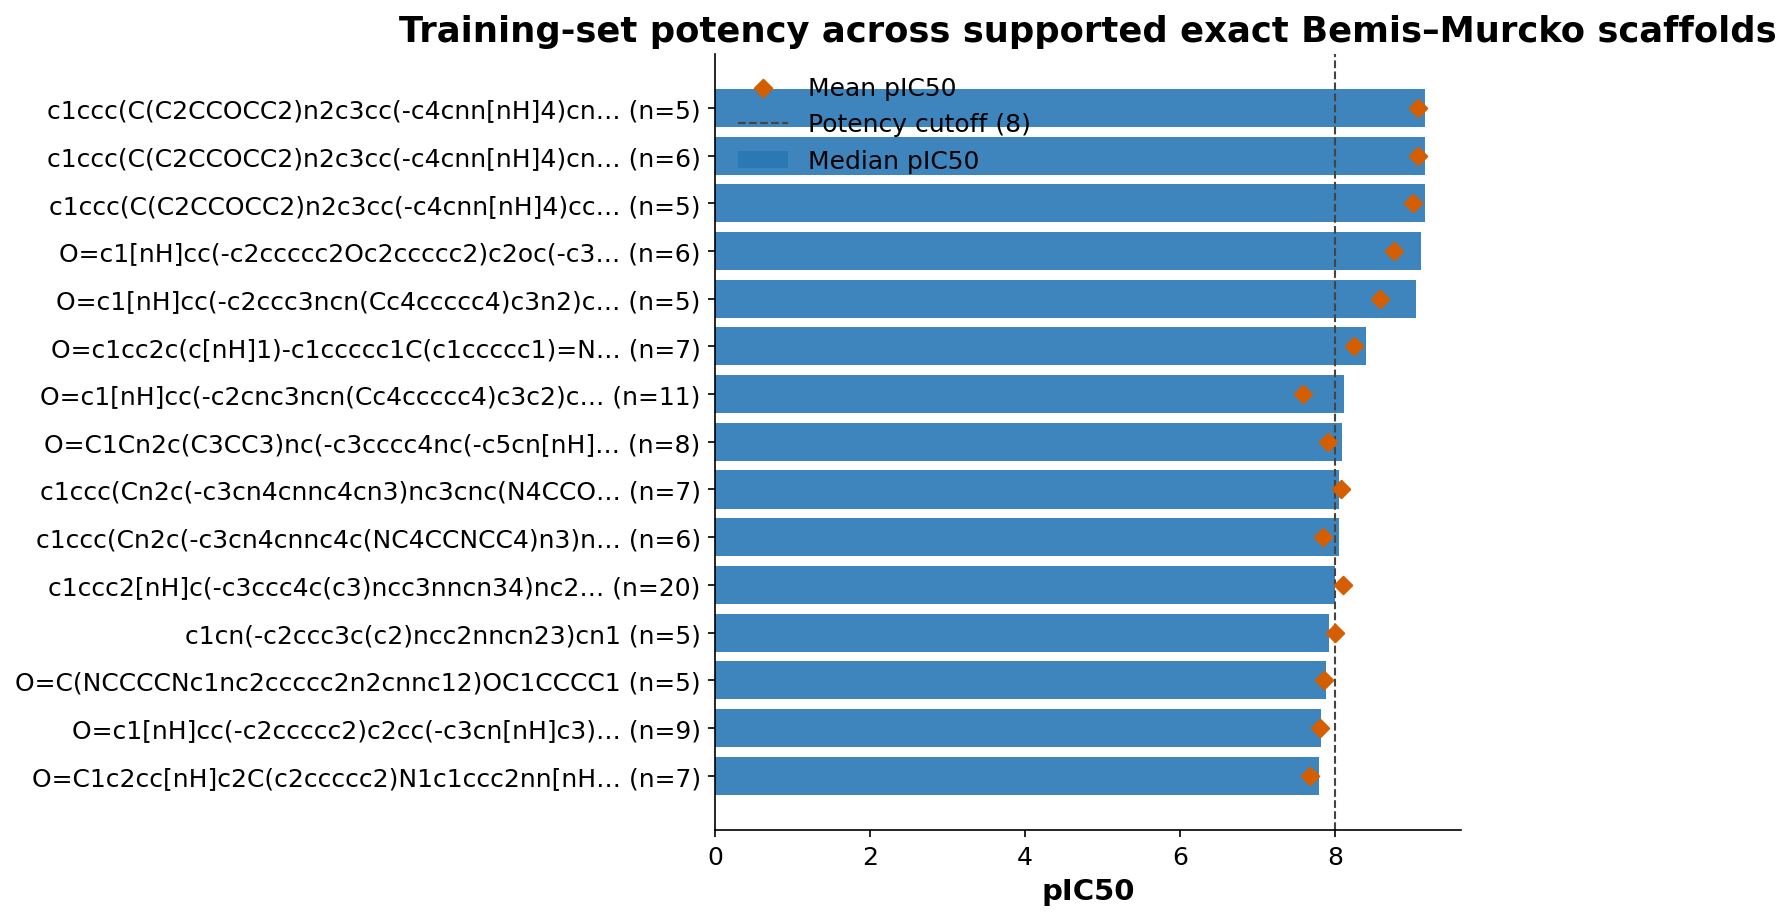

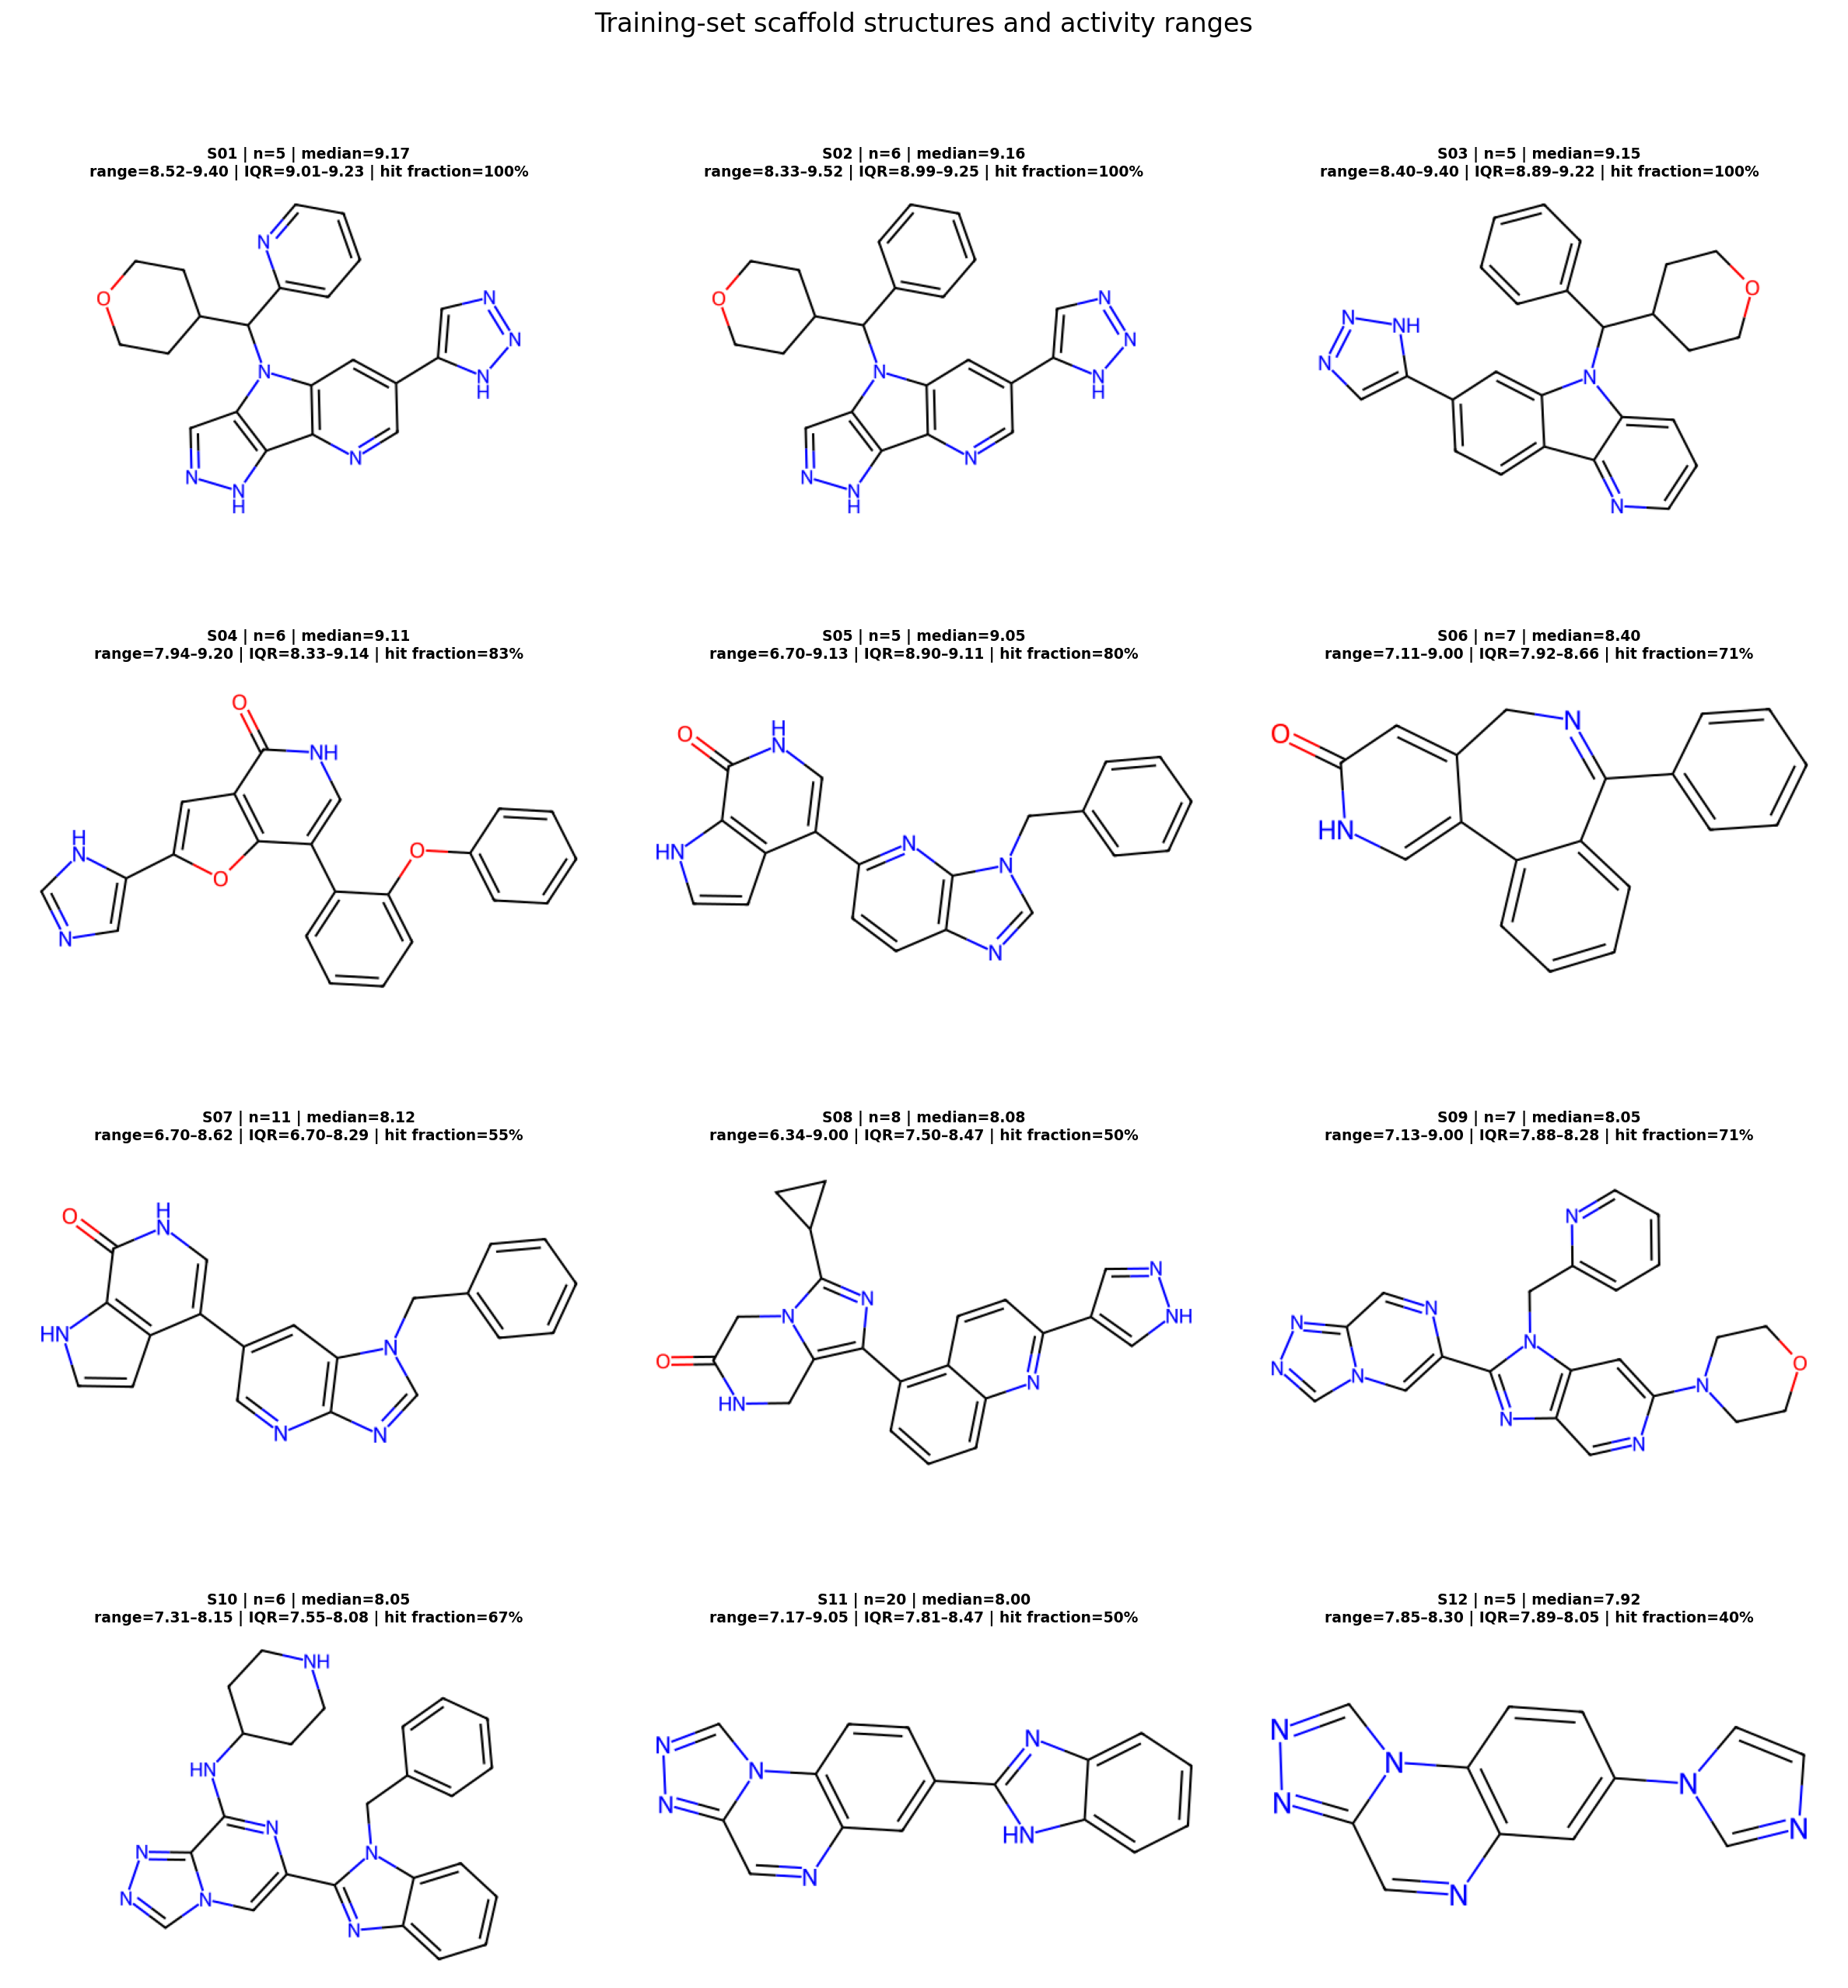

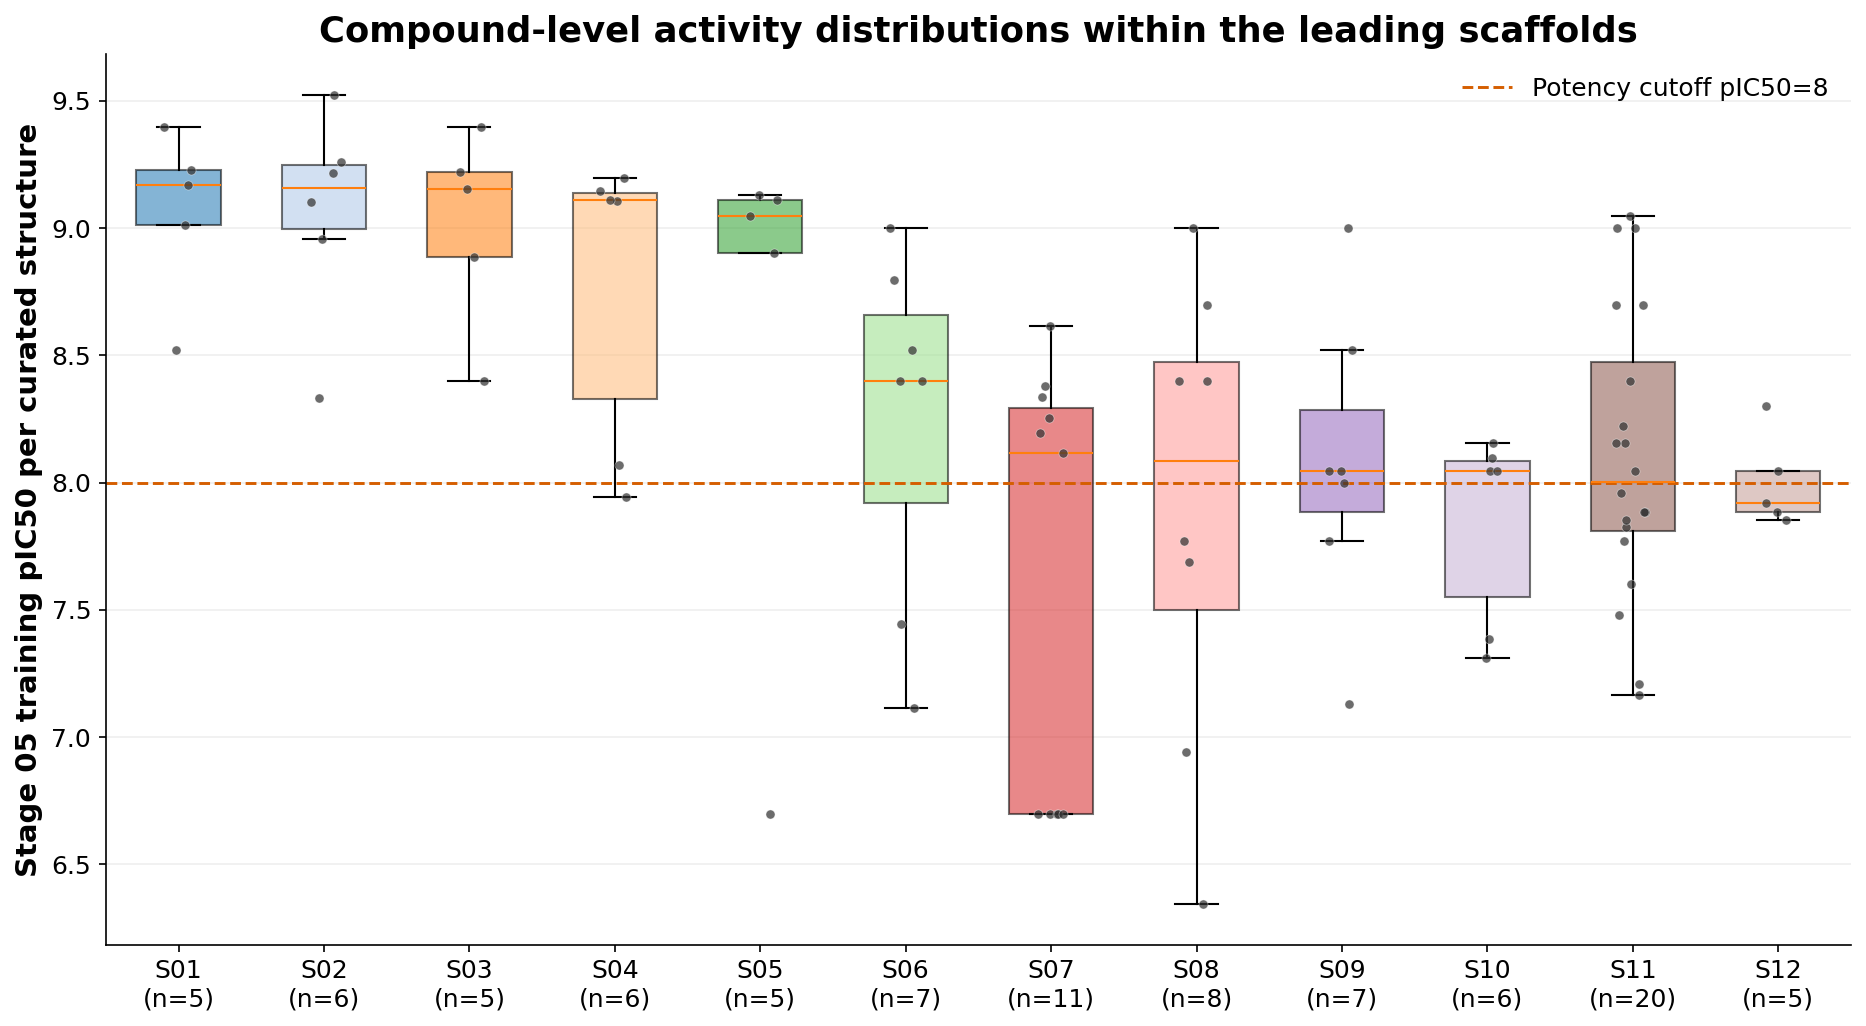

In [12]:
# 8. Visualize scaffold-level potency while retaining sample counts and uncertainty context.
plot_scaffolds=exact_summary.loc[(exact_summary.n_compounds>=min(MIN_SCAFFOLD_COUNTS)) & exact_summary.scaffold_type.eq("Bemis-Murcko")].head(15).copy()
if plot_scaffolds.empty:
    print("No exact scaffold meets the configured minimum count.")
else:
    fig,ax=plt.subplots(figsize=(10,max(5,0.42*len(plot_scaffolds))))
    p=plot_scaffolds.iloc[::-1]
    ax.barh(range(len(p)),p.median_pIC50,color="#2878B5",alpha=.9,label="Median pIC50")
    ax.scatter(p.mean_pIC50,range(len(p)),color="#D55E00",marker="D",s=35,label="Mean pIC50",zorder=3)
    ax.set_yticks(range(len(p)),[f"{s[:38]}… (n={n})" if len(s)>39 else f"{s} (n={n})" for s,n in zip(p.scaffold_smiles,p.n_compounds)])
    ax.axvline(POTENCY_CUTOFF,color="#444444",ls="--",lw=1,label=f"Potency cutoff ({POTENCY_CUTOFF:g})")
    ax.set_xlabel("pIC50")
    ax.set_title("Training-set potency across supported exact Bemis–Murcko scaffolds")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/"exact_scaffold_median_potency.png",dpi=300,bbox_inches="tight")
    plt.show()


# 15. Generate interpretable figures, including scaffold structures and their pIC50 ranges.
from io import BytesIO
from PIL import Image as PILImage
from rdkit.Chem.Draw import rdMolDraw2D

# Select supported exact scaffolds by median pIC50. The labels link structures to the table.
figure_scaffolds=exact_summary.loc[
    (exact_summary["n_compounds"]>=min(MIN_SCAFFOLD_COUNTS))
    & exact_summary["scaffold_type"].eq("Bemis-Murcko")
].head(12).copy().reset_index(drop=True)
figure_scaffolds["scaffold_label"]=[f"S{i+1:02d}" for i in range(len(figure_scaffolds))]
figure_scaffolds.to_csv(TABLE_DIR/"figure_scaffold_structure_key.csv",index=False)

# Figure A: actual scaffold drawings with sample size, median, range, IQR, and hit fraction.
if figure_scaffolds.empty:
    print("No exact scaffold meets the configured minimum count; structure gallery skipped.")
else:
    ncols=3
    nrows=int(np.ceil(len(figure_scaffolds)/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(16,4.4*nrows))
    axes=np.asarray(axes).reshape(-1)

    for ax,scaffold_row in zip(axes,figure_scaffolds.itertuples(index=False)):
        mol=Chem.MolFromSmiles(scaffold_row.scaffold_smiles)
        ax.axis("off")
        if mol is None:
            ax.text(0.5,0.5,"Scaffold could not be drawn",ha="center",va="center",transform=ax.transAxes)
            continue
        drawer=rdMolDraw2D.MolDraw2DCairo(520,300)
        drawer.DrawMolecule(mol)
        drawer.FinishDrawing()
        png_bytes=drawer.GetDrawingText()
        image=PILImage.open(BytesIO(png_bytes)).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"{scaffold_row.scaffold_label} | n={scaffold_row.n_compounds} | "
            f"median={scaffold_row.median_pIC50:.2f}\n"
            f"range={scaffold_row.min_pIC50:.2f}–{scaffold_row.max_pIC50:.2f} | "
            f"IQR={scaffold_row.q25_pIC50:.2f}–{scaffold_row.q75_pIC50:.2f} | "
            f"hit fraction={scaffold_row.hit_fraction:.0%}",
            fontsize=9,
            pad=7,
        )

    for ax in axes[len(figure_scaffolds):]:
        ax.axis("off")

    fig.suptitle(
        "Training-set scaffold structures and activity ranges",
        fontsize=16,
        y=1.01,
    )
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/"scaffold_structures_with_pIC50_ranges.png",dpi=300,bbox_inches="tight")
    fig.savefig(FIGURE_DIR/"scaffold_structures_with_pIC50_ranges.pdf",bbox_inches="tight")
    plt.show()

# Figure B: show the individual activities and distributions for the same scaffolds.
if not figure_scaffolds.empty:
    distributions=[]
    labels=[]
    for row in figure_scaffolds.itertuples(index=False):
        values=train.loc[train["exact_scaffold"].eq(row.scaffold_smiles),"pIC50"].astype(float).to_numpy()
        distributions.append(values)
        labels.append(f"{row.scaffold_label}\n(n={len(values)})")

    fig,ax=plt.subplots(figsize=(max(11,1.05*len(distributions)),7))
    boxes=ax.boxplot(distributions,showfliers=False,patch_artist=True,widths=0.58)
    palette=plt.get_cmap("tab20")
    for i,box in enumerate(boxes["boxes"]):
        box.set_facecolor(palette(i%20))
        box.set_alpha(0.55)
    rng=np.random.default_rng(42)
    for i,values in enumerate(distributions,1):
        jitter=rng.uniform(-0.12,0.12,size=len(values))
        ax.scatter(i+jitter,values,s=19,alpha=0.72,color="#333333",edgecolors="white",linewidths=0.25,zorder=3)
    ax.axhline(POTENCY_CUTOFF,color="#D55E00",linestyle="--",linewidth=1.4,
               label=f"Potency cutoff pIC50={POTENCY_CUTOFF:g}")
    ax.set_xticks(range(1,len(labels)+1))
    ax.set_xticklabels(labels)
    ax.set_ylabel("Stage 05 training pIC50 per curated structure")
    ax.set_title("Compound-level activity distributions within the leading scaffolds")
    ax.grid(axis="y",alpha=0.2)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/"scaffold_activity_distributions.png",dpi=300,bbox_inches="tight")
    fig.savefig(FIGURE_DIR/"scaffold_activity_distributions.pdf",bbox_inches="tight")
    plt.show()

### A.3 Rare scaffolds: cluster rather than drop

In [13]:
# 9. Cluster rare exact scaffolds by ECFP4/ECFP4-like Morgan similarity using Butina.
# Each rare scaffold is represented once by its Murcko core; acyclic molecules remain labeled separately.
fpgen=rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS,fpSize=FP_SIZE,includeChirality=FP_CHIRALITY)
rare_keys=set(exact_summary.loc[(exact_summary.n_compounds<min(MIN_SCAFFOLD_COUNTS)) & exact_summary.scaffold_type.eq("Bemis-Murcko"),"scaffold_smiles"].astype(str))
rare_rows=[]
for key in sorted(rare_keys):
    mol=Chem.MolFromSmiles(key)
    if mol is not None:
        rare_rows.append((key,int(exact_summary.loc[exact_summary.scaffold_smiles.eq(key) & exact_summary.scaffold_type.eq("Bemis-Murcko"),"n_compounds"].iloc[0]),fpgen.GetFingerprint(mol)))
if not rare_rows:
    rare_clusters=pd.DataFrame(columns=["rare_scaffold","n_compounds","butina_cluster","cluster_size"])
else:
    fps=[r[2] for r in rare_rows]
    dists=[]
    for i in range(1,len(fps)):
        sims=DataStructs.BulkTanimotoSimilarity(fps[i],fps[:i])
        dists.extend([1.0-s for s in sims])
    distance_cutoff=1.0-BUTINA_TANIMOTO_CUTOFF
    clusters=Butina.ClusterData(dists,len(fps),distance_cutoff,isDistData=True,reordering=True)
    records=[]
    for cl_id,cluster in enumerate(clusters,1):
        for idx in cluster:
            records.append({"rare_scaffold":rare_rows[idx][0],"n_compounds":rare_rows[idx][1],"butina_cluster":cl_id,
                            "cluster_size":len(cluster),"representative_scaffold":rare_rows[cluster[0]][0],
                            "morgan_radius":FP_RADIUS,"morgan_bits":FP_SIZE,"include_chirality":FP_CHIRALITY,
                            "tanimoto_cutoff":BUTINA_TANIMOTO_CUTOFF})
    rare_clusters=pd.DataFrame(records).sort_values(["cluster_size","butina_cluster"],ascending=[False,True])
rare_clusters.to_csv(TABLE_DIR/"rare_exact_scaffold_butina_clusters.csv",index=False)
print(f"Rare nonempty scaffolds clustered: {len(rare_rows):,}; Butina clusters: {rare_clusters.butina_cluster.nunique() if len(rare_clusters) else 0:,}")
print(f"Similarity cutoff: {BUTINA_TANIMOTO_CUTOFF:.2f}; acyclic structures were retained separately in scaffold membership.")
display(rare_clusters.head(25))

Rare nonempty scaffolds clustered: 1,818; Butina clusters: 521
Similarity cutoff: 0.55; acyclic structures were retained separately in scaffold membership.


,rare_scaffold,n_compounds,butina_cluster,cluster_size,representative_scaffold,morgan_radius,morgan_bits,include_chirality,tanimoto_cutoff
0,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
1,C=C(Oc1ccccc1)c1nc2c3c(ccc2n1C1CCCCC1)NCCC3,2,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
2,O=C(Cc1nc2c3c(ccc2n1C1CCCCC1)NCCC3)N1CCCC1,2,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
3,O=C(c1ccccc1)c1nc2c3c(ccc2n1C1CCCCC1)NCCC3,1,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
4,O=C1CC2(CCC2)CCN1Cc1nc2c3c(ccc2n1C1CCCCC1)NCCC3,1,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
5,O=C1CC2(CCN1Cc1nc3c4c(ccc3n1C1CCCCC1)NCCC4)CC2,1,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
6,O=C1CCCCN1CCc1nc2c3c(ccc2n1C1CCCCC1)NCCC3,2,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
7,O=C1CCCCN1Cc1nc2c3c(ccc2n1C1CCCCC1)NCCC3,1,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
8,O=C1CCCN1c1ccc(Cc2nc3c4c(ccc3n2C2CCCCC2)NCCC4)cc1,2,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55
9,O=C1Cc2ccccc2CN1Cc1nc2c3c(ccc2n1C1CCCCC1)NCCC3,1,1,109,c1ccc(Cc2nc3c4c(ccc3n2C2CCCC2)NCCC4)cc1,2,2048,True,0.55


### A.4 R-group decomposition inside the best-supported potent scaffolds

Top supported cores attempted: 5; decomposed substituent observations: 155
R-group combinations shown require n≥2.


,core_rank_by_median_pIC50,exact_scaffold,r_group,substituent_smiles,n_compounds,median_pIC50,mean_pIC50,hit_fraction,chembl_ids,delta_median_vs_core
0,1,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R1,CC(C)(O)[*:1],5,9.167491,9.066137,1.000000,CHEMBL5828701;CHEMBL5900152;CHEMBL5911397;CHEM...,0.000000
1,1,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R2,C[*:2],4,9.090360,8.983187,1.000000,CHEMBL5828701;CHEMBL5900152;CHEMBL5911397;CHEM...,-0.077131
3,1,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R3,C[*:3],5,9.167491,9.066137,1.000000,CHEMBL5828701;CHEMBL5900152;CHEMBL5911397;CHEM...,0.000000
4,1,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R4,C[*:4],5,9.167491,9.066137,1.000000,CHEMBL5828701;CHEMBL5900152;CHEMBL5911397;CHEM...,0.000000
7,1,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R5,F[*:5],3,9.013228,8.978016,1.000000,CHEMBL5900152;CHEMBL5911397;CHEMBL5952972,-0.154263
14,2,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R2,C[*:2],6,9.158522,9.064808,1.000000,CHEMBL5743600;CHEMBL5760907;CHEMBL5881619;CHEM...,0.000000
15,2,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R3,C[*:3],6,9.158522,9.064808,1.000000,CHEMBL5743600;CHEMBL5760907;CHEMBL5881619;CHEM...,0.000000
16,2,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)cnc3c3[nH]...,R4,C[*:4],6,9.158522,9.064808,1.000000,CHEMBL5743600;CHEMBL5760907;CHEMBL5881619;CHEM...,0.000000
17,3,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)ccc3c3nccc...,R1,CC(C)(O)[*:1],5,9.154902,9.011737,1.000000,CHEMBL5084636;CHEMBL5086429;CHEMBL5089688;CHEM...,0.000000
19,3,c1ccc(C(C2CCOCC2)n2c3cc(-c4cnn[nH]4)ccc3c3nccc...,R2,[H][*:2],4,9.053953,8.975946,1.000000,CHEMBL5084636;CHEMBL5086429;CHEMBL5089688;CHEM...,-0.100949


R-group contrasts are within-scaffold descriptive associations; low-count substituents remain in the membership table but are not ranked.


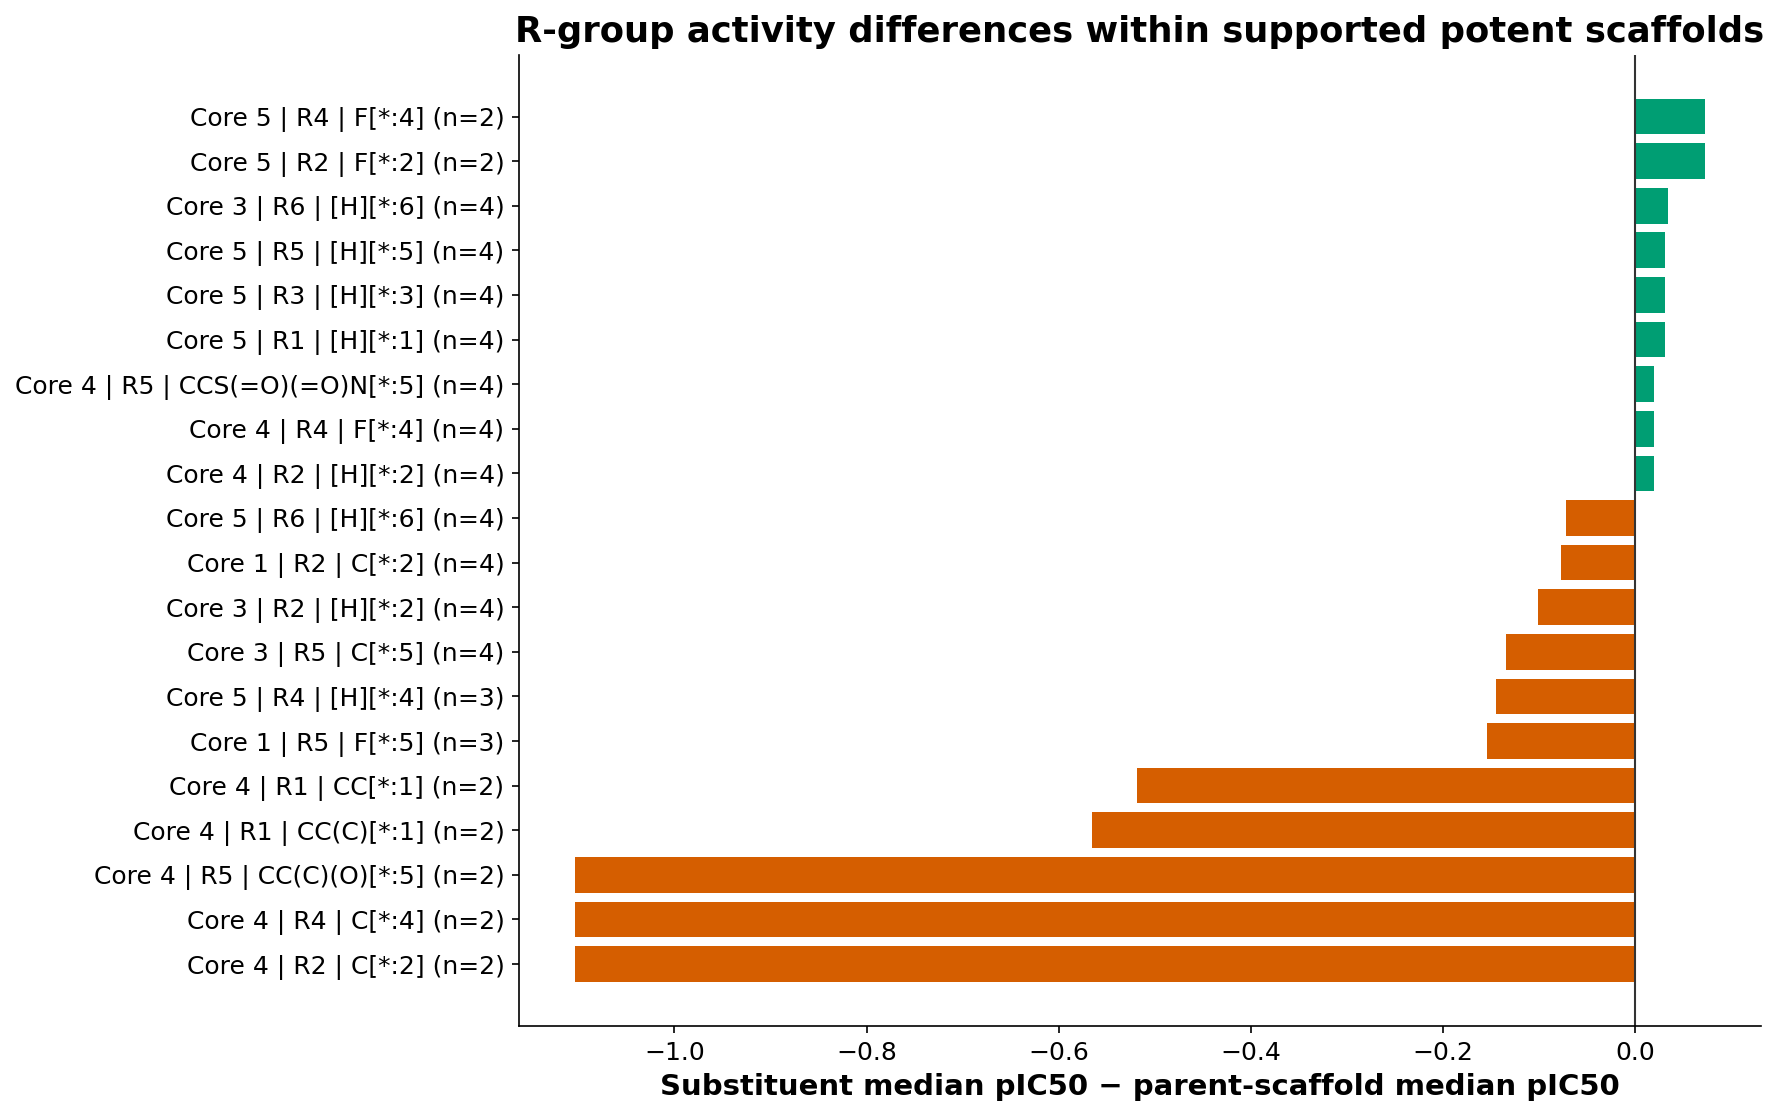

Interpretive figures saved under: C:\Users\USER\Documents\E\Code\outputs\11_sar_scaffold_reviewer\figures\A_scaffolds
Gallery structure labels and scaffold SMILES are cross-referenced in figure_scaffold_structure_key.csv.


In [14]:
# 14. R-group decomposition within the top supported exact scaffolds.
# Cores are exact Murcko scaffolds; activity summaries compare substituent labels only
# within the same core and require the configured minimum substituent count.
rgroup_rows=[]
selected_cores=exact_summary.loc[(exact_summary.n_compounds>=min(MIN_SCAFFOLD_COUNTS)) & exact_summary.scaffold_type.eq("Bemis-Murcko")].head(TOP_RGROUP_CORES)
for core_rank,core_row in enumerate(selected_cores.itertuples(index=False),1):
    core_smiles=str(core_row.scaffold_smiles)
    core=Chem.MolFromSmiles(core_smiles)
    if core is None: continue
    members=train.loc[train.exact_scaffold.eq(core_smiles)].copy()
    params=rdRGroupDecomposition.RGroupDecompositionParameters()
    params.removeHydrogensPostMatch=True
    decomp=rdRGroupDecomposition.RGroupDecomposition([core],params)
    kept=[]
    for ridx,r in enumerate(members.itertuples(index=False)):
        try:
            status=decomp.Add(r.mol)
            if status>=0: kept.append((ridx,r))
        except Exception:
            continue
    if not kept: continue
    try:
        processed=decomp.Process()
        rg_rows=decomp.GetRGroupsAsRows(asSmiles=True)
    except Exception as exc:
        warnings.warn(f"R-group decomposition failed for core {core_smiles[:35]}: {exc}")
        continue
    for (orig_idx,r),rg in zip(kept,rg_rows):
        for label,fragment in rg.items():
            if label=="Core": continue
            rgroup_rows.append({"core_rank_by_median_pIC50":core_rank,"exact_scaffold":core_smiles,
                                "chembl_id":r.chembl_id,"pIC50":float(r.pIC50),"r_group":str(label),
                                "substituent_smiles":str(fragment),"core_n":int(core_row.n_compounds)})
rgroup_members=pd.DataFrame(rgroup_rows)
if rgroup_members.empty:
    rgroup_summary=pd.DataFrame(columns=["exact_scaffold","r_group","substituent_smiles","n_compounds","median_pIC50","mean_pIC50","hit_fraction","delta_median_vs_core"])
else:
    rgroup_summary=(rgroup_members.groupby(["core_rank_by_median_pIC50","exact_scaffold","r_group","substituent_smiles"],dropna=False)
        .agg(n_compounds=("pIC50","size"),median_pIC50=("pIC50","median"),mean_pIC50=("pIC50","mean"),
             hit_fraction=("pIC50",lambda x:float((x>=POTENCY_CUTOFF).mean())),chembl_ids=("chembl_id",lambda x:";".join(sorted(set(x)))))
        .reset_index())
    core_medians=train.groupby("exact_scaffold").pIC50.median().to_dict()
    rgroup_summary["delta_median_vs_core"]=rgroup_summary.apply(lambda r:r.median_pIC50-core_medians.get(r.exact_scaffold,np.nan),axis=1)
    rgroup_summary=rgroup_summary.loc[rgroup_summary.n_compounds>=MIN_RGROUP_SUBSTITUENT_N].sort_values(
        ["core_rank_by_median_pIC50","r_group","median_pIC50"],ascending=[True,True,False])
rgroup_members.to_csv(TABLE_DIR/"top_scaffold_rgroup_membership.csv",index=False)
rgroup_summary.to_csv(TABLE_DIR/"top_scaffold_rgroup_activity_summary.csv",index=False)
print(f"Top supported cores attempted: {len(selected_cores)}; decomposed substituent observations: {len(rgroup_members):,}")
print(f"R-group combinations shown require n≥{MIN_RGROUP_SUBSTITUENT_N}.")
display(rgroup_summary.head(50))
print("R-group contrasts are within-scaffold descriptive associations; low-count substituents remain in the membership table but are not ranked.")


# Figure E: supported R-group differences within their parent scaffold.
if "rgroup_summary" in globals() and not rgroup_summary.empty:
    rg=rgroup_summary.copy()
    rg["plot_label"]=("Core "+rg["core_rank_by_median_pIC50"].astype(str)+" | "+rg["r_group"].astype(str)
                      +" | "+rg["substituent_smiles"].astype(str).str.slice(0,22)
                      +" (n="+rg["n_compounds"].astype(str)+")")
    rg["absolute_delta"]=rg["delta_median_vs_core"].abs()
    rg=rg.nlargest(20,"absolute_delta").sort_values("delta_median_vs_core")
    fig,ax=plt.subplots(figsize=(12,max(5,0.38*len(rg))))
    colors=["#009E73" if v>0 else "#D55E00" for v in rg["delta_median_vs_core"]]
    ax.barh(rg["plot_label"],rg["delta_median_vs_core"],color=colors)
    ax.axvline(0,color="#333333",linewidth=1)
    ax.set_xlabel("Substituent median pIC50 − parent-scaffold median pIC50")
    ax.set_title("R-group activity differences within supported potent scaffolds")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/"rgroup_activity_differences_within_scaffolds.png",dpi=300,bbox_inches="tight")
    fig.savefig(FIGURE_DIR/"rgroup_activity_differences_within_scaffolds.pdf",bbox_inches="tight")
    plt.show()

print(f"Interpretive figures saved under: {FIGURE_DIR}")
print("Gallery structure labels and scaffold SMILES are cross-referenced in figure_scaffold_structure_key.csv.")

### A.5 Chemical-space overview (UMAP, training only; exploratory)

c:\Users\USER\Documents\E\BRD4\brd4_env\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(


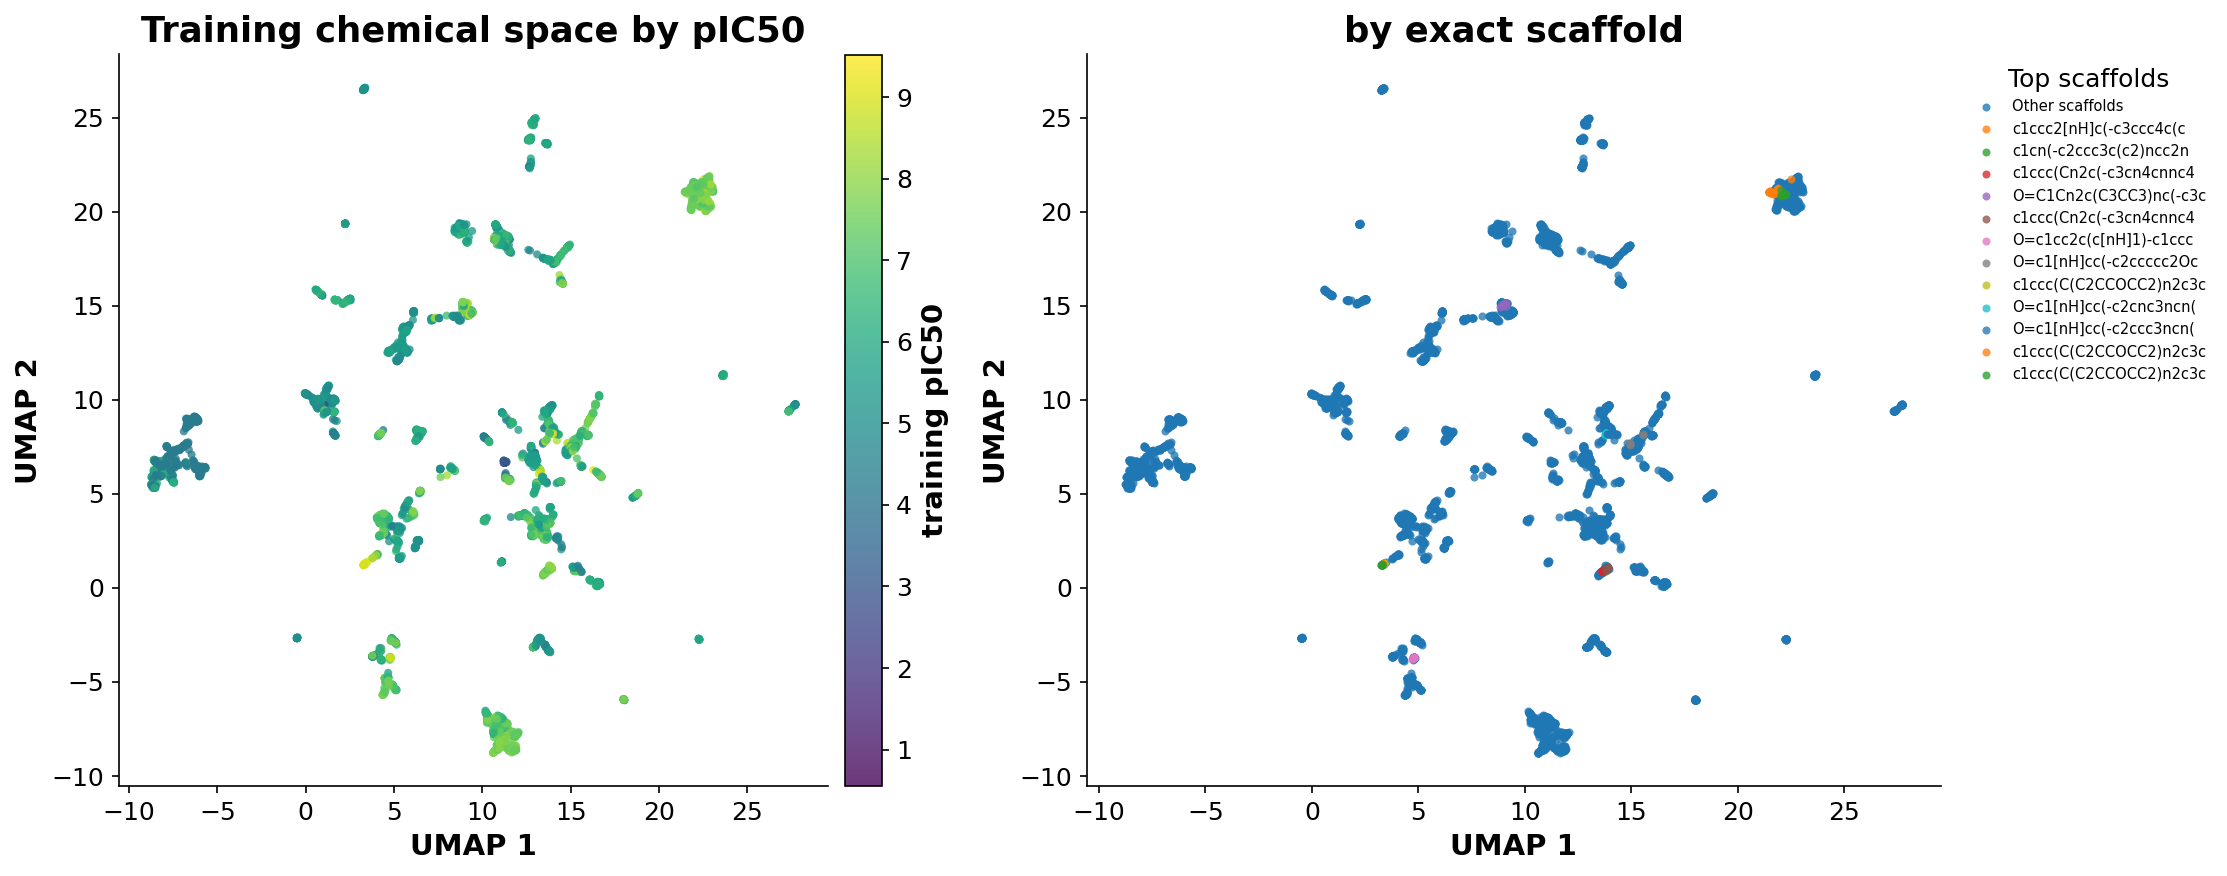

UMAP is an exploratory projection fitted to training structures only; colours do not influence coordinates.


In [15]:
try:
    import umap
except ImportError:
    umap = None
    print("umap-learn is not installed; UMAP skipped (python -m pip install umap-learn).")
if umap is not None:
    um = umap.UMAP(n_components=2, n_neighbors=min(30, len(train) - 1), min_dist=0.15, metric="jaccard",
                   random_state=SEED, n_jobs=1)
    xy = um.fit_transform(computed_bits)
    umap_results = train[["chembl_id", "canonical_smiles", "pIC50", "exact_scaffold", "generic_scaffold"]].copy()
    umap_results["UMAP1"], umap_results["UMAP2"] = xy[:, 0], xy[:, 1]
    top_scaf = figure_scaffolds["scaffold_smiles"].tolist()
    umap_results["scaffold_group"] = np.where(umap_results.exact_scaffold.isin(top_scaf), umap_results.exact_scaffold, "Other scaffolds")
    umap_results.to_csv(TABLE_DIR / "training_umap_coordinates.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sc = axes[0].scatter(umap_results.UMAP1, umap_results.UMAP2, c=umap_results.pIC50, cmap="viridis", s=15, alpha=.78, linewidths=0)
    fig.colorbar(sc, ax=axes[0], pad=.02).set_label("training pIC50")
    axes[0].set_title("Training chemical space by pIC50")
    for g, sub in umap_results.groupby("scaffold_group", sort=False):
        axes[1].scatter(sub.UMAP1, sub.UMAP2, s=15, alpha=.78, linewidths=0, label="Other scaffolds" if g == "Other scaffolds" else g[:22])
    axes[1].set_title("by exact scaffold"); axes[1].legend(title="Top scaffolds", fontsize=7, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    for ax in axes: ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
    fig.tight_layout(); save_both(fig, "training_ecfp4_umap"); plt.show()
    print("UMAP is an exploratory projection fitted to training structures only; colours do not influence coordinates.")

# Part B — What do Morgan bits mark: a series or a substituent? (training only)

Bits are prioritised from the **current saved models' own feature importances** (ExtraTrees and CatBoost, share-normalised and averaged) plus the configured and reviewer bits (**1722, 875, 1765, 2000**). For every bit we report:

1. global present/absent activity difference (Mann–Whitney, BH-adjusted);
2. enrichment among the ten best-supported scaffolds (Fisher, BH-adjusted);
3. within-scaffold present/absent contrasts and a sign test across scaffolds, which is the evidence for a substituent-level (rather than series-membership) effect;
4. the **atom environments** that set the bit in training molecules — a folded 2048-bit Morgan bit can be produced by several different environments, so a bit is not automatically one named substructure.

Bits outside the selected 250 are analysed too but flagged `in_fixed_250 = False`: the final models cannot have used them.

In [16]:
use_part("B_morgan_bits")
imp = {}
for name, b in model_bundles.items():
    est = b["model"]
    if hasattr(est, "named_steps"): est = list(est.named_steps.values())[-1]
    v = getattr(est, "feature_importances_", None)
    if v is not None and len(v) == len(selected):
        v = np.asarray(v, float); imp[name] = pd.Series(v / v.sum(), index=selected)
importance = pd.DataFrame(imp)
if importance.empty:
    print("No model exposes feature_importances_; only configured/reviewer bits will be analysed.")
    ranked_bits = []
else:
    importance["mean_share"] = importance.mean(axis=1)
    ranked_bits = importance.loc[importance.index.str.startswith("ecfp4_")].sort_values("mean_share", ascending=False).index.tolist()
    importance.sort_values("mean_share", ascending=False).to_csv(TABLE_DIR / "current_model_feature_importance_share.csv")
focus_bits = list(dict.fromkeys([f"ecfp4_{b}" for b in BIT_IDS] + FOCUS_MORGAN_BITS + ranked_bits[:N_TOP_MODEL_BITS]))[:MAX_FOCUS_BITS]
focus_bits = [b for b in focus_bits if b in bit_matrix.columns]
print("Focus bits:", focus_bits)
print("Not in fixed 250 (cannot be used by the final models):", [b for b in focus_bits if b not in selected])

bit_frame = bit_matrix.loc[train.chembl_id, focus_bits].copy()
bit_frame["pIC50_stage05"] = train.pIC50.to_numpy()
bit_frame["exact_scaffold"] = train.exact_scaffold.to_numpy()
bit_frame["exact_scaffold_type"] = train.exact_scaffold_type.to_numpy()

potent_scaffolds = set(exact_summary.loc[(exact_summary.n_compounds >= 5) & exact_summary.scaffold_type.eq("Bemis-Murcko")].head(10).scaffold_smiles)
potent = bit_frame.exact_scaffold.isin(potent_scaffolds)
rows = []
for bit in focus_bits:
    present = bit_frame[bit].astype(float) >= .5
    table = np.array([[(present & potent).sum(), (~present & potent).sum()], [(present & ~potent).sum(), (~present & ~potent).sum()]])
    odds, pf = fisher_exact(table) if table.sum() else (np.nan, np.nan)
    y1 = bit_frame.loc[present, "pIC50_stage05"].to_numpy(float); y0 = bit_frame.loc[~present, "pIC50_stage05"].to_numpy(float)
    pm = mannwhitneyu(y1, y0, alternative="two-sided").pvalue if len(y1) and len(y0) else np.nan
    rows.append({"feature": bit, "in_fixed_250": bit in selected,
                 "model_importance_share": float(importance["mean_share"].get(bit, np.nan)) if not importance.empty else np.nan,
                 "n_train": len(bit_frame), "present_n": int(present.sum()), "absent_n": int((~present).sum()),
                 "present_median_pIC50": np.median(y1) if len(y1) else np.nan, "absent_median_pIC50": np.median(y0) if len(y0) else np.nan,
                 "median_delta_present_minus_absent": np.median(y1) - np.median(y0) if len(y1) and len(y0) else np.nan,
                 "mannwhitney_p_activity": pm, "fisher_odds_ratio_top10_scaffolds": odds, "fisher_p_top10_scaffolds": pf,
                 "present_fraction_in_top10_scaffolds": float(present[potent].mean()) if potent.any() else np.nan,
                 "present_fraction_other_scaffolds": float(present[~potent].mean()) if (~potent).any() else np.nan})
bit_association = pd.DataFrame(rows)
bit_association["fdr_q_activity"] = bh_adjust(bit_association.mannwhitney_p_activity)
bit_association["fdr_q_top_scaffold_enrichment"] = bh_adjust(bit_association.fisher_p_top10_scaffolds)

wrows = []
bm = bit_frame.loc[bit_frame.exact_scaffold_type.eq("Bemis-Murcko")]
for bit in focus_bits:
    for scaf, g in bm.groupby("exact_scaffold"):
        pr = g.loc[g[bit] >= .5, "pIC50_stage05"]; ab = g.loc[g[bit] < .5, "pIC50_stage05"]
        if len(pr) >= 2 and len(ab) >= 2:
            wrows.append({"feature": bit, "exact_scaffold": scaf, "n_scaffold": len(g), "n_present": len(pr), "n_absent": len(ab),
                          "median_pIC50_present": pr.median(), "median_pIC50_absent": ab.median(),
                          "within_scaffold_delta_present_minus_absent": pr.median() - ab.median()})
within_scaffold = pd.DataFrame(wrows)
def _summ(g):
    d = g.within_scaffold_delta_present_minus_absent.to_numpy(float); npos, nneg = int((d > 0).sum()), int((d < 0).sum())
    return pd.Series({"n_scaffolds_tested": len(d), "median_within_scaffold_delta": float(np.median(d)),
                      "fraction_scaffolds_positive": npos / len(d), "fraction_scaffolds_negative": nneg / len(d),
                      "sign_test_p": binomtest(npos, npos + nneg, .5).pvalue if npos + nneg else np.nan})
if len(within_scaffold):
    within_summary = pd.DataFrame([{"feature": f, **_summ(g).to_dict()} for f, g in within_scaffold.groupby("feature")])
    within_summary["fdr_q_sign_test"] = bh_adjust(within_summary.sign_test_p)
else:
    within_summary = pd.DataFrame(columns=["feature", "n_scaffolds_tested", "median_within_scaffold_delta", "fraction_scaffolds_positive", "fraction_scaffolds_negative", "sign_test_p", "fdr_q_sign_test"])
bit_association = bit_association.merge(within_summary, on="feature", how="left")
bit_association.to_csv(TABLE_DIR / "morgan_bit_scaffold_associations.csv", index=False)
within_scaffold.to_csv(TABLE_DIR / "morgan_bit_within_scaffold_contrasts.csv", index=False)
display(bit_association[["feature", "in_fixed_250", "present_n", "median_delta_present_minus_absent", "fdr_q_activity",
                         "fisher_odds_ratio_top10_scaffolds", "fdr_q_top_scaffold_enrichment", "n_scaffolds_tested",
                         "median_within_scaffold_delta", "fraction_scaffolds_positive", "fdr_q_sign_test"]].round(3))
print("Reading: enrichment in top scaffolds ⇒ the bit tracks series membership; a consistent sign within scaffolds ⇒ substituent-level association. Neither is causal evidence of binding.")

Focus bits: ['ecfp4_1722', 'ecfp4_875', 'ecfp4_1765', 'ecfp4_2000', 'ecfp4_361', 'ecfp4_1164', 'ecfp4_318', 'ecfp4_917', 'ecfp4_5', 'ecfp4_1658', 'ecfp4_1696', 'ecfp4_1056', 'ecfp4_1409', 'ecfp4_1244']
Not in fixed 250 (cannot be used by the final models): []


,feature,in_fixed_250,present_n,median_delta_present_minus_absent,fdr_q_activity,fisher_odds_ratio_top10_scaffolds,fdr_q_top_scaffold_enrichment,n_scaffolds_tested,median_within_scaffold_delta,fraction_scaffolds_positive,fdr_q_sign_test
0,ecfp4_1722,True,2707,1.332,0.0,2.613,0.001,52.0,0.014,0.538,0.941
1,ecfp4_875,True,3951,1.250,0.0,3.694,0.003,41.0,0.075,0.610,0.055
2,ecfp4_1765,True,519,0.050,0.0,5.646,0.000,10.0,-0.097,0.300,0.941
3,ecfp4_2000,True,365,0.505,0.0,1.820,0.178,2.0,-0.604,0.000,0.941
4,ecfp4_361,True,910,-1.663,0.0,0.143,0.001,5.0,-0.063,0.200,0.941
5,ecfp4_1164,True,1165,1.512,0.0,2.713,0.001,NaN,NaN,NaN,NaN
6,ecfp4_318,True,450,-1.984,0.0,0.000,0.006,7.0,0.000,0.143,1.000
7,ecfp4_917,True,961,1.482,0.0,2.692,0.001,5.0,-0.225,0.400,1.000
8,ecfp4_5,True,319,0.744,0.0,2.110,0.090,12.0,0.310,0.583,0.941
9,ecfp4_1658,True,717,1.465,0.0,1.520,0.242,4.0,0.000,0.000,1.000


Reading: enrichment in top scaffolds ⇒ the bit tracks series membership; a consistent sign within scaffolds ⇒ substituent-level association. Neither is causal evidence of binding.


### B.2 Atom environments behind the reviewer bits (training molecules)

,bit,radius,center_atom,environment_smiles,n_molecules,median_pIC50,share_of_bit_carriers,in_fixed_250,n_distinct_environments_for_bit
1,ecfp4_1722,1,C,Cc,2650,6.886,0.979,True,11
2,ecfp4_1722,1,C,c(-c)(n)n,290,7.167,0.107,True,11
4,ecfp4_1722,2,C,C(C)OC,36,6.788,0.013,True,11
3,ecfp4_1722,1,C,c(C)(n)n,23,7.611,0.008,True,11
12,ecfp4_1765,1,C,C(c)n,350,6.260,0.674,True,10
11,ecfp4_1765,1,C,C(c)N,133,6.260,0.256,True,10
18,ecfp4_1765,2,C,c(nn)(c(C)c)c(n)n,17,7.886,0.033,True,10
14,ecfp4_1765,2,C,C(OC)[C@H](C)C,15,6.200,0.029,True,10
24,ecfp4_2000,1,C,C(c)(C)C,306,7.039,0.838,True,12
29,ecfp4_2000,2,C,c(-c(c)c)(nc)c(N)n,41,5.305,0.112,True,12


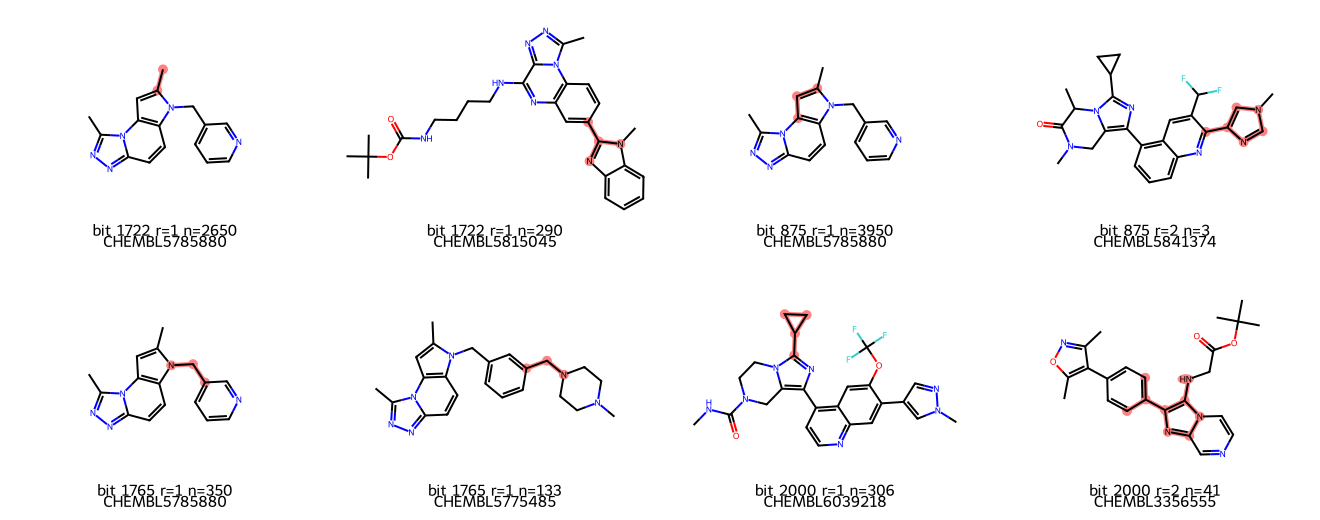

If a bit has several comparably common environments, describe it as a hashed collision of environments, not as one substructure.


In [17]:
def env_smiles(mol, atom_idx, radius):
    if radius == 0:
        atoms, bonds = [atom_idx], []
    else:
        bonds = list(Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom_idx))
        atoms = {atom_idx}
        for bi in bonds:
            bd = mol.GetBondWithIdx(bi); atoms.update((bd.GetBeginAtomIdx(), bd.GetEndAtomIdx()))
        atoms = sorted(atoms)
    smi = Chem.MolFragmentToSmiles(mol, atomsToUse=list(atoms), bondsToUse=bonds, rootedAtAtom=atom_idx, canonical=True)
    return smi, list(atoms)

env_rows, env_examples = [], {}
for bit_id in BIT_IDS:
    feature = f"ecfp4_{bit_id}"
    for cid, mol, y in zip(train.chembl_id, train.mol, train.pIC50):
        if not bit_matrix.at[cid, feature]: continue
        ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()
        MORGAN.GetFingerprint(mol, additionalOutput=ao)
        for atom_idx, radius in ao.GetBitInfoMap().get(bit_id, ()):
            smi, atoms = env_smiles(mol, atom_idx, radius)
            env_rows.append({"bit": feature, "chembl_id": cid, "radius": radius, "center_atom": mol.GetAtomWithIdx(atom_idx).GetSymbol(),
                             "environment_smiles": smi, "pIC50": y})
            env_examples.setdefault((feature, radius, smi), (cid, mol, atoms))
env_long = pd.DataFrame(env_rows)
if env_long.empty:
    environment_summary = pd.DataFrame(columns=["bit", "radius", "center_atom", "environment_smiles", "n_molecules", "median_pIC50", "share_of_bit_carriers", "in_fixed_250"])
else:
    environment_summary = (env_long.groupby(["bit", "radius", "center_atom", "environment_smiles"])
                           .agg(n_molecules=("chembl_id", "nunique"), median_pIC50=("pIC50", "median")).reset_index())
    carriers = env_long.groupby("bit").chembl_id.nunique()
    environment_summary["share_of_bit_carriers"] = environment_summary.n_molecules / environment_summary.bit.map(carriers)
    environment_summary["in_fixed_250"] = environment_summary.bit.isin(selected)
    environment_summary = environment_summary.sort_values(["bit", "n_molecules"], ascending=[True, False])
    environment_summary["n_distinct_environments_for_bit"] = environment_summary.groupby("bit").environment_smiles.transform("nunique")
env_long.to_csv(TABLE_DIR / "reviewer_bit_environments_long.csv", index=False)
environment_summary.to_csv(TABLE_DIR / "reviewer_bit_environment_summary.csv", index=False)
display(environment_summary.groupby("bit", sort=False).head(4).round(3))

mols, legends, hl = [], [], []
for bit_id in BIT_IDS:
    feature = f"ecfp4_{bit_id}"
    top = environment_summary.loc[environment_summary.bit.eq(feature)].head(2)
    for r in top.itertuples():
        cid, mol, atoms = env_examples[(feature, r.radius, r.environment_smiles)]
        mols.append(mol); hl.append(atoms)
        legends.append(f"bit {bit_id} r={r.radius} n={r.n_molecules}\n{cid}")
if mols:
    grid = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(330, 260), legends=legends, highlightAtomLists=hl)
    grid_to_png(grid, FIGURE_DIR / "reviewer_bit_environments.png"); display(grid)
print("If a bit has several comparably common environments, describe it as a hashed collision of environments, not as one substructure.")

### B.3 Bit prevalence by scaffold and between- vs within-scaffold effects

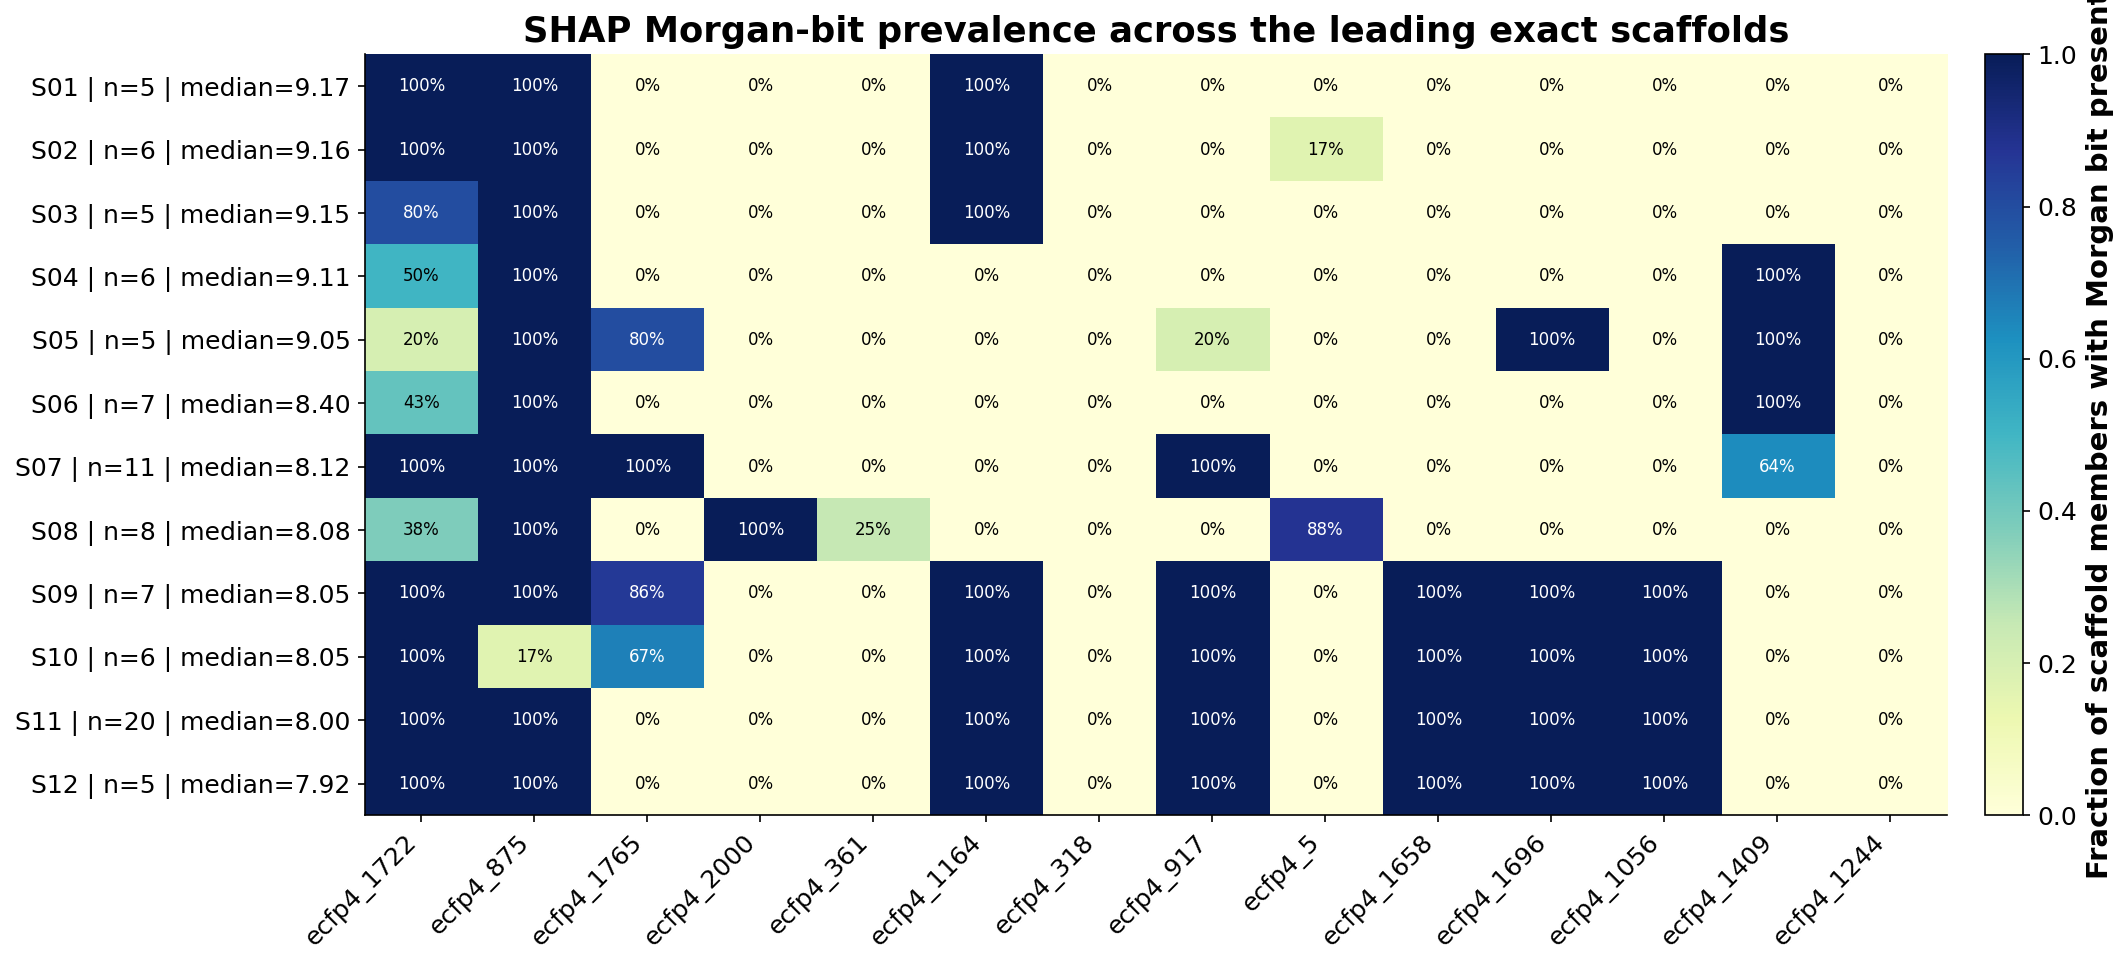

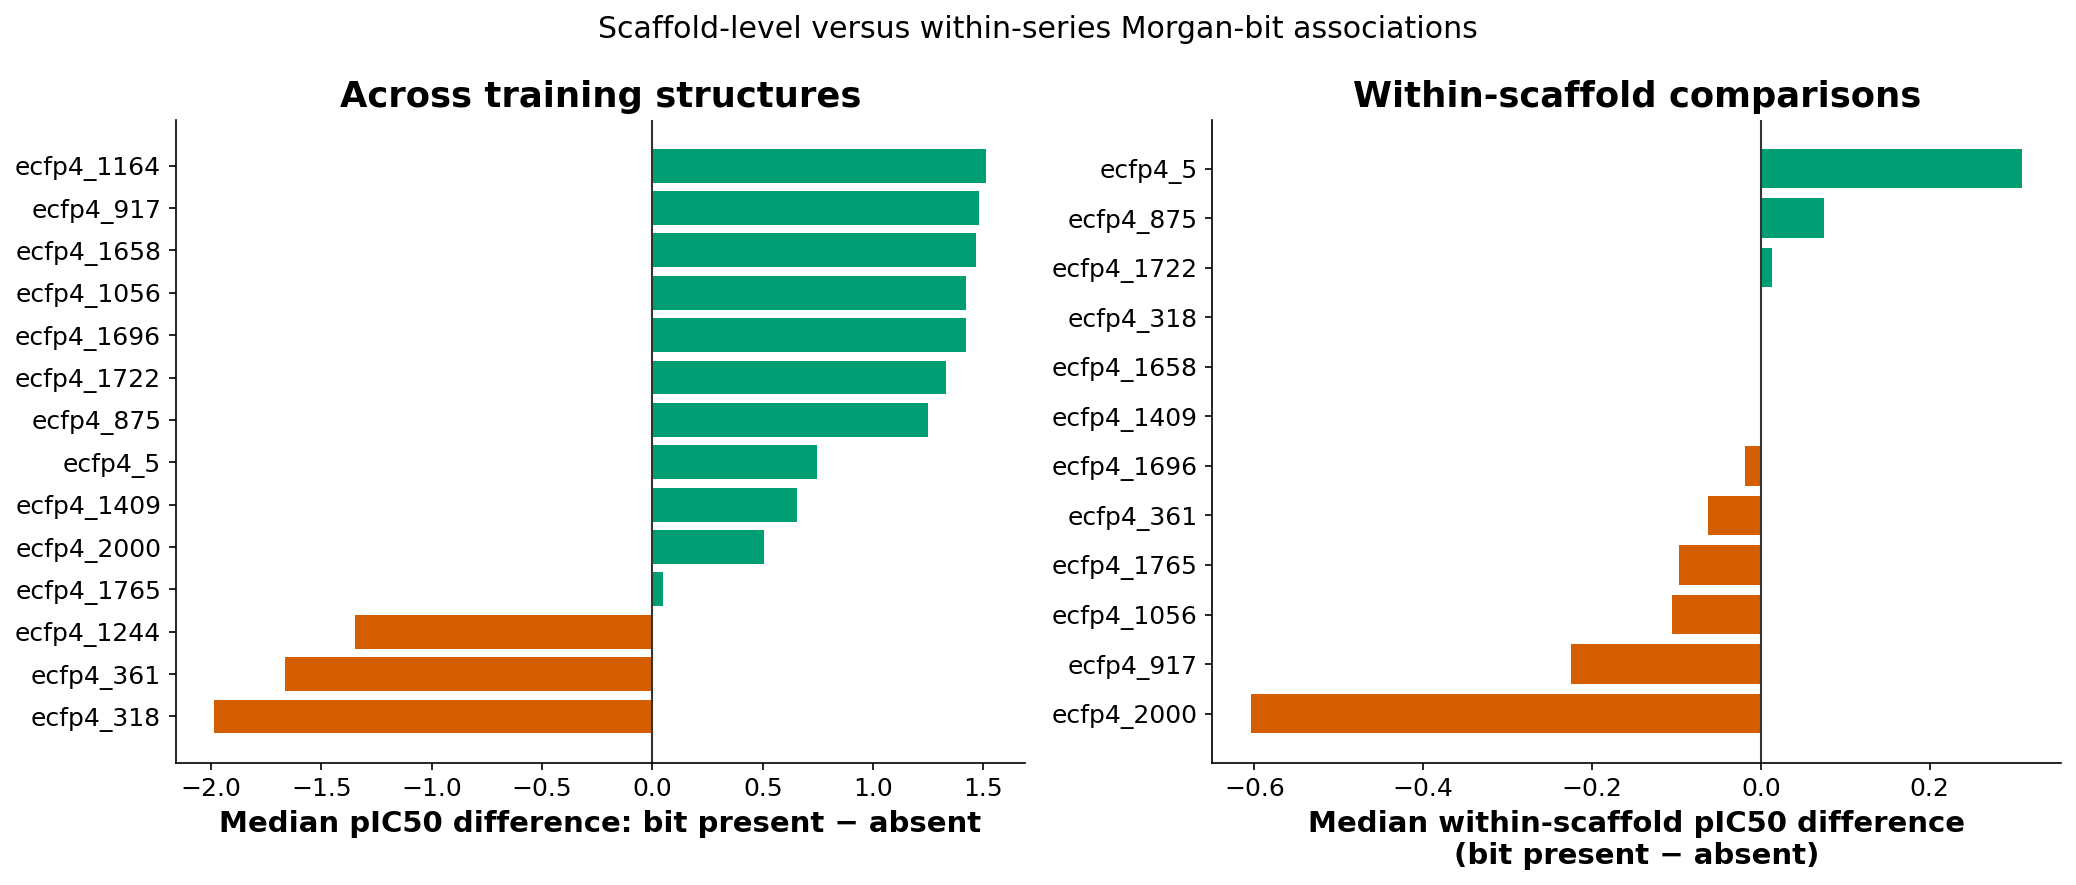

Figures saved under C:\Users\USER\Documents\E\Code\outputs\11_sar_scaffold_reviewer\figures\B_morgan_bits


In [18]:
# Figure C: prevalence of the leading Morgan SHAP bits within each leading scaffold.
if not figure_scaffolds.empty and "bit_frame" in globals() and focus_bits:
    heat=[]
    ylabels=[]
    for row in figure_scaffolds.itertuples(index=False):
        group=bit_frame.loc[bit_frame["exact_scaffold"].eq(row.scaffold_smiles)]
        if group.empty:
            prevalence=np.full(len(focus_bits),np.nan)
        else:
            prevalence=group[focus_bits].astype(float).mean(axis=0).to_numpy()
        heat.append(prevalence)
        ylabels.append(f"{row.scaffold_label} | n={row.n_compounds} | median={row.median_pIC50:.2f}")

    heat=np.asarray(heat,dtype=float)
    fig,ax=plt.subplots(figsize=(max(10,1.1*len(focus_bits)),max(5,0.55*len(ylabels))))
    masked=np.ma.masked_invalid(heat)
    image=ax.imshow(masked,aspect="auto",cmap="YlGnBu",vmin=0,vmax=1)
    ax.set_xticks(range(len(focus_bits)))
    ax.set_xticklabels(focus_bits,rotation=45,ha="right")
    ax.set_yticks(range(len(ylabels)))
    ax.set_yticklabels(ylabels)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            if np.isfinite(heat[i,j]):
                ax.text(j,i,f"{heat[i,j]:.0%}",ha="center",va="center",fontsize=8,
                        color="white" if heat[i,j]>0.58 else "black")
    colorbar=fig.colorbar(image,ax=ax,pad=0.02)
    colorbar.set_label("Fraction of scaffold members with Morgan bit present")
    ax.set_title("SHAP Morgan-bit prevalence across the leading exact scaffolds")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/"scaffold_morgan_bit_prevalence_heatmap.png",dpi=300,bbox_inches="tight")
    fig.savefig(FIGURE_DIR/"scaffold_morgan_bit_prevalence_heatmap.pdf",bbox_inches="tight")
    plt.show()



# Figure D: global bit association compared with within-scaffold activity contrasts.
if "bit_association" in globals() and not bit_association.empty:
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    between=bit_association.sort_values("median_delta_present_minus_absent")
    colors=["#009E73" if v>0 else "#D55E00" for v in between["median_delta_present_minus_absent"].fillna(0)]
    axes[0].barh(between["feature"],between["median_delta_present_minus_absent"],color=colors)
    axes[0].axvline(0,color="#333333",linewidth=1)
    axes[0].set_xlabel("Median pIC50 difference: bit present − absent")
    axes[0].set_title("Across training structures")

    if "within_summary" in globals() and not within_summary.empty:
        within=within_summary.sort_values("median_within_scaffold_delta")
        colors=["#009E73" if v>0 else "#D55E00" for v in within["median_within_scaffold_delta"].fillna(0)]
        axes[1].barh(within["feature"],within["median_within_scaffold_delta"],color=colors)
        axes[1].axvline(0,color="#333333",linewidth=1)
        axes[1].set_xlabel("Median within-scaffold pIC50 difference\n(bit present − absent)")
        axes[1].set_title("Within-scaffold comparisons")
    else:
        axes[1].text(0.5,0.5,"No within-scaffold comparisons met the minimum count.",
                     ha="center",va="center",transform=axes[1].transAxes)
        axes[1].set_axis_off()
    fig.suptitle("Scaffold-level versus within-series Morgan-bit associations")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/"morgan_bit_between_within_scaffold_effects.png",dpi=300,bbox_inches="tight")
    fig.savefig(FIGURE_DIR/"morgan_bit_between_within_scaffold_effects.pdf",bbox_inches="tight")
    plt.show()


print(f"Figures saved under {FIGURE_DIR}")

# Part C — Matched molecular pairs, activity cliffs and stereochemical pairs (training + saved OOF only)

Primary cliff: chirality-aware Morgan Tanimoto ≥ 0.90 **and** |ΔpIC50| ≥ 2.0 (≥100-fold). The sensitivity grid (0.85/0.90 × 1.0/2.0 pIC50) is declared in the configuration cell above. MMP transformations need ≥ 3 pairs and ≥ 60 % direction agreement; depleting rules are tested in the negative direction. Pairs share molecules and series, so counts are descriptive rather than independent observations, and assay heterogeneity can create apparent cliffs.

In [19]:
use_part("C_mmp_cliffs")
# --- single-cut RDKit MMPA, every stage diagnosed (unchanged from the validated Stage 11 code)
# 4. Generate RDKit MMPA fragments and diagnose every fragmentation stage.
# Preflight the installed RDKit return format before processing the full dataset.
MMPA_PATTERN = "[#6+0;!$(*=,#[!#6])]!@!=!#[*]"
MAX_CUTTABLE_BONDS_PER_MOLECULE = 30
cut_pattern = Chem.MolFromSmarts(MMPA_PATTERN)
if cut_pattern is None:
    raise RuntimeError("RDKit could not parse the declared MMPA cut pattern.")


def _as_mol(value):
    """Convert an RDKit Mol or SMILES-like fragment to a copy of a Mol."""
    if isinstance(value, Chem.Mol):
        return Chem.Mol(value)
    if isinstance(value, str) and value.strip():
        return Chem.MolFromSmiles(value)
    return None


def _canonical_fragment(mol_fragment):
    if mol_fragment is None:
        return None
    return Chem.MolToSmiles(mol_fragment, canonical=True, isomericSmiles=True)


def _parse_mmpa_record(fragment_record):
    """Return oriented (core, substituent) SMILES and a parse status.

    Some RDKit builds represent an undefined single-cut core as None; with
    resultsAsMols=False, other builds serialize that same missing core as ''.
    In both cases the second field is a dot-disconnected pair of fragments.
    """
    try:
        first_piece, second_piece = fragment_record
    except (TypeError, ValueError):
        return [], "record_not_a_pair", False

    missing_core = first_piece is None or (
        isinstance(first_piece, str) and not first_piece.strip()
    )
    if missing_core:
        combined_mol = _as_mol(second_piece)
        if combined_mol is None:
            return [], "combined_fragment_unparseable", True
        components = Chem.GetMolFrags(
            combined_mol, asMols=True, sanitizeFrags=True
        )
        if len(components) != 2:
            return [], f"expected_2_components_found_{len(components)}", True
        frag_a, frag_b = (_canonical_fragment(component) for component in components)
        if not frag_a or not frag_b:
            return [], "empty_component_smiles", True
        # Follow Notebook 8's MMP convention: the larger disconnected piece
        # is the shared core and the smaller piece is the substituent. Heavy
        # atom counts replace string character counts; canonical SMILES break
        # ties deterministically.
        paired = sorted(
            [(frag_a, components[0]), (frag_b, components[1])],
            key=lambda item: (item[1].GetNumHeavyAtoms(), item[0]),
        )
        substituent, core = paired[0][0], paired[-1][0]
        return [(core, substituent)], "two_component_record", True

    core_mol, substituent_mol = _as_mol(first_piece), _as_mol(second_piece)
    if core_mol is not None and substituent_mol is not None:
        pieces = [
            (_canonical_fragment(core_mol), core_mol),
            (_canonical_fragment(substituent_mol), substituent_mol),
        ]
        if all(smiles for smiles, _ in pieces):
            pieces.sort(key=lambda item: (item[1].GetNumHeavyAtoms(), item[0]))
            return [(pieces[-1][0], pieces[0][0])], "separate_core_and_substituent", True
    return [], "separate_fragments_unparseable", True


# Fail fast with a small diagnostic rather than spending several minutes on a
# full run if this RDKit build returns an unexpected fragment representation.
preflight_found = False
preflight_examples = []
for row in train.itertuples(index=False):
    mol = row.mol
    if mol.GetNumHeavyAtoms() < 6:
        continue
    if not mol.HasSubstructMatch(cut_pattern):
        continue
    try:
        sample_records = rdMMPA.FragmentMol(
            mol, maxCuts=1, maxCutBonds=MAX_CUTTABLE_BONDS_PER_MOLECULE,
            pattern=MMPA_PATTERN, resultsAsMols=False,
        )
    except Exception as exc:
        raise RuntimeError(
            f"MMPA preflight failed for {row.chembl_id}: {type(exc).__name__}: {exc}"
        ) from exc
    for sample_record in sample_records[:10]:
        parsed, parse_status, _ = _parse_mmpa_record(sample_record)
        if len(preflight_examples) < 3:
            preflight_examples.append({
                "record_repr": repr(sample_record)[:500],
                "parse_status": parse_status,
                "n_oriented_fragment_pairs": len(parsed),
            })
        if parsed:
            preflight_found = True
            break
    if preflight_found:
        break
if not preflight_found:
    raise RuntimeError(
        "MMPA preflight found cuttable bonds but could not interpret any returned "
        f"fragment record. Inspect these examples before running the full cell: {preflight_examples}"
    )
print("MMPA parser preflight passed:", preflight_examples)

core_members = defaultdict(lambda: defaultdict(set))
fragment_rows, diagnostic_rows = [], []
fragment_failures = 0
small_molecules_skipped = 0
for row in tqdm(train.itertuples(index=False), total=len(train), desc="Single-cut MMPA fragmentation"):
    mol = row.mol
    n_cuttable_bonds = len(mol.GetSubstructMatches(cut_pattern, uniquify=True))
    diagnostic = {
        "chembl_id": str(row.chembl_id),
        "n_heavy_atoms": int(mol.GetNumHeavyAtoms()),
        "n_cuttable_bonds": n_cuttable_bonds,
        "n_raw_fragment_records": 0,
        "n_unpacked_fragment_records": 0,
        "n_two_component_cut_records": 0,
        "n_valid_fragment_records": 0,
        "n_uninterpreted_fragment_records": 0,
        "status": "not_processed",
        "error": "",
    }
    if mol.GetNumHeavyAtoms() < 6:
        small_molecules_skipped += 1
        diagnostic["status"] = "skipped_under_6_heavy_atoms"
        diagnostic_rows.append(diagnostic)
        continue
    if n_cuttable_bonds > MAX_CUTTABLE_BONDS_PER_MOLECULE:
        diagnostic["status"] = "skipped_cut_bond_cap"
        diagnostic_rows.append(diagnostic)
        continue
    try:
        fragments = rdMMPA.FragmentMol(
            mol, maxCuts=1, maxCutBonds=MAX_CUTTABLE_BONDS_PER_MOLECULE,
            pattern=MMPA_PATTERN, resultsAsMols=False,
        )
        diagnostic["n_raw_fragment_records"] = len(fragments)
    except Exception as exc:
        fragment_failures += 1
        diagnostic["status"] = "fragmenter_exception"
        diagnostic["error"] = f"{type(exc).__name__}: {exc}"
        diagnostic_rows.append(diagnostic)
        continue

    unique_for_molecule = set()
    for fragment_record in fragments:
        parsed_pairs, parse_status, unpacked = _parse_mmpa_record(fragment_record)
        diagnostic["n_unpacked_fragment_records"] += int(unpacked)
        if parse_status == "two_component_record":
            diagnostic["n_two_component_cut_records"] += 1
        if not parsed_pairs:
            diagnostic["n_uninterpreted_fragment_records"] += 1
            if not diagnostic["error"]:
                diagnostic["error"] = parse_status
            continue
        unique_for_molecule.update(parsed_pairs)

    diagnostic["n_valid_fragment_records"] = len(unique_for_molecule)
    diagnostic["status"] = "fragments_created" if unique_for_molecule else (
        "fragment_records_not_interpreted" if diagnostic["n_raw_fragment_records"] else "no_matching_cut_bonds"
    )
    diagnostic_rows.append(diagnostic)
    for core, substituent in unique_for_molecule:
        core_members[core][str(row.chembl_id)].add(substituent)
        fragment_rows.append({"chembl_id": str(row.chembl_id), "core": core, "substituent": substituent})

fragment_diagnostics = pd.DataFrame(diagnostic_rows)
fragment_diagnostics.to_csv(TABLE_DIR / "mmp_fragmentation_diagnostics.csv", index=False)
fragment_table = pd.DataFrame(fragment_rows, columns=["chembl_id", "core", "substituent"]).drop_duplicates()
pair_rows, seen_pair_keys = [], set()
train_by_id = train.set_index("chembl_id")
for core, members in tqdm(core_members.items(), desc="Pairing shared MMP cores"):
    molecule_ids = sorted(members)
    if len(molecule_ids) < 2:
        continue
    for id_1, id_2 in itertools.combinations(molecule_ids, 2):
        for frag_1 in sorted(members[id_1]):
            for frag_2 in sorted(members[id_2]):
                if frag_1 == frag_2:
                    continue
                if frag_1 < frag_2:
                    id_from, frag_from, id_to, frag_to = id_1, frag_1, id_2, frag_2
                else:
                    id_from, frag_from, id_to, frag_to = id_2, frag_2, id_1, frag_1
                key = (core, id_from, frag_from, id_to, frag_to)
                if key in seen_pair_keys:
                    continue
                seen_pair_keys.add(key)
                y_from = float(train_by_id.at[id_from, "pIC50"])
                y_to = float(train_by_id.at[id_to, "pIC50"])
                pair_rows.append({
                    "core": core, "fragment_from": frag_from, "fragment_to": frag_to,
                    "chembl_id_from": id_from, "chembl_id_to": id_to,
                    "smiles_from": str(train_by_id.at[id_from, "canonical_smiles"]),
                    "smiles_to": str(train_by_id.at[id_to, "canonical_smiles"]),
                    "pIC50_from": y_from, "pIC50_to": y_to,
                    "delta_pIC50_to_minus_from": y_to - y_from,
                })
                if len(pair_rows) > 2_000_000:
                    raise RuntimeError("MMP pair count exceeded two million; review cut settings. No results were silently truncated.")

mmp_pair_columns = [
    "core", "fragment_from", "fragment_to", "chembl_id_from", "chembl_id_to",
    "smiles_from", "smiles_to", "pIC50_from", "pIC50_to", "delta_pIC50_to_minus_from",
]
mmp_pairs = pd.DataFrame(pair_rows, columns=mmp_pair_columns)
fragment_table.to_csv(TABLE_DIR / "mmp_fragments_training.csv", index=False)
mmp_pairs.to_csv(TABLE_DIR / "mmp_pairs_training.csv", index=False)
shared_ids = {chembl_id for ids in core_members.values() if len(ids) >= 2 for chembl_id in ids}
mmp_run_summary = pd.DataFrame([{
    "training_molecules": len(train),
    "molecules_with_fragments": fragment_table.chembl_id.nunique(),
    "unique_cores": len(core_members),
    "cores_shared_by_multiple_molecules": sum(len(v) >= 2 for v in core_members.values()),
    "unique_mmp_pairs": len(mmp_pairs),
    "fragmented_molecules_not_in_any_shared_core": len(set(fragment_table.chembl_id) - shared_ids),
    "molecules_with_no_matching_cut_bonds": int((fragment_diagnostics.status == "no_matching_cut_bonds").sum()),
    "fragmentation_failures": fragment_failures,
    "molecules_skipped_under_6_heavy_atoms": small_molecules_skipped,
    "molecules_with_uninterpreted_records": int((fragment_diagnostics.n_uninterpreted_fragment_records > 0).sum()),
    "uninterpreted_fragment_record_count": int(fragment_diagnostics.n_uninterpreted_fragment_records.sum()),
    "max_cuts": 1,
    "max_cuttable_bonds_per_molecule": MAX_CUTTABLE_BONDS_PER_MOLECULE,
    "mmpa_pattern": MMPA_PATTERN,
    "chirality_preserved_in_fragment_keys": True,
}])
mmp_run_summary.to_csv(TABLE_DIR / "mmp_run_summary.csv", index=False)
display(mmp_run_summary)
display(fragment_diagnostics.status.value_counts(dropna=False).rename_axis("fragmentation_status").to_frame("n_molecules"))
display(fragment_diagnostics.head())
display(mmp_pairs.head(10))
if mmp_pairs.empty:
    print("No exact single-cut MMPs were found. Review mmp_fragmentation_diagnostics.csv. The notebook will continue with activity cliffs, stereo pairs, and OOF analyses.")
else:
    print(f"Found {len(mmp_pairs):,} exact single-cut pairs. Positive delta means fragment_from → fragment_to raised pIC50.")

MMPA parser preflight passed: [{'record_repr': "('', 'C[*:1].Cc1nnc2ccc3c(cc([*:1])n3Cc3cccnc3)n12')", 'parse_status': 'two_component_record', 'n_oriented_fragment_pairs': 1}]


Single-cut MMPA fragmentation:   0%|          | 0/5134 [00:00<?, ?it/s]

Pairing shared MMP cores:   0%|          | 0/30111 [00:00<?, ?it/s]

,training_molecules,molecules_with_fragments,unique_cores,cores_shared_by_multiple_molecules,unique_mmp_pairs,fragmented_molecules_not_in_any_shared_core,molecules_with_no_matching_cut_bonds,fragmentation_failures,molecules_skipped_under_6_heavy_atoms,molecules_with_uninterpreted_records,uninterpreted_fragment_record_count,max_cuts,max_cuttable_bonds_per_molecule,mmpa_pattern,chirality_preserved_in_fragment_keys
0,5134,5132,30111,3513,91965,378,0,0,1,0,0,1,30,"[#6+0;!$(*=,#[!#6])]!@!=!#[*]",True


,n_molecules
fragmentation_status,
fragments_created,5132
skipped_under_6_heavy_atoms,1
skipped_cut_bond_cap,1


,chembl_id,n_heavy_atoms,n_cuttable_bonds,n_raw_fragment_records,n_unpacked_fragment_records,n_two_component_cut_records,n_valid_fragment_records,n_uninterpreted_fragment_records,status,error
0,CHEMBL5785880,21,4,4,4,4,4,0,fragments_created,
1,CHEMBL5990153,26,5,5,5,5,5,0,fragments_created,
2,CHEMBL5775485,29,7,7,7,7,7,0,fragments_created,
3,CHEMBL5843627,23,6,6,6,6,6,0,fragments_created,
4,CHEMBL5838062,25,8,7,7,7,7,0,fragments_created,


,core,fragment_from,fragment_to,chembl_id_from,chembl_id_to,smiles_from,smiles_to,pIC50_from,pIC50_to,delta_pIC50_to_minus_from
0,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,COC1CN(Cc2cccc([*:1])c2)C1,CHEMBL5750578,CHEMBL5763669,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,COC1CN(Cc2cccc(Cn3c(C)cc4c3ccc3nnc(C)n34)c2)C1,6.259637,6.259637,0.0
1,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,c1cc(CN2CCOCC2)cc([*:1])c1,CHEMBL5750578,CHEMBL5768794,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(CN2CCOCC2)c1,6.259637,6.259637,0.0
2,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CN1CCN(Cc2cccc([*:1])c2)CC1,CHEMBL5750578,CHEMBL5775485,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(CN2CCN(C)CC2)c1,6.259637,6.259637,0.0
3,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,c1cncc([*:1])c1,CHEMBL5750578,CHEMBL5785880,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccnc1,6.259637,6.259637,0.0
4,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CCNC(=O)c1cccc([*:1])c1,CHEMBL5750578,CHEMBL5818417,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,CCNC(=O)c1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,6.259637,6.259637,0.0
5,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,O[C@H]1C[C@H](NCc2cccc([*:1])c2)C1,CHEMBL5750578,CHEMBL5826838,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(CN[C@H]2C[C@H]...,6.259637,6.259637,0.0
6,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CN(C)Cc1ccc([*:1])cc1,CHEMBL5750578,CHEMBL5838062,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1ccc(CN(C)C)cc1,6.259637,6.259637,0.0
7,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,O=C(NO)c1cccc([*:1])c1,CHEMBL5750578,CHEMBL5852449,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(C(=O)NO)c1,6.259637,6.259637,0.0
8,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,N#Cc1cccc([*:1])c1,CHEMBL5750578,CHEMBL5899431,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(C#N)c1,6.259637,6.259637,0.0
9,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CNC(=O)c1cccc([*:1])c1,CHEMBL5750578,CHEMBL5906945,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,CNC(=O)c1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,6.259637,6.259637,0.0


Found 91,965 exact single-cut pairs. Positive delta means fragment_from → fragment_to raised pIC50.


In [20]:
# 5. Summarize supported enriching and depleting transformations.
def summarize_transformation(group):
    delta = group.delta_pIC50_to_minus_from.astype(float)
    fraction_positive = float((delta > 0).mean())
    fraction_negative = float((delta < 0).mean())
    consistency = max(fraction_positive, fraction_negative)
    mean_delta = float(delta.mean())
    if len(delta) >= MMP_MIN_PAIRS and consistency >= MMP_MIN_DIRECTION_CONSISTENCY:
        if mean_delta > 0 and fraction_positive >= MMP_MIN_DIRECTION_CONSISTENCY:
            status = "enriching"
        elif mean_delta < 0 and fraction_negative >= MMP_MIN_DIRECTION_CONSISTENCY:
            status = "depleting"
        else:
            status = "inconsistent"
    else:
        status = "insufficient_support"
    return pd.Series({
        "n_pairs": len(delta), "n_distinct_cores": group.core.nunique(),
        "mean_delta_pIC50": mean_delta,
        "sd_delta_pIC50": float(delta.std(ddof=1)) if len(delta) > 1 else 0.0,
        "median_delta_pIC50": float(delta.median()),
        "fraction_positive": fraction_positive, "fraction_negative": fraction_negative,
        "direction_consistency": consistency, "status": status,
    })

transformation_rows = []
for (fragment_from, fragment_to), group in mmp_pairs.groupby(
    ["fragment_from", "fragment_to"], sort=False, dropna=False
):
    row = summarize_transformation(group)
    row["fragment_from"], row["fragment_to"] = fragment_from, fragment_to
    transformation_rows.append(row)
transformation_columns = [
    "fragment_from", "fragment_to", "n_pairs", "n_distinct_cores", "mean_delta_pIC50",
    "sd_delta_pIC50", "median_delta_pIC50", "fraction_positive", "fraction_negative",
    "direction_consistency", "status",
]
transformations = pd.DataFrame(transformation_rows, columns=transformation_columns).sort_values(
    ["status", "mean_delta_pIC50"], ascending=[True, False], kind="stable"
).reset_index(drop=True)
transformations.to_csv(TABLE_DIR / "mmp_transformation_summary_all.csv", index=False)
enriching = transformations.loc[transformations.status == "enriching"].sort_values(
    ["mean_delta_pIC50", "n_pairs"], ascending=[False, False], kind="stable"
)
depleting = transformations.loc[transformations.status == "depleting"].sort_values(
    ["mean_delta_pIC50", "n_pairs"], ascending=[True, False], kind="stable"
)
enriching.to_csv(TABLE_DIR / "mmp_enriching_transformations.csv", index=False)
depleting.to_csv(TABLE_DIR / "mmp_depleting_transformations.csv", index=False)
print(f"All directed fragment transformations: {len(transformations):,}")
print(f"Supported enriching transformations: {len(enriching):,}")
print(f"Supported depleting transformations: {len(depleting):,}")
if transformations.empty:
    print("No matched transformations are available; the remaining Stage 11 analyses can continue.")
display(enriching.head(15))
display(depleting.head(15))

All directed fragment transformations: 71,995
Supported enriching transformations: 1,236
Supported depleting transformations: 1,015


,fragment_from,fragment_to,n_pairs,n_distinct_cores,mean_delta_pIC50,sd_delta_pIC50,median_delta_pIC50,fraction_positive,fraction_negative,direction_consistency,status
1015,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,3,3,2.286404,0.512731,2.471047,1.0,0.0,1.0,enriching
1016,CC(C)(C)OC(=O)[*:1],O=C(NCC(F)F)[*:1],3,3,2.080388,2.953587,0.418570,1.0,0.0,1.0,enriching
1017,CC(C)(C)OC(=O)C[*:1],O=C(C[*:1])NCC(F)F,3,3,2.080388,2.953587,0.418570,1.0,0.0,1.0,enriching
1018,CC(C)(C)OC(=O)[*:1],C[C@@H](O)CNC(=O)[*:1],3,3,2.020592,2.991464,0.316270,1.0,0.0,1.0,enriching
1019,CC(C)(C)OC(=O)C[*:1],C[C@@H](O)CNC(=O)C[*:1],3,3,2.020592,2.991464,0.316270,1.0,0.0,1.0,enriching
1020,CC(C)(C)OC(=O)[*:1],C[C@H](O)CNC(=O)[*:1],3,3,1.924720,2.979884,0.207125,1.0,0.0,1.0,enriching
1021,CC(C)(C)OC(=O)C[*:1],C[C@H](O)CNC(=O)C[*:1],3,3,1.924720,2.979884,0.207125,1.0,0.0,1.0,enriching
1022,CC(C)(C)NC(=O)NCCC[*:1],CC(C)[C@H](O)C(=O)NCCC[*:1],3,3,1.086889,0.127931,1.096910,1.0,0.0,1.0,enriching
1023,CC(C)(C)NC(=O)NCC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],3,3,1.086889,0.127931,1.096910,1.0,0.0,1.0,enriching
1024,CC(C)(C)NC(=O)NC[*:1],CC(C)[C@H](O)C(=O)NC[*:1],3,3,1.086889,0.127931,1.096910,1.0,0.0,1.0,enriching


,fragment_from,fragment_to,n_pairs,n_distinct_cores,mean_delta_pIC50,sd_delta_pIC50,median_delta_pIC50,fraction_positive,fraction_negative,direction_consistency,status
1014,CC1C(=O)N(C)Cc2c([*:1])nc(C3CC3)n21,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,3,3,-1.664991,1.021338,-2.251638,0.000000,1.000000,1.000000,depleting
1013,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,C[C@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,5,5,-1.528331,2.079303,-2.409087,0.200000,0.800000,0.800000,depleting
1012,CC(C)(C)S(=O)(=O)N[*:1],O=S(=O)(N[*:1])c1ccccc1,3,3,-1.457994,0.647562,-1.657577,0.000000,1.000000,1.000000,depleting
1011,c1cc2cc([*:1])ccc2[nH]1,c1ccc(C[*:1])cc1,3,3,-1.314798,1.138686,-1.962929,0.000000,0.666667,0.666667,depleting
1010,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CC3)n21,C[C@H]1C(=O)N(C)Cc2c([*:1])nc(C3CC3)n21,3,3,-1.300423,2.392812,-2.656098,0.333333,0.666667,0.666667,depleting
1009,COc1cc(=O)n(C)cc1[*:1],Cn1cc([*:1])c2ccccc2c1=O,3,3,-1.292209,0.774371,-0.851869,0.000000,1.000000,1.000000,depleting
1008,CC(C)(C)N[*:1],c1ccc(CN[*:1])cc1,3,3,-1.278257,0.243938,-1.361057,0.000000,1.000000,1.000000,depleting
1006,CC(C)(C)S(=O)(=O)Nc1cc(N[*:1])ccc1Cl,Cc1ccc(N[*:1])cc1S(=O)(=O)NC1CCC1,4,4,-1.256133,0.317595,-1.255942,0.000000,1.000000,1.000000,depleting
1007,CC(C)(C)S(=O)(=O)Nc1cc([*:1])ccc1Cl,Cc1ccc([*:1])cc1S(=O)(=O)NC1CCC1,4,4,-1.256133,0.317595,-1.255942,0.000000,1.000000,1.000000,depleting
1005,CC(C)Oc1cccc([*:1])c1,c1cc2c(cc1[*:1])OCO2,3,3,-1.244515,0.903907,-1.579572,0.000000,1.000000,1.000000,depleting


In [21]:
# 6. Exact chirality-aware pairwise similarity search and cliff sensitivity.
# Similarities are calculated for every unordered training pair. Only pairs at
# the lowest declared similarity AND activity-gap thresholds are retained.
y_train = train.pIC50.to_numpy(dtype=float)
n_train = len(train)
min_similarity = min(SIMILARITY_THRESHOLDS)
min_gap = min(ACTIVITY_GAP_THRESHOLDS)
similar_pair_counts = {threshold: 0 for threshold in SIMILARITY_THRESHOLDS}
cliff_candidate_rows = []

for i in tqdm(range(n_train - 1), desc="All-pairs Morgan Tanimoto search"):
    similarities = np.asarray(
        DataStructs.BulkTanimotoSimilarity(fp_vectors[i], fp_vectors[i + 1:]),
        dtype=np.float32,
    )
    for threshold in SIMILARITY_THRESHOLDS:
        similar_pair_counts[threshold] += int(np.count_nonzero(similarities >= threshold))
    keep_similarity = np.flatnonzero(similarities >= min_similarity)
    if not len(keep_similarity):
        continue
    j_values = keep_similarity + i + 1
    deltas = y_train[j_values] - y_train[i]
    keep_gap = np.flatnonzero(np.abs(deltas) >= min_gap)
    for offset in keep_gap:
        j = int(j_values[offset])
        cliff_candidate_rows.append({
            "chembl_id_a": str(train.chembl_id.iloc[i]),
            "chembl_id_b": str(train.chembl_id.iloc[j]),
            "smiles_a": str(train.canonical_smiles.iloc[i]),
            "smiles_b": str(train.canonical_smiles.iloc[j]),
            "pIC50_a": float(y_train[i]),
            "pIC50_b": float(y_train[j]),
            "delta_pIC50_b_minus_a": float(deltas[offset]),
            "absolute_delta_pIC50": float(abs(deltas[offset])),
            "tanimoto_chiral": float(similarities[keep_similarity[offset]]),
            "fold_a": int(fold_by_id[str(train.chembl_id.iloc[i])]),
            "fold_b": int(fold_by_id[str(train.chembl_id.iloc[j])]),
            "same_evaluation_fold": bool(
                fold_by_id[str(train.chembl_id.iloc[i])] == fold_by_id[str(train.chembl_id.iloc[j])]
            ),
        })
    if len(cliff_candidate_rows) > MAX_RETAINED_SIMILAR_PAIRS:
        raise RuntimeError(
            "Retained similar/high-gap pair count exceeded the declared safety limit. "
            "No pairs were truncated; review the analysis settings before rerunning."
        )

similar_pairs = pd.DataFrame(cliff_candidate_rows)
if similar_pairs.empty:
    similar_pairs = pd.DataFrame(columns=[
        "chembl_id_a", "chembl_id_b", "smiles_a", "smiles_b", "pIC50_a", "pIC50_b",
        "delta_pIC50_b_minus_a", "absolute_delta_pIC50", "tanimoto_chiral",
        "fold_a", "fold_b", "same_evaluation_fold",
    ])
similar_pairs.to_csv(TABLE_DIR / "similar_pairs_minimum_sensitivity_thresholds.csv", index=False)

sensitivity_rows = []
for sim_threshold in SIMILARITY_THRESHOLDS:
    for gap_threshold in ACTIVITY_GAP_THRESHOLDS:
        subset = similar_pairs.loc[
            (similar_pairs.tanimoto_chiral >= sim_threshold)
            & (similar_pairs.absolute_delta_pIC50 >= gap_threshold)
        ]
        members = set(subset.chembl_id_a) | set(subset.chembl_id_b)
        sensitivity_rows.append({
            "similarity_threshold_inclusive": sim_threshold,
            "activity_gap_threshold_inclusive_pIC50": gap_threshold,
            "n_similar_pairs_at_similarity_threshold": similar_pair_counts[sim_threshold],
            "n_activity_cliffs": len(subset),
            "n_unique_cliff_molecules": len(members),
            "n_same_evaluation_fold_pairs": int(subset.same_evaluation_fold.sum()),
            "n_cross_evaluation_fold_pairs": int((~subset.same_evaluation_fold).sum()),
        })
cliff_sensitivity = pd.DataFrame(sensitivity_rows)
cliff_sensitivity.to_csv(TABLE_DIR / "activity_cliff_threshold_sensitivity.csv", index=False)
primary_cliffs = similar_pairs.loc[
    (similar_pairs.tanimoto_chiral >= PRIMARY_SIMILARITY)
    & (similar_pairs.absolute_delta_pIC50 >= PRIMARY_ACTIVITY_GAP)
].sort_values(
    ["absolute_delta_pIC50", "tanimoto_chiral"], ascending=[False, False], kind="stable"
).reset_index(drop=True)
primary_cliffs.insert(0, "cliff_rank", np.arange(1, len(primary_cliffs) + 1))
primary_cliffs.to_csv(TABLE_DIR / "primary_activity_cliffs_training.csv", index=False)

display(cliff_sensitivity)
for _t, _n in similar_pair_counts.items(): print(f"Exact similar-pair count at similarity ≥{_t:.2f}: {_n:,}")

print(f"Primary training cliffs (≥0.90, ≥2.0 pIC50): {len(primary_cliffs):,}")
display(primary_cliffs.head(15))

All-pairs Morgan Tanimoto search:   0%|          | 0/5133 [00:00<?, ?it/s]

,similarity_threshold_inclusive,activity_gap_threshold_inclusive_pIC50,n_similar_pairs_at_similarity_threshold,n_activity_cliffs,n_unique_cliff_molecules,n_same_evaluation_fold_pairs,n_cross_evaluation_fold_pairs
0,0.85,1.0,1464,154,232,96,58
1,0.85,2.0,1464,26,48,22,4
2,0.90,1.0,461,44,78,23,21
3,0.90,2.0,461,6,10,3,3


Exact similar-pair count at similarity ≥0.85: 1,464
Exact similar-pair count at similarity ≥0.90: 461
Primary training cliffs (≥0.90, ≥2.0 pIC50): 6


,cliff_rank,chembl_id_a,chembl_id_b,smiles_a,smiles_b,pIC50_a,pIC50_b,delta_pIC50_b_minus_a,absolute_delta_pIC50,tanimoto_chiral,fold_a,fold_b,same_evaluation_fold
0,1,CHEMBL3650963,CHEMBL3650964,Cc1nn(C2CC2)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(C)c3...,Cc1nn(C2CC2)c2c1[C@@H](c1ccc(Cl)cc1)N(c1cc(C)c...,4.522879,7.886057,3.363178,3.363178,0.964286,4,2,False
1,2,CHEMBL3650937,CHEMBL3650969,Cc1nn(-c2ccnn2C)c2c1C(c1ccc(Cl)cc1)N(c1cc(C)c3...,Cc1nn(-c2ccnn2C)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(...,7.823909,4.602060,-3.221849,3.221849,0.967213,5,3,False
2,3,CHEMBL3650963,CHEMBL3650938,Cc1nn(C2CC2)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(C)c3...,Cc1nn(C2CC2)c2c1C(c1ccc(Cl)cc1)N(c1cc(C)c3nnc(...,4.522879,7.721246,3.198368,3.198368,0.964286,4,4,True
3,4,CHEMBL3650969,CHEMBL3650970,Cc1nn(-c2ccnn2C)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(...,Cc1nn(-c2ccnn2C)c2c1[C@@H](c1ccc(Cl)cc1)N(c1cc...,4.602060,7.602060,3.000000,3.000000,0.967213,3,3,True
4,5,CHEMBL3650944,CHEMBL3650945,COc1ncc(-n2nc(C)c3c2C(=O)N(c2cc(C)c(=O)n(C)c2)...,COc1ncc(-n2nc(C)c3c2C(=O)N(c2cc(C)c(=O)n(C)c2)...,5.107905,7.602060,2.494155,2.494155,0.969231,4,4,True
5,6,CHEMBL3650973,CHEMBL3650972,COc1ncccc1-n1nc(C)c2c1C(=O)N(c1cc(C)c(=O)n(C)c...,COc1ncccc1-n1nc(C)c2c1C(=O)N(c1cc(C)c(=O)n(C)c...,7.443697,5.244125,-2.199572,2.199572,0.968254,3,1,False


### C.4 Are cliffs a within-series phenomenon? (new)

In [22]:
scaf_by_id = train.set_index("chembl_id")[["exact_scaffold", "generic_scaffold", "exact_scaffold_type"]]
def add_scaffold_context(pairs):
    if pairs.empty: return pairs.assign(same_exact_scaffold=pd.Series(dtype=bool), same_generic_scaffold=pd.Series(dtype=bool))
    a = scaf_by_id.reindex(pairs.chembl_id_a); b = scaf_by_id.reindex(pairs.chembl_id_b)
    out = pairs.copy()
    out["same_exact_scaffold"] = (a.exact_scaffold.to_numpy() == b.exact_scaffold.to_numpy())
    out["same_generic_scaffold"] = (a.generic_scaffold.to_numpy() == b.generic_scaffold.to_numpy())
    return out
primary_cliffs = add_scaffold_context(primary_cliffs)
primary_cliffs.to_csv(TABLE_DIR / "primary_activity_cliffs_training.csv", index=False)
cliff_scaffold_summary = pd.DataFrame([{
    "n_primary_cliffs": len(primary_cliffs),
    "fraction_same_exact_scaffold": float(primary_cliffs.same_exact_scaffold.mean()) if len(primary_cliffs) else np.nan,
    "fraction_same_generic_scaffold": float(primary_cliffs.same_generic_scaffold.mean()) if len(primary_cliffs) else np.nan,
    "n_unique_cliff_molecules": len(set(primary_cliffs.chembl_id_a) | set(primary_cliffs.chembl_id_b))}])
cliff_scaffold_summary.to_csv(TABLE_DIR / "primary_cliff_scaffold_context.csv", index=False)
display(cliff_scaffold_summary.round(3))

,n_primary_cliffs,fraction_same_exact_scaffold,fraction_same_generic_scaffold,n_unique_cliff_molecules
0,6,1.0,1.0,10


### C.5 Recorded stereochemical pairs and recovery of pair differences by the saved CV models

In [23]:
def tetrahedral_assignment_status(mol):
    centers = Chem.FindMolChiralCenters(mol, includeUnassigned=True, includeCIP=True, useLegacyImplementation=False)
    if not centers: return "no tetrahedral stereocenter detected"
    unknown = sum(label == "?" for _, label in centers)
    return f"{unknown} unspecified tetrahedral center(s)" if unknown else "tetrahedral centers specified"

row_of = {cid: i for i, cid in enumerate(train.chembl_id)}          # O(1) lookup (was an O(n) scan per pair)
STEREO_COLS = ["connectivity_key", "chembl_id_a", "chembl_id_b", "smiles_a", "smiles_b", "canonical_isomeric_a", "canonical_isomeric_b",
               "stereo_status_a", "stereo_status_b", "pIC50_a", "pIC50_b", "delta_pIC50_b_minus_a", "absolute_delta_pIC50",
               "tanimoto_chiral", "fold_a", "fold_b", "same_evaluation_fold"]
stereo_rows = []
for connectivity, group in train.groupby("canonical_nonisomeric", sort=False):
    if group.canonical_isomeric.nunique() < 2: continue
    for a, b in itertools.combinations(list(group.sort_values("chembl_id", kind="stable").itertuples(index=False)), 2):
        if a.canonical_isomeric == b.canonical_isomeric: continue
        ia, ib = row_of[str(a.chembl_id)], row_of[str(b.chembl_id)]
        fa, fb = fold_by_id[str(a.chembl_id)], fold_by_id[str(b.chembl_id)]
        stereo_rows.append({"connectivity_key": connectivity, "chembl_id_a": str(a.chembl_id), "chembl_id_b": str(b.chembl_id),
            "smiles_a": str(a.canonical_smiles), "smiles_b": str(b.canonical_smiles),
            "canonical_isomeric_a": a.canonical_isomeric, "canonical_isomeric_b": b.canonical_isomeric,
            "stereo_status_a": tetrahedral_assignment_status(a.mol), "stereo_status_b": tetrahedral_assignment_status(b.mol),
            "pIC50_a": float(a.pIC50), "pIC50_b": float(b.pIC50), "delta_pIC50_b_minus_a": float(b.pIC50 - a.pIC50),
            "absolute_delta_pIC50": float(abs(b.pIC50 - a.pIC50)),
            "tanimoto_chiral": float(DataStructs.TanimotoSimilarity(fp_vectors[ia], fp_vectors[ib])),
            "fold_a": fa, "fold_b": fb, "same_evaluation_fold": fa == fb})
stereo_pairs = pd.DataFrame(stereo_rows, columns=STEREO_COLS)
if len(stereo_pairs) > 100_000: raise RuntimeError("Recorded stereo pair count exceeded 100,000; review before continuing.")
stereo_pairs.to_csv(TABLE_DIR / "recorded_stereochemical_pairs_training.csv", index=False)
stereo_summary = pd.DataFrame([{"n_recorded_stereochemical_pairs": len(stereo_pairs),
    "n_pairs_with_absolute_delta_ge_1": int((stereo_pairs.absolute_delta_pIC50 >= 1).sum()),
    "n_pairs_with_absolute_delta_ge_2": int((stereo_pairs.absolute_delta_pIC50 >= 2).sum()),
    "n_pairs_with_chiral_similarity_ge_0_90": int((stereo_pairs.tanimoto_chiral >= .90).sum()),
    "n_pairs_below_chiral_similarity_0_90": int((stereo_pairs.tanimoto_chiral < .90).sum())}])
stereo_summary.to_csv(TABLE_DIR / "stereochemical_pair_summary.csv", index=False)

oof_pred = {m: f.set_index("chembl_id").predicted_pIC50.astype(float).to_dict() for m, f in oof.groupby("model")}
def oof_pair_comparison(pairs, pair_type):
    cols = ["pair_type", "model", "chembl_id_a", "chembl_id_b", "observed_delta_pIC50_b_minus_a", "predicted_delta_pIC50_b_minus_a",
            "absolute_delta_error", "direction_recovered", "primary_gap_magnitude_recovered", "fold_a", "fold_b", "same_evaluation_fold"]
    if pairs.empty: return pd.DataFrame(columns=cols)
    obs = pairs.delta_pIC50_b_minus_a.to_numpy(float)
    fa = pairs.chembl_id_a.astype(str).map(fold_by_id).to_numpy(int); fb = pairs.chembl_id_b.astype(str).map(fold_by_id).to_numpy(int)
    frames = []
    for model, mp in oof_pred.items():
        pd_ = pairs.chembl_id_b.astype(str).map(mp).to_numpy(float) - pairs.chembl_id_a.astype(str).map(mp).to_numpy(float)
        frames.append(pd.DataFrame({"pair_type": pair_type, "model": model, "chembl_id_a": pairs.chembl_id_a.astype(str).to_numpy(),
            "chembl_id_b": pairs.chembl_id_b.astype(str).to_numpy(), "observed_delta_pIC50_b_minus_a": obs,
            "predicted_delta_pIC50_b_minus_a": pd_, "absolute_delta_error": np.abs(pd_ - obs),
            "direction_recovered": np.sign(pd_) == np.sign(obs), "primary_gap_magnitude_recovered": np.abs(pd_) >= PRIMARY_ACTIVITY_GAP,
            "fold_a": fa, "fold_b": fb, "same_evaluation_fold": fa == fb}))
    return pd.concat(frames, ignore_index=True)

cliff_oof = oof_pair_comparison(primary_cliffs, "primary_activity_cliff")
stereo_oof = oof_pair_comparison(stereo_pairs, "recorded_stereochemical_pair")
cliff_oof.to_csv(TABLE_DIR / "primary_cliff_oof_pair_predictions.csv", index=False)
stereo_oof.to_csv(TABLE_DIR / "stereochemical_pair_oof_predictions.csv", index=False)
pair_oof_all = pd.concat([cliff_oof, stereo_oof], ignore_index=True)
pair_oof_metrics = (pair_oof_all.groupby(["pair_type", "model", "same_evaluation_fold"], dropna=False)
    .agg(n_pairs=("absolute_delta_error", "size"), mean_absolute_delta_error=("absolute_delta_error", "mean"),
         direction_recovery_fraction=("direction_recovered", "mean"),
         primary_gap_magnitude_recovery_fraction=("primary_gap_magnitude_recovered", "mean")).reset_index()
    if len(pair_oof_all) else pd.DataFrame(columns=["pair_type", "model", "same_evaluation_fold", "n_pairs", "mean_absolute_delta_error",
                                                    "direction_recovery_fraction", "primary_gap_magnitude_recovery_fraction"]))
pair_oof_metrics.to_csv(TABLE_DIR / "oof_pair_difference_metrics.csv", index=False)
display(stereo_summary)
display(pair_oof_metrics.round(3))
print("Same-fold pairs were held out together by one CV model; cross-fold pairs combine two different fold models and are weaker evidence.")

,n_recorded_stereochemical_pairs,n_pairs_with_absolute_delta_ge_1,n_pairs_with_absolute_delta_ge_2,n_pairs_with_chiral_similarity_ge_0_90,n_pairs_below_chiral_similarity_0_90
0,405,55,23,170,235


,pair_type,model,same_evaluation_fold,n_pairs,mean_absolute_delta_error,direction_recovery_fraction,primary_gap_magnitude_recovery_fraction
0,primary_activity_cliff,CatBoostRegressor,False,3,1.675,1.000,0.000
1,primary_activity_cliff,CatBoostRegressor,True,3,1.386,1.000,0.000
2,primary_activity_cliff,ExtraTreesRegressor,False,3,0.791,1.000,0.667
3,primary_activity_cliff,ExtraTreesRegressor,True,3,0.617,1.000,0.667
4,primary_activity_cliff,SVR,False,3,0.921,1.000,0.333
5,primary_activity_cliff,SVR,True,3,0.872,1.000,0.333
6,recorded_stereochemical_pair,CatBoostRegressor,False,112,0.411,0.107,0.000
7,recorded_stereochemical_pair,CatBoostRegressor,True,293,0.429,0.403,0.000
8,recorded_stereochemical_pair,ExtraTreesRegressor,False,112,0.421,0.054,0.027
9,recorded_stereochemical_pair,ExtraTreesRegressor,True,293,0.418,0.584,0.010


Same-fold pairs were held out together by one CV model; cross-fold pairs combine two different fold models and are weaker evidence.


### C.6 Figures

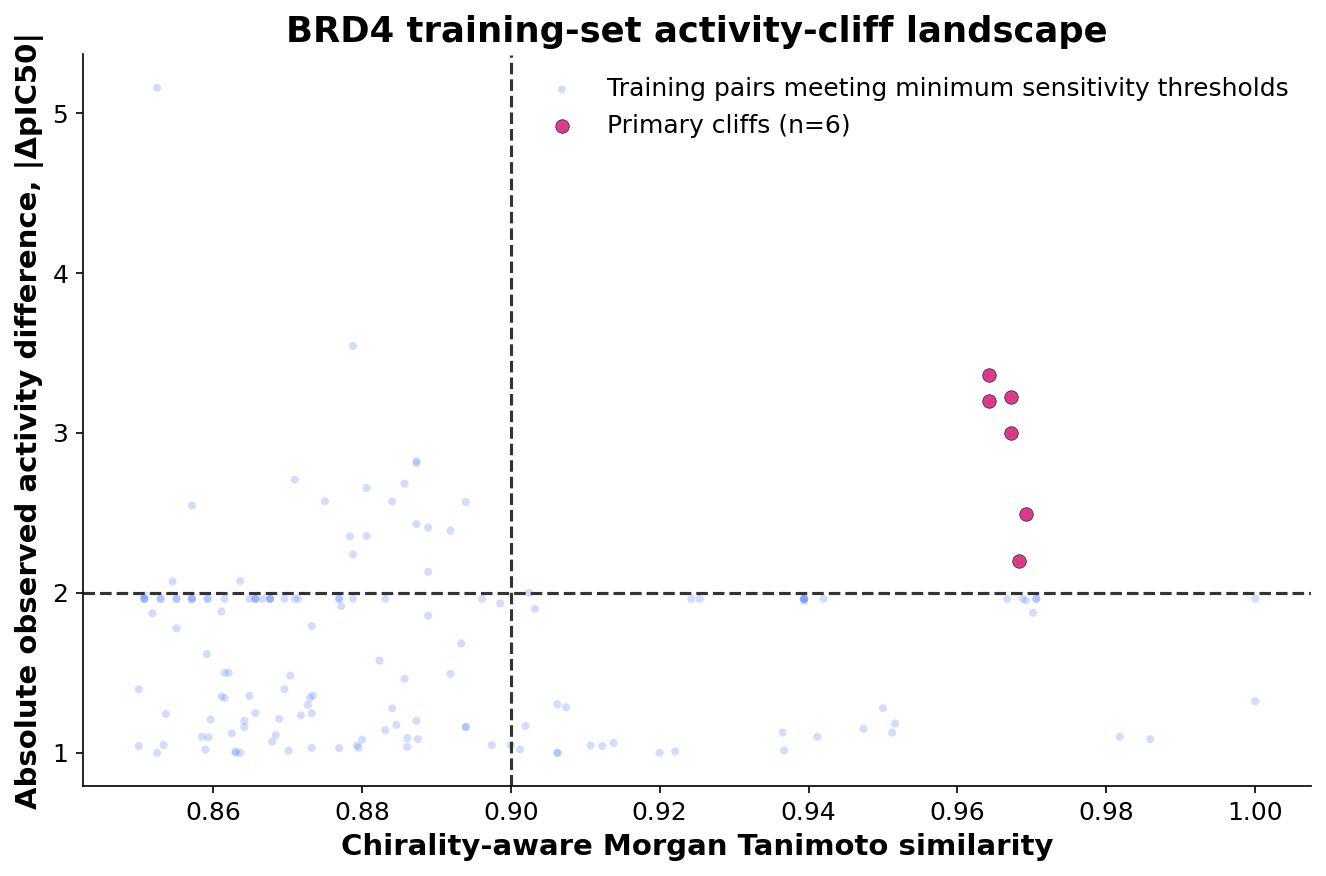

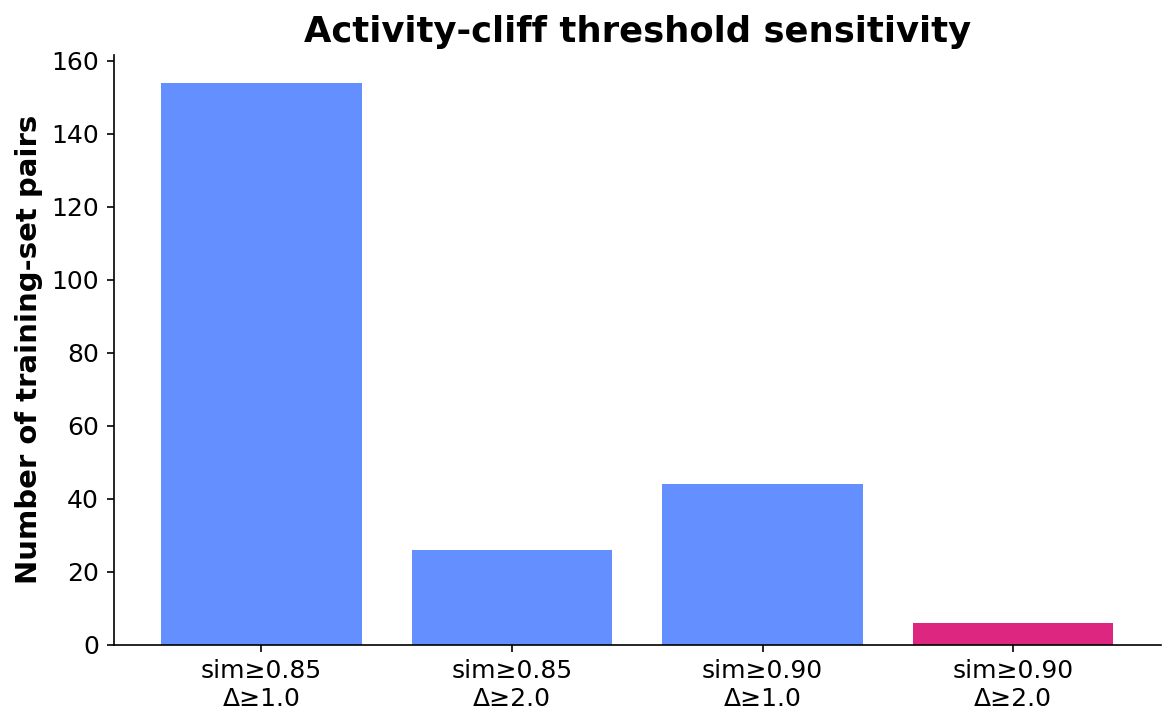

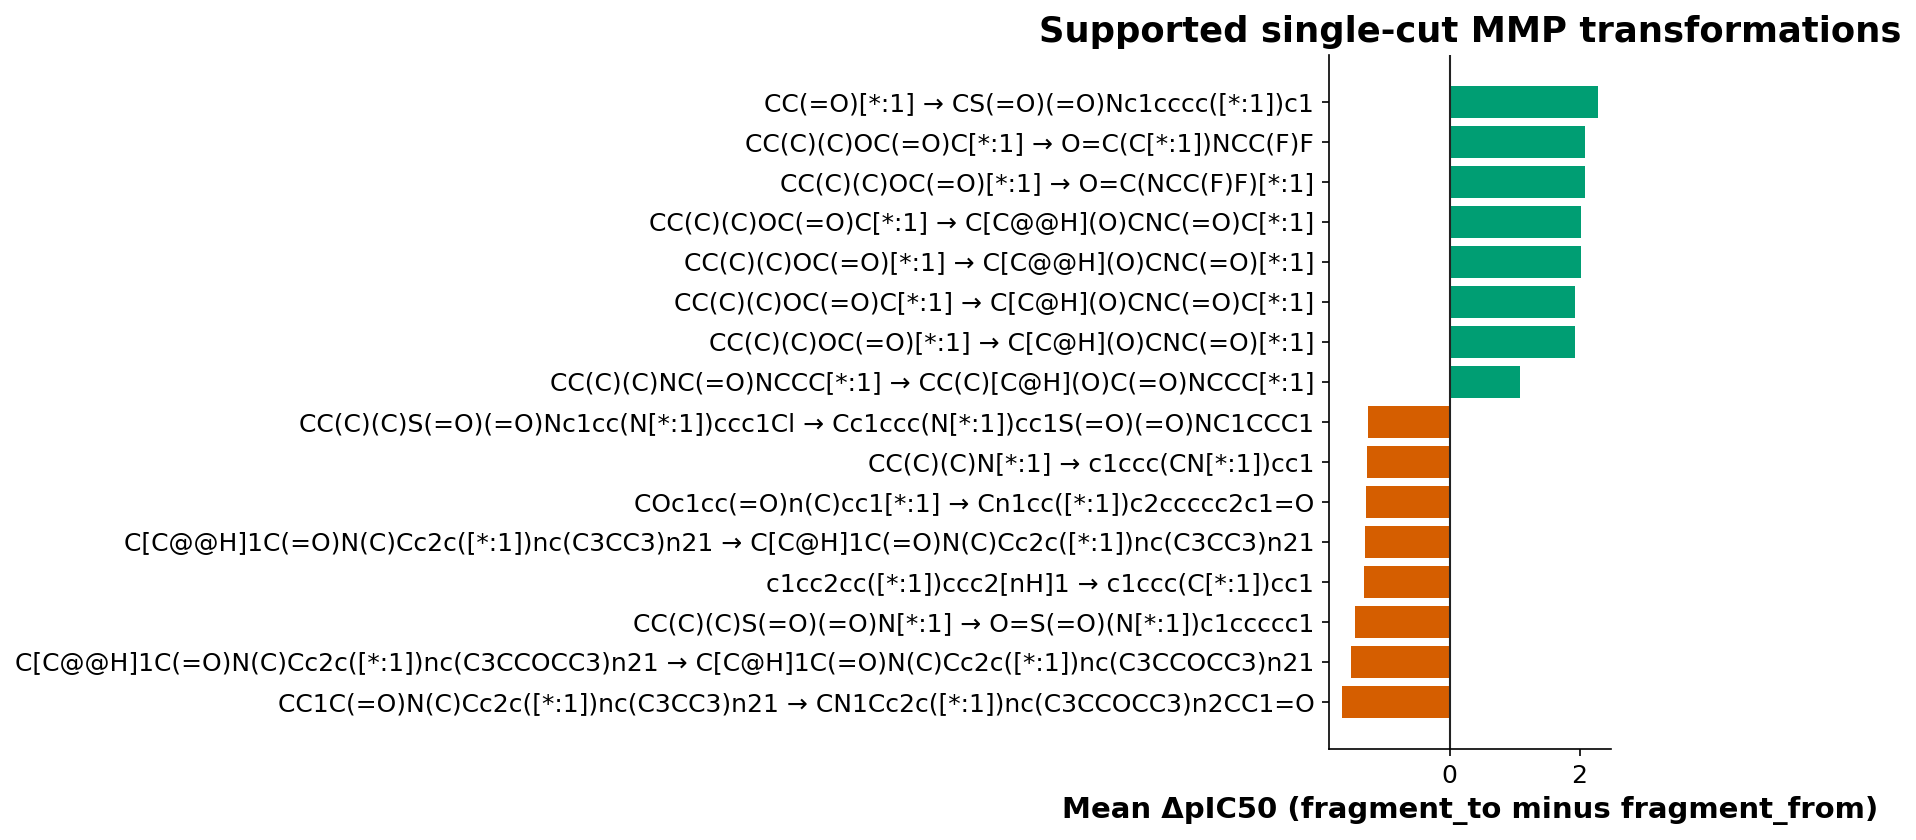

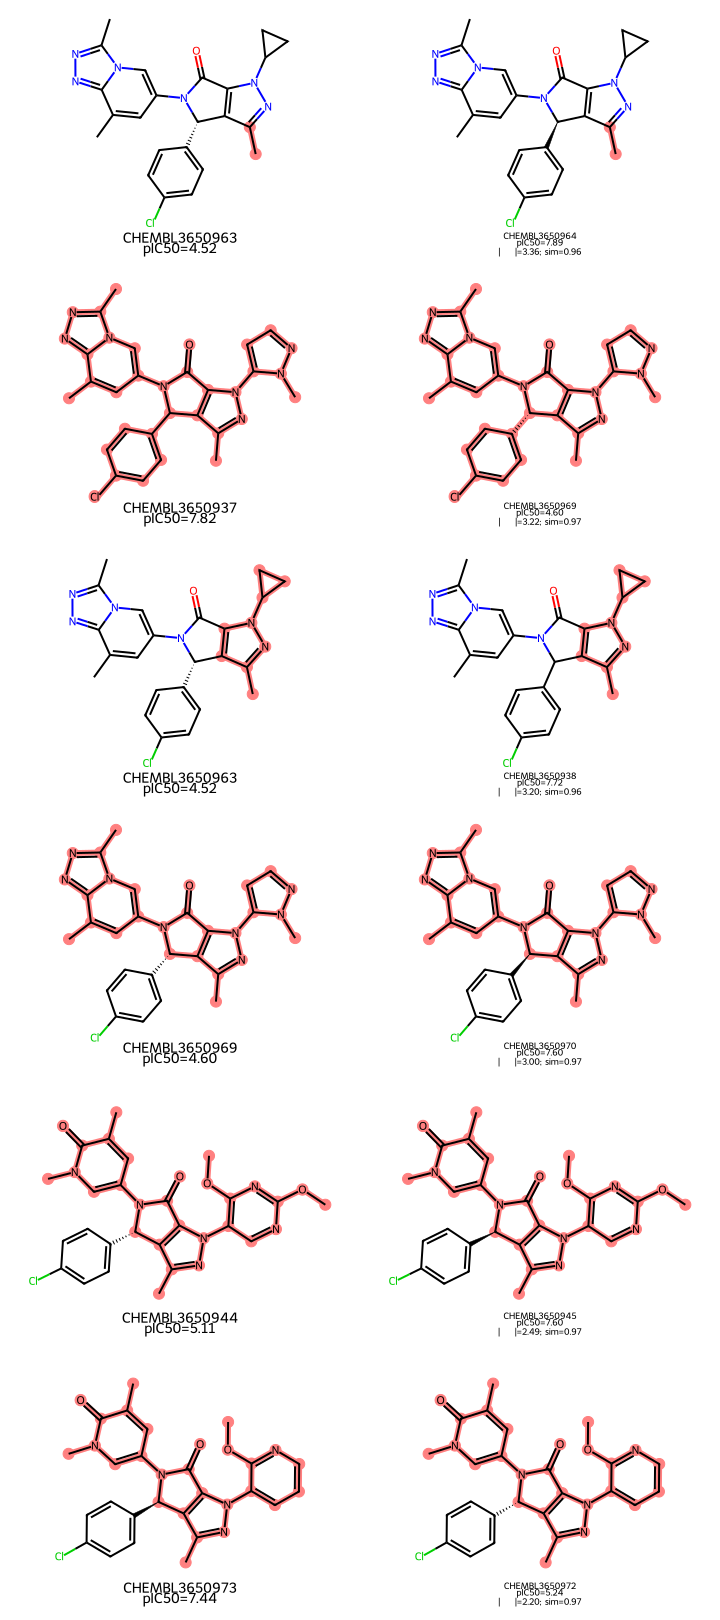

Displayed and saved 6 primary cliff structure pairs.
Figures saved under C:\Users\USER\Documents\E\Code\outputs\11_sar_scaffold_reviewer\figures\C_mmp_cliffs


In [24]:
# 8. Display and save the Stage 11 figures.
# Activity-cliff landscape among all pairs meeting the minimum declared thresholds.
plot_candidates = similar_pairs
if len(plot_candidates) > 50_000:
    plot_candidates = plot_candidates.sample(50_000, random_state=SEED)

fig, ax = plt.subplots(figsize=(9, 6))
if not plot_candidates.empty:
    ax.scatter(
        plot_candidates.tanimoto_chiral,
        plot_candidates.absolute_delta_pIC50,
        s=15, alpha=0.30, color="#648FFF", edgecolors="none",
        label="Training pairs meeting minimum sensitivity thresholds",
    )
if not primary_cliffs.empty:
    ax.scatter(
        primary_cliffs.tanimoto_chiral,
        primary_cliffs.absolute_delta_pIC50,
        s=42, alpha=0.9, color="#DC267F", edgecolors="black", linewidths=0.3,
        label=f"Primary cliffs (n={len(primary_cliffs)})",
    )
ax.axvline(PRIMARY_SIMILARITY, color="#333333", linestyle="--", linewidth=1.5)
ax.axhline(PRIMARY_ACTIVITY_GAP, color="#333333", linestyle="--", linewidth=1.5)
ax.set(
    xlabel="Chirality-aware Morgan Tanimoto similarity",
    ylabel="Absolute observed activity difference, |ΔpIC50|",
    title="BRD4 training-set activity-cliff landscape",
)
ax.legend(frameon=False, loc="best")
fig.tight_layout()

from src.utils import save_figure
save_figure(fig, FIGURE_DIR / "activity_cliff_landscape")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
plot_sens = cliff_sensitivity.copy()
plot_sens["label"] = plot_sens.apply(
    lambda r: f"sim≥{r.similarity_threshold_inclusive:.2f}\n"
              f"Δ≥{r.activity_gap_threshold_inclusive_pIC50:.1f}",
    axis=1,
)
colors = [
    "#DC267F"
    if (
        r.similarity_threshold_inclusive == PRIMARY_SIMILARITY
        and r.activity_gap_threshold_inclusive_pIC50 == PRIMARY_ACTIVITY_GAP
    )
    else "#648FFF"
    for r in plot_sens.itertuples(index=False)
]
ax.bar(plot_sens.label, plot_sens.n_activity_cliffs, color=colors)
ax.set(ylabel="Number of training-set pairs", title="Activity-cliff threshold sensitivity")
fig.tight_layout()
save_figure(fig, FIGURE_DIR / "activity_cliff_threshold_sensitivity")
display(fig)
plt.close(fig)

# Plot the most consistent supported transformations by mean observed ΔpIC50.
plot_transforms = pd.concat(
    [enriching.head(8), depleting.head(8)],
    ignore_index=True,
)
if not plot_transforms.empty:
    plot_transforms = plot_transforms.sort_values("mean_delta_pIC50", kind="stable")
    labels = [
        f"{a} → {b}"
        for a, b in zip(plot_transforms.fragment_from, plot_transforms.fragment_to)
    ]
    fig, ax = plt.subplots(figsize=(11, max(5, 0.36 * len(plot_transforms))))
    colors = [
        "#009E73" if value > 0 else "#D55E00"
        for value in plot_transforms.mean_delta_pIC50
    ]
    ax.barh(labels, plot_transforms.mean_delta_pIC50, color=colors)
    ax.axvline(0, color="#222222", linewidth=1)
    ax.set(
        xlabel="Mean ΔpIC50 (fragment_to minus fragment_from)",
        title="Supported single-cut MMP transformations",
    )
    fig.tight_layout()
    save_figure(fig, FIGURE_DIR / "mmp_supported_transformations")
    display(fig)
    plt.close(fig)
else:
    print("No transformations met the predeclared support rule for the summary figure.")

# Show the strongest primary cliffs as structure pairs; common MCS atoms are highlighted.
example_pairs = primary_cliffs.head(6)
if not example_pairs.empty:
    grid_mols, grid_legends, highlight_atoms = [], [], []

    for pair in example_pairs.itertuples(index=False):
        mol_a = Chem.MolFromSmiles(pair.smiles_a)
        mol_b = Chem.MolFromSmiles(pair.smiles_b)

        mcs = rdFMCS.FindMCS(
            [mol_a, mol_b],
            atomCompare=rdFMCS.AtomCompare.CompareElements,
            bondCompare=rdFMCS.BondCompare.CompareOrder,
            ringMatchesRingOnly=True,
            completeRingsOnly=True,
            matchChiralTag=True,
            timeout=3,
        )
        query = Chem.MolFromSmarts(mcs.smartsString) if mcs.numAtoms else None
        atoms_a = list(mol_a.GetSubstructMatch(query)) if query is not None else []
        atoms_b = list(mol_b.GetSubstructMatch(query)) if query is not None else []

        grid_mols.extend([mol_a, mol_b])
        highlight_atoms.extend([atoms_a, atoms_b])
        grid_legends.extend([
            f"{pair.chembl_id_a}\npIC50={pair.pIC50_a:.2f}",
            f"{pair.chembl_id_b}\npIC50={pair.pIC50_b:.2f}\n"
            f"|Δ|={pair.absolute_delta_pIC50:.2f}; sim={pair.tanimoto_chiral:.2f}",
        ])

    cliff_grid = Draw.MolsToGridImage(
        grid_mols,
        molsPerRow=2,
        subImgSize=(360, 270),
        legends=grid_legends,
        highlightAtomLists=highlight_atoms,
        useSVG=False,
    )

    # RDKit may return either a PIL image or an IPython Image.
    from io import BytesIO
    import base64
    from PIL import Image as PILImage

    cliff_grid_path = FIGURE_DIR / "primary_activity_cliff_structure_pairs.png"

    if hasattr(cliff_grid, "save"):
        cliff_grid.save(
            cliff_grid_path,
            format="PNG",
            dpi=(300, 300),
        )
    elif hasattr(cliff_grid, "data"):
        image_data = cliff_grid.data
        if isinstance(image_data, str):
            if image_data.startswith("data:image") and "," in image_data:
                image_data = image_data.split(",", 1)[1]
            image_data = base64.b64decode(image_data)

        with PILImage.open(BytesIO(image_data)) as pil_grid:
            pil_grid.save(
                cliff_grid_path,
                format="PNG",
                dpi=(300, 300),
            )
    else:
        raise TypeError(
            f"Unsupported RDKit grid image type: {type(cliff_grid)!r}"
        )

    display(cliff_grid)
    print(f"Displayed and saved {len(example_pairs)} primary cliff structure pairs.")
else:
    print("No primary activity cliffs met the declared thresholds; no structure grid was created.")

print(f"Figures saved under {FIGURE_DIR}")

# Part D — Locked-test evidence for the reviewers (post-hoc; reads test labels)

> Everything above is frozen. This part reads locked-test observed values **only to compute evaluation statistics**; it selects no feature, parameter, or scaffold. The final models are not refitted. Baselines (training mean, Tanimoto 1-NN / weighted 5-NN, standardised Ridge on the fixed 250 features) are fitted on training molecules only.

Uncertainty is a **scaffold-group (cluster) bootstrap**: whole test scaffold groups are resampled with replacement, so molecules sharing a scaffold are never treated as independent. One set of resamples is shared by every model and baseline, so paired differences are computed on identical resampled test sets.

In [25]:

# ============================================================
# PART D.1 — LOAD LOCKED-TEST PREDICTIONS (THREE PRIMARY MODELS)
# ============================================================

use_part("D_locked_test_reviewer_evidence")

PRED_FILE = OUTPUTS / (
    "08_final_model_evaluation/tables/"
    "locked_test_predictions_all_models.csv"
)

if not PRED_FILE.is_file():
    raise FileNotFoundError(PRED_FILE)


def find_col(frame, choices):
    lower = {str(c).lower(): c for c in frame.columns}
    return next(
        (lower[c.lower()] for c in choices if c.lower() in lower),
        None
    )


# ------------------------------------------------------------
# 1. Load Stage 08 locked-test predictions
# ------------------------------------------------------------

test_pred = pd.read_csv(
    PRED_FILE,
    dtype={"chembl_id": str}
)

aliases = {
    "model": ["model", "estimator"],
    "chembl_id": ["chembl_id", "molecule_id", "compound_id"],
    "observed_pIC50": [
        "observed_pIC50", "observed_pic50",
        "y_true", "actual_pIC50"
    ],
    "predicted_pIC50": [
        "predicted_pIC50", "predicted_pic50",
        "y_pred", "prediction"
    ]
}

resolved = {
    k: find_col(test_pred, v)
    for k, v in aliases.items()
}

if any(v is None for v in resolved.values()):
    raise ValueError(
        "Prediction table must contain model, chembl_id, "
        "observed and predicted pIC50. "
        f"Found: {test_pred.columns.tolist()}"
    )

test_pred = test_pred.rename(
    columns={v: k for k, v in resolved.items()}
)

# ------------------------------------------------------------
# 2. Standardise prediction columns
# ------------------------------------------------------------

test_pred["model"] = test_pred["model"].astype(str).str.strip()
test_pred["chembl_id"] = test_pred["chembl_id"].astype(str)

for c in ("observed_pIC50", "predicted_pIC50"):
    test_pred[c] = pd.to_numeric(
        test_pred[c], errors="coerce"
    )

test_pred = test_pred.dropna(
    subset=[
        "model",
        "chembl_id",
        "observed_pIC50",
        "predicted_pIC50"
    ]
).copy()

# ------------------------------------------------------------
# 3. Retain ONLY the three prespecified primary models
# ------------------------------------------------------------

MODEL_NAMES = (
    "ExtraTreesRegressor",
    "CatBoostRegressor",
    "SVR"
)

available_models = set(test_pred["model"].unique())

missing_models = set(MODEL_NAMES) - available_models

if missing_models:
    raise ValueError(
        f"Missing expected primary models: {sorted(missing_models)}"
    )

supplementary_models = sorted(
    available_models - set(MODEL_NAMES)
)

if supplementary_models:
    print(
        "Supplementary models excluded from primary analysis:",
        supplementary_models
    )

test_pred = test_pred[
    test_pred["model"].isin(MODEL_NAMES)
].copy()

# ------------------------------------------------------------
# 4. Validate primary model predictions
# ------------------------------------------------------------

found_models = set(test_pred["model"].unique())

if found_models != set(MODEL_NAMES):
    raise ValueError(
        f"Expected models {MODEL_NAMES}; "
        f"found {sorted(found_models)}"
    )

if test_pred.duplicated(
    ["model", "chembl_id"]
).any():
    raise ValueError(
        "Duplicate model–molecule rows in the prediction table."
    )

if set(test_pred["chembl_id"]) != test_set:
    raise ValueError(
        "Prediction IDs do not match Stage 04 test_ids.csv."
    )

# ------------------------------------------------------------
# 5. Confirm observed activities are consistent
# ------------------------------------------------------------

obs_check = (
    test_pred.groupby("chembl_id")["observed_pIC50"].nunique()
)

if (obs_check > 1).any():
    raise ValueError(
        "Observed pIC50 differs between models "
        "for the same molecule."
    )

# ------------------------------------------------------------
# 6. Construct locked-test information table
# ------------------------------------------------------------

test_list = sorted(test_set)

test_info = pd.DataFrame(
    index=pd.Index(test_list, name="chembl_id")
)

test_info["observed_pIC50"] = (
    test_pred.drop_duplicates("chembl_id")
    .set_index("chembl_id")["observed_pIC50"]
    .reindex(test_list)
)

test_info["canonical_smiles"] = (
    smiles_table.set_index("chembl_id")["canonical_smiles"]
    .reindex(test_list)
)

if test_info["canonical_smiles"].isna().any():
    raise ValueError(
        "Some test molecules lack standardized SMILES."
    )

test_info["mol"] = (
    test_info["canonical_smiles"].map(Chem.MolFromSmiles)
)

if test_info["mol"].isna().any():
    raise ValueError("Invalid test SMILES.")

_sc = test_info["mol"].map(murcko_pair)

test_info[
    [
        "exact_scaffold",
        "generic_scaffold",
        "_m",
        "exact_scaffold_type"
    ]
] = pd.DataFrame(
    _sc.tolist(),
    index=test_info.index
)

test_info = test_info.drop(columns="_m")

# ------------------------------------------------------------
# 7. Determine scaffold bootstrap groups
# ------------------------------------------------------------

gcol = find_col(
    test_pred,
    ["group", "scaffold_group", "split_group"]
)

if gcol is not None and test_pred[gcol].notna().all():

    test_info["group"] = (
        test_pred.drop_duplicates("chembl_id")
        .set_index("chembl_id")[gcol]
        .astype(str)
        .reindex(test_list)
    )

    group_source = (
        f"saved column '{gcol}' in Stage 08 predictions"
    )

else:

    test_info["group"] = test_info["exact_scaffold"]

    group_source = (
        "exact Bemis–Murcko scaffold "
        "(acyclic = own key), reconstructed from SMILES"
    )

# ------------------------------------------------------------
# 8. Prepare observed values and predictions
# ------------------------------------------------------------

y_test = test_info["observed_pIC50"].to_numpy(float)

groups = test_info["group"].to_numpy(str)

final_preds = {
    m: (
        test_pred[test_pred["model"].eq(m)]
        .set_index("chembl_id")["predicted_pIC50"]
        .reindex(test_list)
        .to_numpy(float)
    )
    for m in MODEL_NAMES
}

# ------------------------------------------------------------
# 9. Final integrity checks and summary
# ------------------------------------------------------------

if len(test_info) != len(test_set):
    raise ValueError("Locked-test molecule count mismatch.")

for model_name, predictions in final_preds.items():
    if len(predictions) != len(y_test):
        raise ValueError(
            f"{model_name}: prediction count mismatch."
        )

    if not np.isfinite(predictions).all():
        raise ValueError(
            f"{model_name}: non-finite predictions detected."
        )

print(
    f"Primary models: {list(MODEL_NAMES)}\n"
    f"Test molecules: {len(test_list):,}\n"
    f"Bootstrap groups: {len(np.unique(groups)):,}\n"
    f"Group source: {group_source}"
)

print("\nLocked-test prediction summary:")

display(
    test_pred.groupby("model").agg(
        n=("chembl_id", "nunique"),
        obs_min=("observed_pIC50", "min"),
        obs_max=("observed_pIC50", "max"),
        pred_min=("predicted_pIC50", "min"),
        pred_max=("predicted_pIC50", "max")
    ).reset_index().round(3)
)


Supplementary models excluded from primary analysis: ['Equal-weight ensemble (supplementary)']
Primary models: ['ExtraTreesRegressor', 'CatBoostRegressor', 'SVR']
Test molecules: 1,283
Bootstrap groups: 531
Group source: saved column 'group' in Stage 08 predictions

Locked-test prediction summary:


,model,n,obs_min,obs_max,pred_min,pred_max
0,CatBoostRegressor,1283,2.845,9.469,3.227,9.344
1,ExtraTreesRegressor,1283,2.845,9.469,3.302,9.101
2,SVR,1283,2.845,9.469,2.178,9.238


### D.2 Metrics, baselines and scaffold-bootstrap CIs

In [26]:
def reg_rank_metrics(y, p, cutoff=ACTIVE_PIC50_CUTOFF):
    y = np.asarray(y, float); p = np.asarray(p, float); n = len(y)
    rmse = float(np.sqrt(np.mean((y - p) ** 2))); mae = float(np.mean(np.abs(y - p)))
    denom = float(np.sum((y - y.mean()) ** 2)); r2 = 1 - float(np.sum((y - p) ** 2)) / denom if denom > 0 else np.nan
    if n > 2 and np.ptp(p) > 0 and np.ptp(y) > 0:
        rho = float(spearmanr(y, p).statistic); tau = float(kendalltau(y, p).statistic)
    else:
        rho = tau = np.nan                                     # constant predictor: rank correlation undefined
    k = max(1, int(round(0.10 * n)))
    top_pred = np.argpartition(-p, k - 1)[:k] if k < n else np.arange(n)
    top_obs = np.argpartition(-y, k - 1)[:k] if k < n else np.arange(n)
    active = y >= cutoff; prev = float(active.mean())
    hits = int(active[top_pred].sum())
    return {"RMSE": rmse, "MAE": mae, "R2": r2, "Spearman": rho, "Kendall_tau": tau, "top10pct_n": k,
            "top10pct_hits_pIC50_ge_cutoff": hits, "top10pct_enrichment_factor": (hits / k) / prev if prev > 0 else np.nan,
            "top10pct_overlap": len(set(top_pred.tolist()) & set(top_obs.tolist())) / k}

def boot_indices(groups, n_boot, seed):
    """Cluster-bootstrap row indices: resample whole groups with replacement."""
    groups = np.asarray(groups).astype(str); uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inv == i) for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    return [np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))]) for _ in range(n_boot)]

def metrics_with_ci(y, preds, idx):
    """Point estimates + percentile CIs for every method on the SAME resamples `idx`."""
    point, boots = {}, {}
    for name, p in preds.items():
        point[name] = reg_rank_metrics(y, p)
        boots[name] = pd.DataFrame([reg_rank_metrics(y[ix], p[ix]) for ix in idx])
    return point, boots

def long_table(point, boots, metrics, label, n_boot, unit="test scaffold group"):
    rows = []
    for name in point:
        for m in metrics:
            b = boots[name][m].dropna()
            rows.append({label: name, "metric": m, "estimate": point[name][m],
                         "ci95_low": b.quantile(.025) if len(b) else np.nan, "ci95_high": b.quantile(.975) if len(b) else np.nan,
                         "top10pct_n": point[name]["top10pct_n"], "top10pct_hits_pIC50_ge_cutoff": point[name]["top10pct_hits_pIC50_ge_cutoff"],
                         "active_cutoff_pIC50": ACTIVE_PIC50_CUTOFF, "bootstrap_unit": unit, "n_bootstrap": n_boot})
    return pd.DataFrame(rows)

# ---- training-only baselines
test_fps = [MORGAN.GetFingerprint(m) for m in test_info.mol]
train_y_arr = train.pIC50.to_numpy(float)
p1, p5 = [], []
for fp in test_fps:
    sims = np.asarray(DataStructs.BulkTanimotoSimilarity(fp, fp_vectors), float)
    order = np.argsort(-sims)
    p1.append(train_y_arr[order[0]])
    ix = order[:5]; w = np.clip(sims[ix], 1e-8, None); p5.append(float(np.sum(w * train_y_arr[ix]) / w.sum()))
baseline_preds = {"Training mean": np.full(len(test_list), train_y_arr.mean()),
                  "Morgan Tanimoto 1-NN": np.asarray(p1), "Morgan Tanimoto weighted 5-NN": np.asarray(p5)}
max_sim_to_train = np.array([float(np.max(DataStructs.BulkTanimotoSimilarity(fp, fp_vectors))) for fp in test_fps])

TEST_X_FILE = OUTPUTS / "05_feature_selection/tables/test_selected_features.parquet"
ALL_FEATURES_FILE = OUTPUTS / "03_feature_generation/tables/all_features.parquet"
def load_test_fixed250():
    """Fixed-250 test matrix: Stage 05 file if present, else Stage 03 (verified identical on training rows)."""
    if TEST_X_FILE.is_file():
        X = pd.read_parquet(TEST_X_FILE); src = "Stage 05 test_selected_features.parquet"
    elif ALL_FEATURES_FILE.is_file():
        X = pd.read_parquet(ALL_FEATURES_FILE, columns=selected); src = "Stage 03 all_features.parquet (selected columns)"
        chk = X.copy(); chk.index = chk.index.astype(str)
        if not np.allclose(chk.reindex(X_train.index).loc[:, selected].to_numpy(float), X_train.to_numpy(float), equal_nan=True):
            raise ValueError("Stage 03 values for training rows differ from Stage 05 training matrix; cannot reuse them for test.")
    else:
        return None, "no fixed-250 test matrix found"
    X.index = X.index.astype(str)
    X = X.reindex(index=test_list).loc[:, selected].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(X.to_numpy(float)).all(): raise ValueError("Test fixed-250 matrix has missing/non-finite values; no imputation is performed.")
    return X, src
X_test, X_test_source = load_test_fixed250()
if X_test is not None:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train, train_y_arr)
    baseline_preds["Ridge (alpha=1; fixed 250 features)"] = ridge.predict(X_test)
    print("Ridge baseline fitted on training molecules only; test matrix:", X_test_source)
else:
    print("Ridge baseline SKIPPED:", X_test_source)

all_preds = {**final_preds, **baseline_preds}
idx_main = boot_indices(groups, N_BOOT, SEED)
point_all, boots_all = metrics_with_ci(y_test, all_preds, idx_main)
fin = {k: v for k, v in point_all.items() if k in MODEL_NAMES}
A = long_table({k: point_all[k] for k in MODEL_NAMES}, boots_all, ["RMSE", "MAE", "R2"], "model", N_BOOT)
B = long_table({k: point_all[k] for k in MODEL_NAMES}, boots_all, ["Spearman", "Kendall_tau", "top10pct_enrichment_factor", "top10pct_overlap"], "model", N_BOOT)
base_names = list(baseline_preds)
C = long_table({k: point_all[k] for k in base_names}, boots_all, ["RMSE", "MAE", "R2", "Spearman", "Kendall_tau"], "method", N_BOOT)
C.loc[C.method.eq("Training mean") & C.metric.isin(["Spearman", "Kendall_tau"]), ["estimate", "ci95_low", "ci95_high"]] = np.nan
A.to_csv(TABLE_DIR / "A_test_performance_scaffold_bootstrap_CI.csv", index=False)
B.to_csv(TABLE_DIR / "B_test_ranking_metrics_scaffold_bootstrap_CI.csv", index=False)
C.to_csv(TABLE_DIR / "C_baseline_comparison_locked_test.csv", index=False)
print("A. Final models — regression metrics (95% scaffold-bootstrap CI)"); display(A[["model", "metric", "estimate", "ci95_low", "ci95_high"]].round(4))
print(f"B. Final models — ranking (top 10% = {int(A.top10pct_n.iloc[0])} molecules; 'active' = pIC50 ≥ {ACTIVE_PIC50_CUTOFF:g})"); display(B[["model", "metric", "estimate", "ci95_low", "ci95_high", "top10pct_hits_pIC50_ge_cutoff"]].round(4))
print("C. Baselines (training-only)"); display(C[["method", "metric", "estimate", "ci95_low", "ci95_high"]].round(4))

Ridge baseline fitted on training molecules only; test matrix: Stage 03 all_features.parquet (selected columns)
A. Final models — regression metrics (95% scaffold-bootstrap CI)


,model,metric,estimate,ci95_low,ci95_high
0,ExtraTreesRegressor,RMSE,0.5771,0.5228,0.6268
1,ExtraTreesRegressor,MAE,0.4009,0.3592,0.4433
2,ExtraTreesRegressor,R2,0.8008,0.7481,0.8400
3,CatBoostRegressor,RMSE,0.5810,0.5293,0.6296
4,CatBoostRegressor,MAE,0.4144,0.3697,0.4577
5,CatBoostRegressor,R2,0.7981,0.7504,0.8364
6,SVR,RMSE,0.5621,0.5170,0.6051
7,SVR,MAE,0.3954,0.3615,0.4288
8,SVR,R2,0.8111,0.7630,0.8483


B. Final models — ranking (top 10% = 128 molecules; 'active' = pIC50 ≥ 8)


,model,metric,estimate,ci95_low,ci95_high,top10pct_hits_pIC50_ge_cutoff
0,ExtraTreesRegressor,Spearman,0.8958,0.8623,0.9169,58
1,ExtraTreesRegressor,Kendall_tau,0.7348,0.6957,0.7647,58
2,ExtraTreesRegressor,top10pct_enrichment_factor,7.9638,6.4702,9.2294,58
3,ExtraTreesRegressor,top10pct_overlap,0.6797,0.5667,0.8511,58
4,CatBoostRegressor,Spearman,0.8935,0.8624,0.9150,60
5,CatBoostRegressor,Kendall_tau,0.7300,0.6925,0.7596,60
6,CatBoostRegressor,top10pct_enrichment_factor,8.2384,6.4599,9.1008,60
7,CatBoostRegressor,top10pct_overlap,0.6719,0.5726,0.8224,60
8,SVR,Spearman,0.9003,0.8697,0.9194,66
9,SVR,Kendall_tau,0.7401,0.7029,0.7673,66


C. Baselines (training-only)


,method,metric,estimate,ci95_low,ci95_high
0,Training mean,RMSE,1.2940,1.1849,1.4093
1,Training mean,MAE,1.0960,0.9995,1.1955
2,Training mean,R2,-0.0014,-0.0587,-0.0000
3,Training mean,Spearman,NaN,NaN,NaN
4,Training mean,Kendall_tau,NaN,NaN,NaN
5,Morgan Tanimoto 1-NN,RMSE,0.7114,0.6204,0.7996
6,Morgan Tanimoto 1-NN,MAE,0.4467,0.3952,0.5012
7,Morgan Tanimoto 1-NN,R2,0.6973,0.6054,0.7738
8,Morgan Tanimoto 1-NN,Spearman,0.8502,0.8102,0.8823
9,Morgan Tanimoto 1-NN,Kendall_tau,0.6894,0.6463,0.7281


### D.3 Paired comparisons on identical resamples
Gain = RMSE(reference) − RMSE(model); positive favours the model. Intervals that include 0 mean the difference is **not resolved** by this test set.

In [27]:
rows = []
def paired_row(model, ref, kind):
    for metric in ("RMSE", "MAE"):
        d = boots_all[ref][metric].to_numpy() - boots_all[model][metric].to_numpy()
        point = point_all[ref][metric] - point_all[model][metric]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"model": model, "reference": ref, "reference_type": kind, "metric": metric, "reference_value": point_all[ref][metric],
                     "model_value": point_all[model][metric], "gain_reference_minus_model": point, "ci95_low": lo, "ci95_high": hi,
                     "bootstrap_two_sided_p": float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))),
                     "interpretation": "model better; CI excludes 0" if lo > 0 else "reference better; CI excludes 0" if hi < 0 else "CI includes 0; not resolved",
                     "bootstrap_unit": "paired test scaffold groups", "n_bootstrap": N_BOOT})
for m in MODEL_NAMES:
    for ref in base_names:
        if ref != "Training mean": paired_row(m, ref, "baseline")
for a, b in itertools.combinations(MODEL_NAMES, 2):
    paired_row(a, b, "final model")
paired = pd.DataFrame(rows)
paired.to_csv(TABLE_DIR / "D_paired_differences_scaffold_bootstrap.csv", index=False)
display(paired.loc[paired.metric.eq("RMSE"), ["model", "reference", "gain_reference_minus_model", "ci95_low", "ci95_high", "interpretation"]].round(4))

,model,reference,gain_reference_minus_model,ci95_low,ci95_high,interpretation
0,ExtraTreesRegressor,Morgan Tanimoto 1-NN,0.1343,0.0581,0.2021,model better; CI excludes 0
2,ExtraTreesRegressor,Morgan Tanimoto weighted 5-NN,0.0178,-0.0210,0.0562,CI includes 0; not resolved
4,ExtraTreesRegressor,Ridge (alpha=1; fixed 250 features),0.0863,0.0533,0.1194,model better; CI excludes 0
6,CatBoostRegressor,Morgan Tanimoto 1-NN,0.1304,0.0611,0.1902,model better; CI excludes 0
8,CatBoostRegressor,Morgan Tanimoto weighted 5-NN,0.0138,-0.0219,0.0530,CI includes 0; not resolved
10,CatBoostRegressor,Ridge (alpha=1; fixed 250 features),0.0824,0.0523,0.1161,model better; CI excludes 0
12,SVR,Morgan Tanimoto 1-NN,0.1493,0.0765,0.2183,model better; CI excludes 0
14,SVR,Morgan Tanimoto weighted 5-NN,0.0328,-0.0026,0.0680,CI includes 0; not resolved
16,SVR,Ridge (alpha=1; fixed 250 features),0.1013,0.0728,0.1290,model better; CI excludes 0
18,ExtraTreesRegressor,CatBoostRegressor,0.0040,-0.0167,0.0214,CI includes 0; not resolved


### D.4 Figures

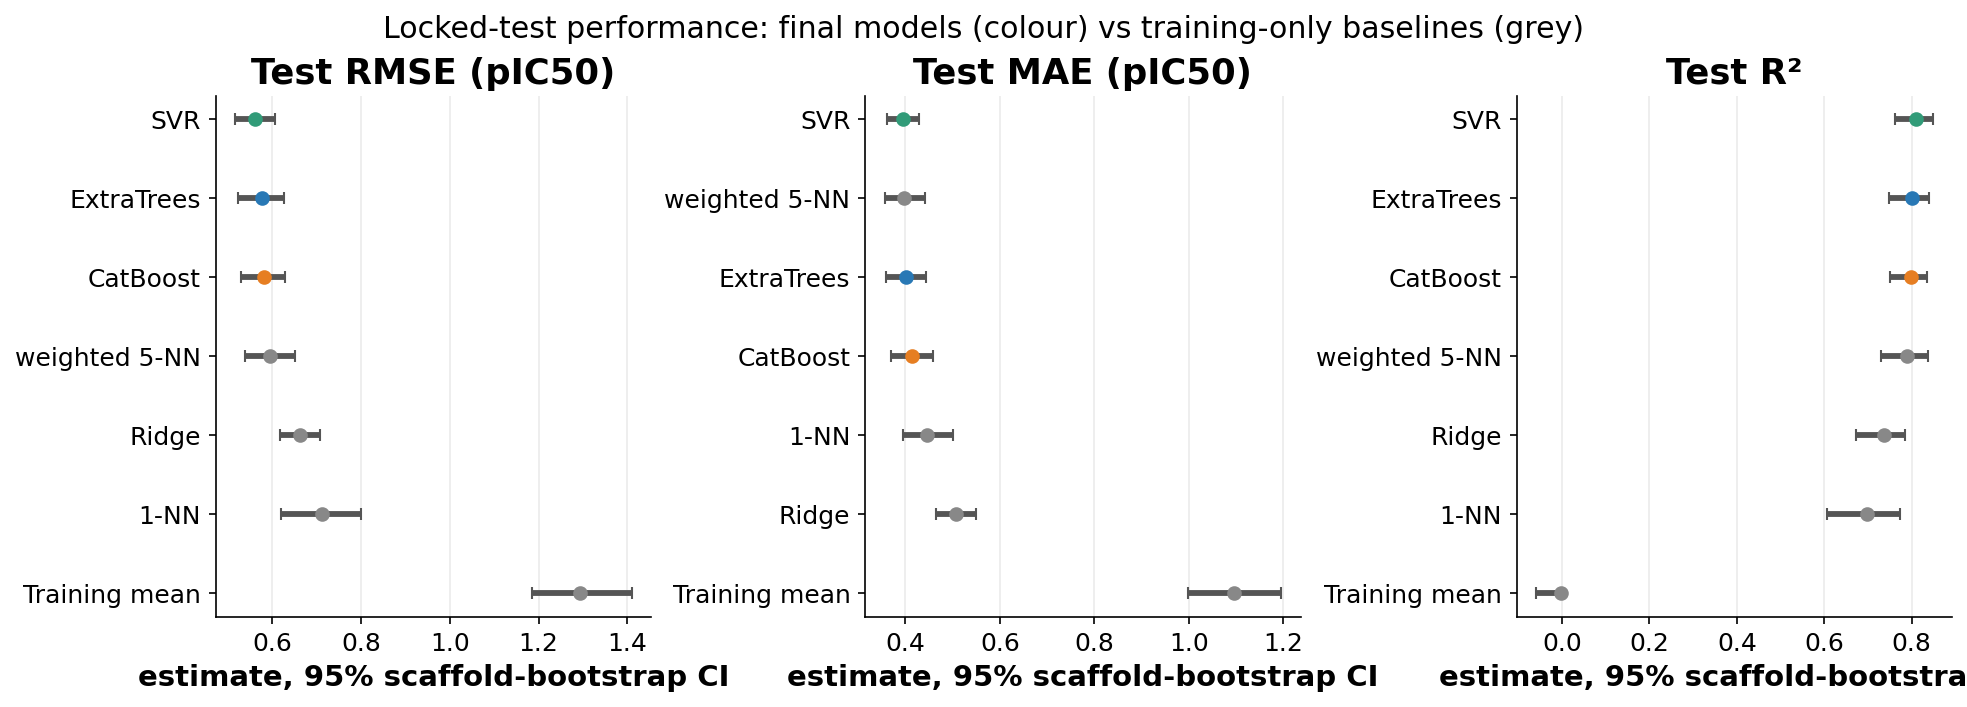

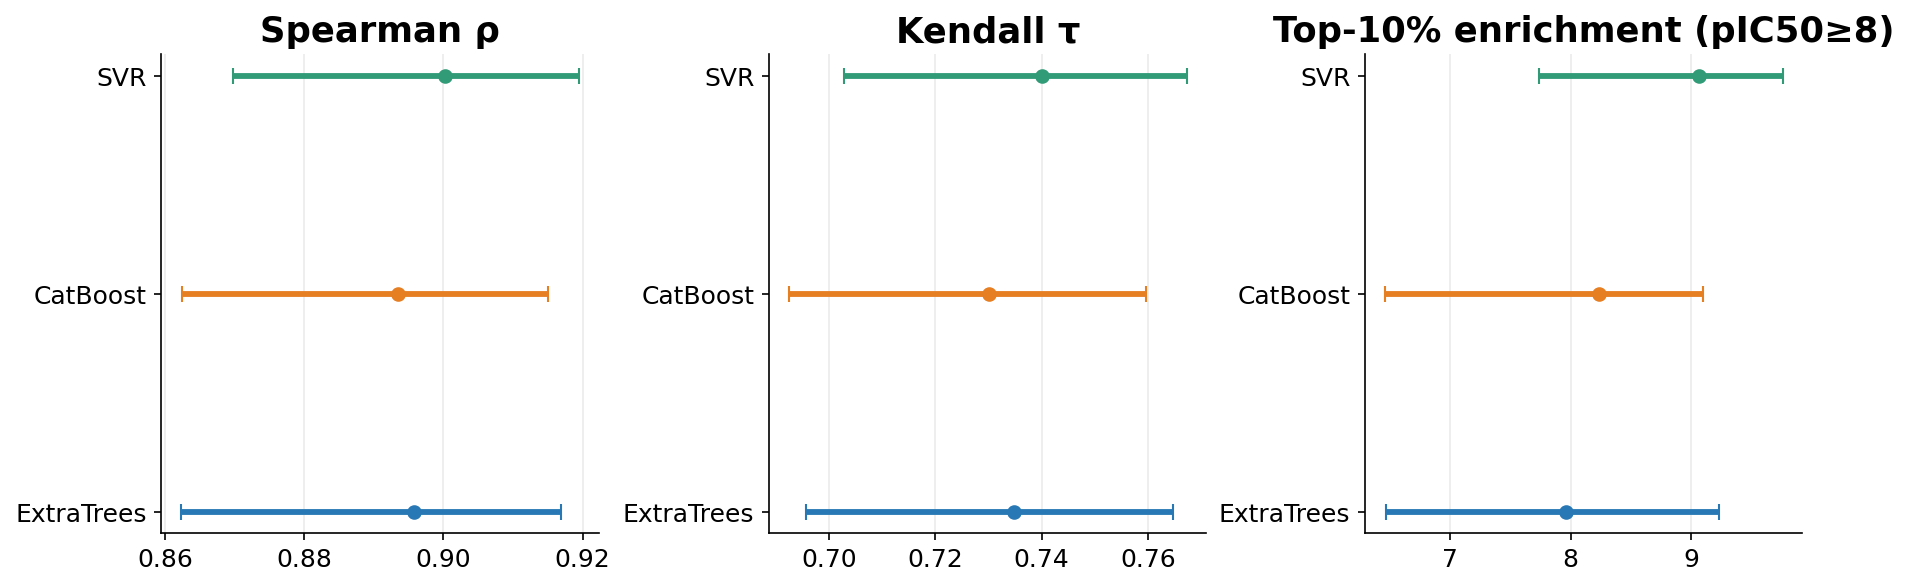

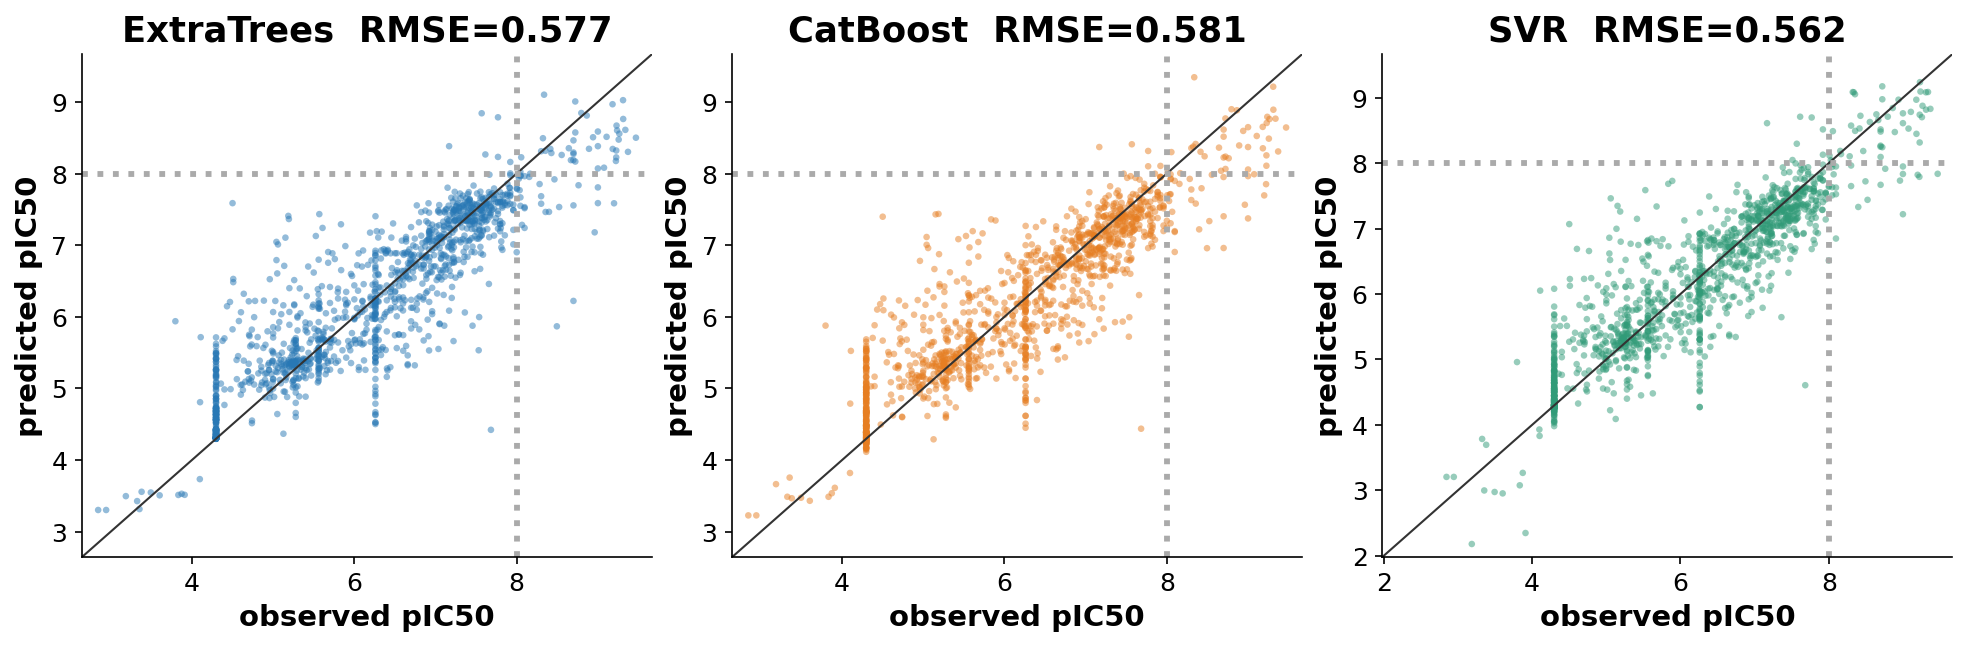

In [28]:
colors = {"ExtraTreesRegressor": "#2878B5", "CatBoostRegressor": "#E67E22", "SVR": "#319B78"}
short = lambda s: s.replace("Regressor", "").replace("Morgan Tanimoto ", "").replace(" (alpha=1; fixed 250 features)", "")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
for ax, metric, title in zip(axes, ["RMSE", "MAE", "R2"], ["Test RMSE (pIC50)", "Test MAE (pIC50)", "Test R²"]):
    d = pd.concat([A[A.metric.eq(metric)].rename(columns={"model": "name"}), C[C.metric.eq(metric)].rename(columns={"method": "name"})])
    d = d.sort_values("estimate", ascending=(metric != "R2")).reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    for yi, r in zip(y, d.itertuples()):
        ax.errorbar(r.estimate, yi, xerr=[[r.estimate - r.ci95_low], [r.ci95_high - r.estimate]], fmt="o", capsize=3,
                    color=colors.get(r.name, "#888888"), ecolor="#555555", ms=6)
    ax.set_yticks(y, [short(n) for n in d.name]); ax.set_title(title); ax.grid(axis="x", alpha=.25); ax.set_xlabel("estimate, 95% scaffold-bootstrap CI")
fig.suptitle("Locked-test performance: final models (colour) vs training-only baselines (grey)")
save_both(fig, "A_performance_with_baselines_CI"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
for ax, (metric, title) in zip(axes, [("Spearman", "Spearman ρ"), ("Kendall_tau", "Kendall τ"), ("top10pct_enrichment_factor", "Top-10% enrichment (pIC50≥8)")]):
    q = B[B.metric.eq(metric)].reset_index(drop=True); y = np.arange(len(q))
    for yi, r in zip(y, q.itertuples()):
        ax.errorbar(r.estimate, yi, xerr=[[r.estimate - r.ci95_low], [r.ci95_high - r.estimate]], fmt="o", capsize=4, color=colors[r.model])
    ax.set_yticks(y, [short(m) for m in q.model]); ax.set_title(title); ax.grid(axis="x", alpha=.25)
save_both(fig, "B_ranking_metrics_CI"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
for ax, m in zip(axes, MODEL_NAMES):
    ax.scatter(y_test, final_preds[m], s=10, alpha=.5, color=colors[m], edgecolors="none")
    lim = [min(y_test.min(), final_preds[m].min()) - .2, max(y_test.max(), final_preds[m].max()) + .2]
    ax.plot(lim, lim, color="#333", lw=1); ax.axhline(ACTIVE_PIC50_CUTOFF, color="#aaa", ls=":"); ax.axvline(ACTIVE_PIC50_CUTOFF, color="#aaa", ls=":")
    ax.set(xlim=lim, ylim=lim, xlabel="observed pIC50", ylabel="predicted pIC50", title=f"{short(m)}  RMSE={point_all[m]['RMSE']:.3f}")
save_both(fig, "observed_vs_predicted_locked_test"); plt.show()

### D.5 Train/test scaffold overlap and error versus similarity to training
A scaffold split should leave **no exact test scaffold in training**; any overlap is reported rather than assumed away. Similarity strata show where the models are extrapolating.

In [29]:
tr_exact, tr_generic = set(train.exact_scaffold), set(train.generic_scaffold)
te_bm = test_info.exact_scaffold_type.eq("Bemis-Murcko")
overlap = pd.DataFrame([{
    "n_test_molecules": len(test_info), "n_test_exact_scaffolds": test_info.exact_scaffold.nunique(),
    "n_test_molecules_exact_scaffold_in_training": int(test_info.exact_scaffold.isin(tr_exact).sum()),
    "fraction_test_molecules_exact_scaffold_in_training": float(test_info.exact_scaffold.isin(tr_exact).mean()),
    "n_shared_exact_scaffolds": len(set(test_info.exact_scaffold) & tr_exact),
    "n_test_molecules_generic_framework_in_training": int(test_info.generic_scaffold.isin(tr_generic).sum()),
    "fraction_test_molecules_generic_framework_in_training": float(test_info.generic_scaffold.isin(tr_generic).mean()),
    "n_shared_generic_frameworks": len(set(test_info.generic_scaffold) & tr_generic),
    "n_test_acyclic_molecules": int((~te_bm).sum()),
    "median_max_tanimoto_to_training": float(np.median(max_sim_to_train)),
    "fraction_test_with_max_tanimoto_ge_0_7": float((max_sim_to_train >= .7).mean()),
    "bootstrap_group_definition": group_source}])
overlap.to_csv(TABLE_DIR / "E_train_test_scaffold_overlap_audit.csv", index=False)
display(overlap.T.rename(columns={0: "value"}))
if overlap.n_shared_exact_scaffolds.iloc[0] > 0:
    print("NOTE: exact scaffolds are shared across partitions under this scaffold definition. If Stage 04 split on a different scaffold "
          "definition (e.g. generic or ring-system level) this is expected; state the split definition in the Methods.")

bins = [0, .4, .55, .7, 1.0001]; labels = ["<0.40", "0.40–0.55", "0.55–0.70", "≥0.70"]
stratum = pd.cut(max_sim_to_train, bins=bins, labels=labels, right=False)
rows = []
for m in MODEL_NAMES:
    err = final_preds[m] - y_test
    for lab in labels:
        s = (stratum == lab)
        if s.sum(): rows.append({"model": m, "max_tanimoto_to_training": lab, "n_test": int(s.sum()), "RMSE": float(np.sqrt(np.mean(err[s] ** 2))),
                                 "MAE": float(np.mean(np.abs(err[s]))), "mean_signed_error": float(err[s].mean())})
    rows.append({"model": m, "max_tanimoto_to_training": "Spearman(|error|, max similarity)", "n_test": len(err),
                 "RMSE": float(spearmanr(np.abs(err), max_sim_to_train).statistic), "MAE": np.nan, "mean_signed_error": np.nan})
sim_strata = pd.DataFrame(rows)
sim_strata.to_csv(TABLE_DIR / "F_error_by_similarity_to_training.csv", index=False)
display(sim_strata.round(3))

,value
n_test_molecules,1283
n_test_exact_scaffolds,522
n_test_molecules_exact_scaffold_in_training,145
fraction_test_molecules_exact_scaffold_in_training,0.113016
n_shared_exact_scaffolds,43
n_test_molecules_generic_framework_in_training,933
fraction_test_molecules_generic_framework_in_training,0.727202
n_shared_generic_frameworks,208
n_test_acyclic_molecules,0
median_max_tanimoto_to_training,0.746269


NOTE: exact scaffolds are shared across partitions under this scaffold definition. If Stage 04 split on a different scaffold definition (e.g. generic or ring-system level) this is expected; state the split definition in the Methods.


,model,max_tanimoto_to_training,n_test,RMSE,MAE,mean_signed_error
0,ExtraTreesRegressor,<0.40,15,0.978,0.796,0.571
1,ExtraTreesRegressor,0.40–0.55,65,0.885,0.670,0.034
2,ExtraTreesRegressor,0.55–0.70,311,0.644,0.458,0.018
3,ExtraTreesRegressor,≥0.70,892,0.511,0.355,0.015
4,ExtraTreesRegressor,"Spearman(|error|, max similarity)",1283,-0.197,NaN,NaN
5,CatBoostRegressor,<0.40,15,0.950,0.743,0.491
6,CatBoostRegressor,0.40–0.55,65,0.878,0.646,0.015
7,CatBoostRegressor,0.55–0.70,311,0.623,0.457,-0.018
8,CatBoostRegressor,≥0.70,892,0.528,0.377,-0.002
9,CatBoostRegressor,"Spearman(|error|, max similarity)",1283,-0.146,NaN,NaN


### D.6 Duplicate-measurement sensitivity (optional)
Uses a replicate-count column in the cleaned table if one exists, otherwise a raw per-measurement ChEMBL extract (set `RAW_ACTIVITY_PATH` in the configuration cell if it is not found automatically). If neither exists the cell says so and writes nothing.

In [30]:
cleaned_cols = pd.read_csv(CLEANED_FILE, nrows=0).columns.tolist()
rep_col = next((c for c in ("n_measurements", "n_replicates", "n_activity_records", "n_records") if c in cleaned_cols), None)
dup = None; dup_source = None
if rep_col:
    dup = pd.read_csv(CLEANED_FILE, usecols=["chembl_id", rep_col], dtype={"chembl_id": str}).rename(columns={rep_col: "n_measurements"})
    dup["measurement_range_pIC50"] = np.nan; dup_source = f"cleaned table column '{rep_col}'"
else:
    cands = [Path(RAW_ACTIVITY_PATH)] if RAW_ACTIVITY_PATH else (
        [p for r in (PROJECT_ROOT / "data", PROJECT_ROOT / "raw_data") if r.is_dir() for p in r.rglob("*.csv")] + list(OUTPUTS.glob("01_*/**/*.csv")))
    for p in cands:
        try: cols = pd.read_csv(p, nrows=0).columns.tolist()
        except Exception: continue
        idc = next((c for c in ("molecule_chembl_id", "chembl_id") if c in cols), None)
        vc = next((c for c in ("pchembl_value", "standard_value") if c in cols), None)
        if idc and vc:
            raw = pd.read_csv(p, dtype={idc: str}, low_memory=False)
            if "standard_type" in raw: raw = raw[raw.standard_type.astype(str).str.upper().eq("IC50")]
            v = pd.to_numeric(raw[vc], errors="coerce")
            raw["_p"] = v if vc == "pchembl_value" else 9 - np.log10(v.where(v > 0))
            g = raw.dropna(subset=["_p"]).groupby(idc)["_p"].agg(n_measurements="size", measurement_range_pIC50=lambda s: s.max() - s.min())
            dup = g.reset_index().rename(columns={idc: "chembl_id"}); dup_source = str(p); break
if dup is None:
    print("Duplicate-measurement sensitivity SKIPPED: no replicate-count column and no raw per-measurement file found. "
          "Set RAW_ACTIVITY_PATH to the raw ChEMBL extract to enable it.")
else:
    d = test_info[["observed_pIC50"]].reset_index().merge(dup, on="chembl_id", how="left")
    cov = d.n_measurements.notna().mean()
    d["stratum"] = np.select([d.n_measurements.isna(), d.n_measurements.eq(1), d.measurement_range_pIC50.fillna(0) < 1.0],
                             ["not in source", "single measurement", "multiple, range < 1 log"], "multiple, range ≥ 1 log")
    print(f"Source: {dup_source} | test coverage: {cov:.1%}")
    if rep_col and not d.n_measurements.isna().all():       # no range available: split on count only
        d["stratum"] = np.where(d.n_measurements.eq(1), "single measurement", "multiple measurements")
    rows = []
    for stratum_name, sub in d.groupby("stratum"):
        if len(sub) < 30:
            rows.append({"stratum": stratum_name, "n_test": len(sub), "note": "n < 30: metrics not reported"}); continue
        pos = np.flatnonzero(test_info.index.isin(sub.chembl_id))
        idx_s = boot_indices(groups[pos], 1000, SEED + 7)
        for m in MODEL_NAMES:
            pt = reg_rank_metrics(y_test[pos], final_preds[m][pos])
            bt = pd.DataFrame([reg_rank_metrics(y_test[pos][ix], final_preds[m][pos][ix]) for ix in idx_s])
            rows.append({"stratum": stratum_name, "model": m, "n_test": len(pos),
                         **{f"{k}": pt[k] for k in ("RMSE", "MAE", "R2")},
                         "RMSE_ci95_low": bt.RMSE.quantile(.025), "RMSE_ci95_high": bt.RMSE.quantile(.975)})
    dup_table = pd.DataFrame(rows); dup_table.to_csv(TABLE_DIR / "G_duplicate_measurement_sensitivity.csv", index=False)
    d.to_csv(TABLE_DIR / "G_test_measurement_counts.csv", index=False)
    display(dup_table.round(3))

Source: cleaned table column 'n_measurements' | test coverage: 100.0%


,stratum,model,n_test,RMSE,MAE,R2,RMSE_ci95_low,RMSE_ci95_high
0,multiple measurements,ExtraTreesRegressor,393,0.619,0.445,0.741,0.532,0.708
1,multiple measurements,CatBoostRegressor,393,0.609,0.452,0.750,0.535,0.691
2,multiple measurements,SVR,393,0.563,0.410,0.786,0.492,0.645
3,single measurement,ExtraTreesRegressor,890,0.558,0.381,0.812,0.498,0.613
4,single measurement,CatBoostRegressor,890,0.568,0.398,0.805,0.509,0.625
5,single measurement,SVR,890,0.562,0.389,0.809,0.507,0.610


### D.7 Current-model SHAP for all 250 features and the four reviewer bits
Explanations are recomputed from the **currently saved** models on the **current** fixed-250 test matrix (no older SHAP export is read). Saved locked predictions are first compared with fresh model predictions to confirm the models and inputs are the ones that produced the reported test results. SHAP is computed for the two tree models; SVR is not explained here (kernel SHAP is impractical for 1,283 × 250 and was not used for the manuscript's tree explanations).

In [31]:

# ============================================================
# REUSE STAGE 10 SHAP VALUES — NO SHAP RECOMPUTATION
# ============================================================

shap_ok = X_test is not None

if not shap_ok:
    print("SHAP skipped: fixed-250 test matrix unavailable.")

# ------------------------------------------------------------
# 1. Model prediction integrity check
# ------------------------------------------------------------

integrity = []

if X_test is not None:

    for m in MODEL_NAMES:

        fresh = np.asarray(
            model_bundles[m]["model"].predict(
                X_test.loc[:, selected]
            ),
            dtype=float
        ).reshape(-1)

        integrity.append({
            "model": m,
            "max_abs_diff_fresh_vs_saved_test_prediction": float(
                np.max(np.abs(fresh - final_preds[m]))
            ),
            "n_test": len(fresh)
        })

    integrity = pd.DataFrame(integrity)

    integrity.to_csv(
        TABLE_DIR / "H_model_input_integrity_check.csv",
        index=False
    )

    display(integrity)

    if (
        integrity.max_abs_diff_fresh_vs_saved_test_prediction
        > 1e-6
    ).any():

        raise ValueError(
            "Fresh predictions differ from the saved locked predictions. "
            "The saved models/inputs are not the ones that produced "
            "Stage 08 results. Resolve this before reporting SHAP."
        )

# ------------------------------------------------------------
# 2. Morgan bit presence in test molecules
# ------------------------------------------------------------

# This comes directly from the fingerprints and also works
# for bits outside the fixed 250 selected features.

test_bits = pd.DataFrame(
    {
        f"ecfp4_{b}": [
            int(fp.GetBit(b)) for fp in test_fps
        ]
        for b in BIT_IDS
    },
    index=test_list
)

# ------------------------------------------------------------
# 3. Load previously computed Stage 10 SHAP values
# ------------------------------------------------------------

shap_values = {}

if shap_ok:

    STAGE10_SHAP_DIR = (
        OUTPUTS / "10_interpretation" / "shap_values"
    )

    PROVENANCE_FILE = (
        STAGE10_SHAP_DIR / "shap_provenance.csv"
    )

    SHAP_MODELS = (
        "ExtraTreesRegressor",
        "CatBoostRegressor"
    )

    if not PROVENANCE_FILE.is_file():
        raise FileNotFoundError(
            f"Stage 10 SHAP provenance not found: {PROVENANCE_FILE}"
        )

    provenance = pd.read_csv(PROVENANCE_FILE)

    required_columns = {
        "model",
        "expected_value",
        "n_molecules",
        "n_features"
    }

    missing_columns = required_columns - set(provenance.columns)

    if missing_columns:
        raise ValueError(
            "Stage 10 SHAP provenance is missing columns: "
            f"{sorted(missing_columns)}"
        )

    if provenance["model"].duplicated().any():
        raise ValueError(
            "Duplicate model entries found in Stage 10 SHAP provenance."
        )

    provenance = provenance.set_index("model")

    for m in SHAP_MODELS:

        print(f"Loading saved Stage 10 SHAP values: {m} ...")

        shap_file = (
            STAGE10_SHAP_DIR /
            f"test_shap_values_{m}.parquet"
        )

        if not shap_file.is_file():
            raise FileNotFoundError(
                f"Saved Stage 10 SHAP file not found: {shap_file}"
            )

        saved_shap = pd.read_parquet(shap_file)

        if "chembl_id" not in saved_shap.columns:
            raise ValueError(
                f"{m}: saved SHAP file does not contain chembl_id."
            )

        # Standardise molecule IDs
        saved_shap["chembl_id"] = (
            saved_shap["chembl_id"].astype(str)
        )

        saved_shap = saved_shap.set_index("chembl_id")

        # Check molecule uniqueness
        if saved_shap.index.duplicated().any():
            raise ValueError(
                f"{m}: duplicate molecule IDs in saved SHAP values."
            )

        # Check exact locked-test molecule coverage
        if set(saved_shap.index) != set(test_list):
            raise ValueError(
                f"{m}: saved SHAP molecule IDs do not match "
                "the Stage 11 locked test set."
            )

        # Check exact fixed-250 feature names and ordering
        if list(saved_shap.columns) != list(selected):
            raise ValueError(
                f"{m}: saved SHAP feature columns do not match "
                "the fixed Stage 05 feature list."
            )

        # Align SHAP rows with the Stage 11 test molecule order
        saved_shap = saved_shap.reindex(test_list)

        values = saved_shap.to_numpy(dtype=float)

        if not np.isfinite(values).all():
            raise ValueError(
                f"{m}: non-finite values found in saved SHAP matrix."
            )

        # Check provenance
        if m not in provenance.index:
            raise ValueError(
                f"{m}: model is missing from Stage 10 SHAP provenance."
            )

        base = float(
            provenance.loc[m, "expected_value"]
        )

        expected_n = int(
            provenance.loc[m, "n_molecules"]
        )

        expected_features = int(
            provenance.loc[m, "n_features"]
        )

        if expected_n != len(test_list):
            raise ValueError(
                f"{m}: provenance molecule count does not match "
                "the locked test set."
            )

        if expected_features != len(selected):
            raise ValueError(
                f"{m}: provenance feature count does not match "
                "the fixed 250 features."
            )

        # Check SHAP additivity against Stage 11 saved predictions
        predictions = np.asarray(
            final_preds[m],
            dtype=float
        ).reshape(-1)

        if len(predictions) != len(test_list):
            raise ValueError(
                f"{m}: prediction count does not match test molecule count."
            )

        reconstructed = base + values.sum(axis=1)

        additivity_gap = float(
            np.max(np.abs(reconstructed - predictions))
        )

        if additivity_gap > 1e-2:
            raise ValueError(
                f"{m}: saved Stage 10 SHAP values failed the "
                f"Stage 11 additivity check. Maximum gap: "
                f"{additivity_gap:.4g}"
            )

        # Store in the same format expected by your existing analysis
        shap_values[m] = (
            saved_shap,
            base
        )

        print(
            f"{m}: saved Stage 10 SHAP loaded successfully | "
            f"{len(saved_shap):,} molecules × "
            f"{len(saved_shap.columns)} features | "
            f"additivity gap = {additivity_gap:.2e}"
        )

    print(
        "\nStage 10 SHAP values successfully loaded. "
        "No TreeExplainer or SHAP recomputation was performed."
    )

# ------------------------------------------------------------
# 4. Continue with your existing SHAP analysis below
# ------------------------------------------------------------

if shap_ok:

    glob_rows, top_rows, fam_rows, bit_rows, bsum = [], [], [], [], []

    # KEEP YOUR EXISTING CODE FROM HERE ONWARDS UNCHANGED.


,model,max_abs_diff_fresh_vs_saved_test_prediction,n_test
0,ExtraTreesRegressor,4.440892e-15,1283
1,CatBoostRegressor,1.776357e-15,1283
2,SVR,1.776357e-15,1283


Loading saved Stage 10 SHAP values: ExtraTreesRegressor ...
ExtraTreesRegressor: saved Stage 10 SHAP loaded successfully | 1,283 molecules × 250 features | additivity gap = 1.77e-09
Loading saved Stage 10 SHAP values: CatBoostRegressor ...
CatBoostRegressor: saved Stage 10 SHAP loaded successfully | 1,283 molecules × 250 features | additivity gap = 1.55e-14

Stage 10 SHAP values successfully loaded. No TreeExplainer or SHAP recomputation was performed.


### D.8 Scaffold-localised errors and the Stage 10 waterfall cases (post-hoc, descriptive)

In [32]:
long = test_pred.merge(test_info[["exact_scaffold", "generic_scaffold", "exact_scaffold_type", "group"]], left_on="chembl_id", right_index=True, how="left")
long["residual_pred_minus_obs"] = long.predicted_pIC50 - long.observed_pIC50
long["absolute_error"] = long.residual_pred_minus_obs.abs()
long["exact_scaffold_in_training"] = long.exact_scaffold.isin(tr_exact)
long.to_csv(TABLE_DIR / "I_locked_test_predictions_with_scaffolds.csv", index=False)
scaf_err = (long.groupby(["model", "exact_scaffold_type", "exact_scaffold"])
            .agg(n_test=("observed_pIC50", "size"), mean_observed_pIC50=("observed_pIC50", "mean"), mean_signed_error=("residual_pred_minus_obs", "mean"),
                 median_absolute_error=("absolute_error", "median"), rmse=("residual_pred_minus_obs", lambda x: float(np.sqrt(np.mean(np.square(x))))))
            .reset_index().query("n_test >= 3").sort_values(["model", "rmse"], ascending=[True, False]))
scaf_err.to_csv(TABLE_DIR / "I_errors_by_test_scaffold_min_n_3.csv", index=False)
display(scaf_err.groupby("model", sort=False).head(5).round(3))

case_frames = []
for m in ("ExtraTreesRegressor", "CatBoostRegressor"):
    p = OUTPUTS / f"10_shap_interpretation/tables/local_shap_cases_{m}.csv"
    ids = pd.read_csv(p, dtype={"chembl_id": str}).chembl_id.astype(str).unique().tolist() if p.is_file() else KNOWN_WATERFALL_IDS[m]
    case_frames.append(pd.DataFrame({"model_case_source": m, "chembl_id": ids}))
cases = pd.concat(case_frames, ignore_index=True)
wf = long[long.chembl_id.isin(cases.chembl_id)].merge(cases, on="chembl_id")
wf["requested_error_check"] = wf.chembl_id.isin(ERROR_CHECK_IDS)
wf.to_csv(TABLE_DIR / "I_waterfall_cases_test_errors.csv", index=False)
display(wf[["chembl_id", "model_case_source", "model", "observed_pIC50", "predicted_pIC50", "residual_pred_minus_obs", "exact_scaffold_in_training", "requested_error_check"]].round(3))

,model,exact_scaffold_type,exact_scaffold,n_test,mean_observed_pIC50,mean_signed_error,median_absolute_error,rmse
481,CatBoostRegressor,Bemis-Murcko,c1ccc(Nc2ccnc(Nc3ccccc3)n2)cc1,5,5.409,1.187,1.185,1.202
110,CatBoostRegressor,Bemis-Murcko,O=C(Nc1ccccc1)c1nc2c3c(ccc2n1C1CCCCC1)NCCC3,3,4.297,1.113,1.089,1.120
30,CatBoostRegressor,Bemis-Murcko,O=C(CC1N=C(c2ccccc2)c2ccsc2-n2cnnc21)Nc1ccccc1,5,6.955,0.315,0.445,1.083
190,CatBoostRegressor,Bemis-Murcko,O=C1Cn2c(C3CCOCC3)nc(-c3cccc4cc(C5CCOCC5)ncc34...,6,7.197,-0.085,0.798,0.993
163,CatBoostRegressor,Bemis-Murcko,O=C1CN(C2CCCC2)c2cc(Nc3ccc(C(=O)N4CCCCC4)cc3)c...,4,5.985,0.706,0.788,0.993
632,ExtraTreesRegressor,Bemis-Murcko,O=C(Nc1ccccc1)c1nc2c3c(ccc2n1C1CCCCC1)NCCC3,3,4.297,1.102,1.075,1.106
718,ExtraTreesRegressor,Bemis-Murcko,O=C1NCc2cc(NS(=O)(=O)c3ccccc3)ccc2N1,10,6.313,-0.990,1.013,1.048
1011,ExtraTreesRegressor,Bemis-Murcko,c1ccc(Nc2nc3ccccc3n3cnnc23)cc1,10,6.586,0.678,0.546,1.023
685,ExtraTreesRegressor,Bemis-Murcko,O=C1CN(C2CCCC2)c2cc(Nc3ccc(C(=O)N4CCCCC4)cc3)c...,4,5.985,0.796,0.817,0.993
1003,ExtraTreesRegressor,Bemis-Murcko,c1ccc(Nc2ccnc(Nc3ccccc3)n2)cc1,5,5.409,0.958,1.068,0.986


,chembl_id,model_case_source,model,observed_pIC50,predicted_pIC50,residual_pred_minus_obs,exact_scaffold_in_training,requested_error_check
0,CHEMBL4848969,CatBoostRegressor,ExtraTreesRegressor,6.100,6.223,0.123,True,False
1,CHEMBL6033164,ExtraTreesRegressor,ExtraTreesRegressor,6.289,6.219,-0.070,False,False
2,CHEMBL4763815,ExtraTreesRegressor,ExtraTreesRegressor,3.354,3.315,-0.039,False,False
3,CHEMBL4748673,CatBoostRegressor,ExtraTreesRegressor,3.493,3.546,0.053,True,False
4,CHEMBL6051531,CatBoostRegressor,ExtraTreesRegressor,9.310,9.024,-0.286,True,False
5,CHEMBL6010533,ExtraTreesRegressor,ExtraTreesRegressor,8.337,9.101,0.763,True,True
6,CHEMBL4848969,CatBoostRegressor,CatBoostRegressor,6.100,6.019,-0.081,True,False
7,CHEMBL6033164,ExtraTreesRegressor,CatBoostRegressor,6.289,6.189,-0.100,False,False
8,CHEMBL4763815,ExtraTreesRegressor,CatBoostRegressor,3.354,3.754,0.401,False,False
9,CHEMBL4748673,CatBoostRegressor,CatBoostRegressor,3.493,3.473,-0.020,True,False


# Part E — Reviewer-point map, summary and manifest

In [33]:
use_part("E_summary")
checklist = pd.DataFrame([
    ("Uncertainty on test metrics", "Done", "Table A (RMSE/MAE/R² with scaffold-bootstrap CI); figure A_performance_with_baselines_CI"),
    ("Baseline comparison", "Done" if "Ridge (alpha=1; fixed 250 features)" in baseline_preds else "Partly – Ridge skipped (no fixed-250 test matrix)", "Table C (mean, 1-NN, weighted 5-NN, Ridge on fixed 250) + Table D paired differences on identical resamples"),
    ("Ranking quality", "Done", "Table B (Spearman, Kendall τ, top-10% enrichment/overlap at pIC50 ≥ 8)"),
    ("Is the final-model gain over 5-NN real?", "Done – read Table D", "Report the paired CI; if it includes 0 the claim must be 'comparable', not 'better'"),
    ("Train/test scaffold overlap", "Done", "Table E + Table F (error by similarity to training)"),
    ("Duplicate-measurement handling", "Done" if dup is not None else "SKIPPED – no replicate source found", "Table G (otherwise set RAW_ACTIVITY_PATH and re-run Part D.6)"),
    ("Missing-bit interpretation (1722, 875, 1765, 2000)", "Done", "Part B (training associations, within-scaffold tests, atom environments) + Table H (current-model SHAP, per-molecule contributions)"),
    ("Activity-cliff threshold sensitivity", "Done", "Part C: activity_cliff_threshold_sensitivity.csv (now generated in the same notebook)"),
    ("Scaffold / series claims", "Done", "Part A (CIs, FDR) and Part B (between vs within scaffold)"),
    ("Remove/soften unsupported structure-based (binding) claims", "EDITORIAL – not automatable", "SHAP, MMP and environment results are model- or association-level, not causal binding evidence"),
    ("Correct references", "EDITORIAL", "–"),
    ("Explain classification thresholds if classification stays in the manuscript", "EDITORIAL", "pIC50 ≥ 8 here is only a high-potency enrichment threshold"),
    ("Assay-specific refit", "NOT DONE – needs assay metadata and rebuilt Stage 02–08", "Source table is mixed-assay unless metadata exists"),
], columns=["reviewer_item", "status", "where / note"])
checklist.to_csv(TABLE_DIR / "reviewer_checklist.csv", index=False)
display(checklist)

summary = {
    "n_training_molecules": len(train), "n_test_molecules": len(test_list), "n_fixed_features": len(selected),
    "n_exact_scaffolds_training": int(train.exact_scaffold.nunique()), "n_focus_bits": len(focus_bits),
    "n_mmp_pairs": len(mmp_pairs), "n_supported_enriching": len(enriching), "n_supported_depleting": len(depleting),
    "n_primary_activity_cliffs": len(primary_cliffs), "n_recorded_stereo_pairs": len(stereo_pairs),
    "n_bootstrap": N_BOOT, "bootstrap_unit": "test scaffold group", "bootstrap_groups_source": group_source,
    "ridge_baseline_run": "Ridge (alpha=1; fixed 250 features)" in baseline_preds,
    "shap_computed_current_models": bool(shap_values), "duplicate_sensitivity_run": dup is not None,
    "test_labels_read_before_part_D": False, "final_models_refit": False, "feature_selection_repeated": False,
}
pd.DataFrame([summary]).T.rename(columns={0: "value"}).to_csv(TABLE_DIR / "stage11_summary.csv")
display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))

notes = f"""# Stage 11 interpretation notes (combined SAR / reviewer evidence)

- Parts 0–C used {len(train):,} training molecules only; locked-test labels, predictions and SHAP values were first read in Part D, which selects nothing.
- Fingerprints were rebuilt and matched Stage 03 exactly; the fixed Stage 05 list of {len(selected)} features and the saved Stage 08 models were used for prediction/explanation only. No final model was refitted and no feature selection was repeated.
- Scaffold, bit, MMP and cliff results are descriptive associations. Pairs overlap in molecules and series; assay heterogeneity, rounding and curation can create apparent cliffs. A Morgan bit may mark a chemotype, a substituent, or a hashed collision of several environments (see Part B environments).
- MMP gains are descriptive associations, not measurements or mechanistic claims.
- Test uncertainty is a scaffold-group cluster bootstrap ({N_BOOT} resamples; groups: {group_source}); all methods share the same resamples so paired differences are valid. Ridge/1-NN/5-NN/mean baselines are fitted on training molecules only.
- SHAP values describe the fitted tree models on the test set and are not causal evidence of binding.
"""
(STAGE_DIR / "INTERPRETATION_NOTES.md").write_text(notes, encoding="utf-8")
all_outputs = sorted(p for p in STAGE_DIR.rglob("*") if p.is_file() and p.name != "manifest.json")
write_manifest(STAGE_NAME, {"parts": ["0 inputs", "A scaffolds", "B morgan bits", "C MMP/cliffs", "D locked-test reviewer evidence", "E summary"],
    "test_labels_read_before_part_D": False, "models_refit": False, "feature_selection_repeated": False, "baselines_fit_on_training_only": True,
    "bootstrap": {"unit": "test scaffold group", "n": N_BOOT, "shared_resamples_across_methods": True},
    "primary_cliff": {"similarity": PRIMARY_SIMILARITY, "absolute_delta_pIC50": PRIMARY_ACTIVITY_GAP},
    },
    inputs=[CLEANED_FILE, TRAIN_IDS_FILE, TEST_IDS_FILE, OOF_FILE, FP_FILE, PRED_FILE, SELECTED_FILE] + [OUTPUTS / f"08_final_model_evaluation/models/final_{m}.joblib" for m in MODEL_NAMES],
    outputs=all_outputs)
print(f"Stage 11 complete: {len(all_outputs)} files under {STAGE_DIR}")

,reviewer_item,status,where / note
0,Uncertainty on test metrics,Done,Table A (RMSE/MAE/R² with scaffold-bootstrap C...
1,Baseline comparison,Done,"Table C (mean, 1-NN, weighted 5-NN, Ridge on f..."
2,Ranking quality,Done,"Table B (Spearman, Kendall τ, top-10% enrichme..."
3,Is the final-model gain over 5-NN real?,Done – read Table D,Report the paired CI; if it includes 0 the cla...
4,Train/test scaffold overlap,Done,Table E + Table F (error by similarity to trai...
5,Duplicate-measurement handling,Done,Table G (otherwise set RAW_ACTIVITY_PATH and r...
6,"Missing-bit interpretation (1722, 875, 1765, 2...",Done,"Part B (training associations, within-scaffold..."
7,Activity-cliff threshold sensitivity,Done,Part C: activity_cliff_threshold_sensitivity.c...
8,Scaffold / series claims,Done,"Part A (CIs, FDR) and Part B (between vs withi..."
9,Remove/soften unsupported structure-based (bin...,EDITORIAL – not automatable,"SHAP, MMP and environment results are model- o..."


,value
n_training_molecules,5134
n_test_molecules,1283
n_fixed_features,250
n_exact_scaffolds_training,2027
n_focus_bits,14
n_mmp_pairs,91965
n_supported_enriching,1236
n_supported_depleting,1015
n_primary_activity_cliffs,6
n_recorded_stereo_pairs,405


Stage 11 complete: 77 files under C:\Users\USER\Documents\E\Code\outputs\11_sar_scaffold_reviewer
